In [1]:
import json
import numpy as np

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_training_challenges.json') as f:
    train_challenges = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_training_solutions.json') as f:
    train_solutions = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json') as f:
    eval_challenges = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_solutions.json') as f:
    eval_solutions = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_test_challenges.json') as f:
    test_challenges = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/sample_submission.json') as f:
    sample_submission = json.load(f)

print("=== File Size ===")
print(f"Training tasks:    {len(train_challenges)}")
print(f"Training sols:     {len(train_solutions)}")
print(f"Evaluation tasks:  {len(eval_challenges)}")
print(f"Evaluation sols:   {len(eval_solutions)}")
print(f"Test tasks:        {len(test_challenges)}")
print(f"Sample submission: {len(sample_submission)}")

=== File Size ===
Training tasks:    1000
Training sols:     1000
Evaluation tasks:  120
Evaluation sols:   120
Test tasks:        240
Sample submission: 240


In [2]:
# যেকোনো একটা key নাও
sample_key = list(train_challenges.keys())[0]
puzzle = train_challenges[sample_key]

print(f"=== Puzzle Key: {sample_key} ===")
print(f"Train examples: {len(puzzle['train'])}")
print(f"Test queries:   {len(puzzle['test'])}")
print()

# প্রথম train example
ex = puzzle['train'][0]
print(f"Train[0] input shape:  {np.shape(ex['input'])}")
print(f"Train[0] output shape: {np.shape(ex['output'])}")
print()
print("Input grid:")
print(np.array(ex['input']))
print()
print("Output grid:")
print(np.array(ex['output']))

# Solution structure
sol = train_solutions[sample_key]
print(f"\nSolution structure: {type(sol)}, len={len(sol)}")
print(f"Solution[0] shape: {np.shape(sol[0])}")

=== Puzzle Key: 00576224 ===
Train examples: 2
Test queries:   1

Train[0] input shape:  (2, 2)
Train[0] output shape: (6, 6)

Input grid:
[[7 9]
 [4 3]]

Output grid:
[[7 9 7 9 7 9]
 [4 3 4 3 4 3]
 [9 7 9 7 9 7]
 [3 4 3 4 3 4]
 [7 9 7 9 7 9]
 [4 3 4 3 4 3]]

Solution structure: <class 'list'>, len=1
Solution[0] shape: (6, 6)


In [3]:
sample_key = list(sample_submission.keys())[0]
print(f"=== Sample Submission Key: {sample_key} ===")
print(f"Number of test queries: {len(sample_submission[sample_key])}")
print()
print("Structure:")
for i, attempt in enumerate(sample_submission[sample_key]):
    print(f"  Query {i}: {list(attempt.keys())}")
    for k, v in attempt.items():
        print(f"    {k} shape: {np.shape(v)}")

=== Sample Submission Key: 00576224 ===
Number of test queries: 1

Structure:
  Query 0: ['attempt_1', 'attempt_2']
    attempt_1 shape: (2, 2)
    attempt_2 shape: (2, 2)


In [4]:
sample_key = list(test_challenges.keys())[0]
puzzle = test_challenges[sample_key]

print(f"=== Test Puzzle: {sample_key} ===")
print(f"Train examples: {len(puzzle['train'])}")
print(f"Test queries:   {len(puzzle['test'])}")
print()

# Test query তে output নেই
test_q = puzzle['test'][0]
print(f"Test query keys: {list(test_q.keys())}")
print(f"Test input shape: {np.shape(test_q['input'])}")

=== Test Puzzle: 00576224 ===
Train examples: 2
Test queries:   1

Test query keys: ['input']
Test input shape: (2, 2)


In [5]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# SECTION 1: BASIC STATISTICS
# ============================================================

def get_grid_stats(challenges, solutions=None, name="Dataset"):
    stats = {
        'keys': list(challenges.keys()),
        'n_tasks': len(challenges),
        'train_pairs': [],
        'test_queries': [],
        'input_shapes': [],
        'output_shapes': [],
        'input_cells': [],
        'output_cells': [],
        'unique_colors_per_task': [],
        'bg_density_per_task': [],
        'size_relation': [],  # same, scale, dynamic
        'n_train_examples': [],
        'color_counts': [],
        'input_h': [], 'input_w': [],
        'output_h': [], 'output_w': [],
    }
    
    for key in challenges:
        puzzle = challenges[key]
        train = puzzle['train']
        test = puzzle['test']
        
        stats['n_train_examples'].append(len(train))
        stats['test_queries'].append(len(test))
        
        all_colors = set()
        all_pixels = []
        
        for ex in train:
            inp = np.array(ex['input'])
            out = np.array(ex['output'])
            
            stats['input_shapes'].append(inp.shape)
            stats['output_shapes'].append(out.shape)
            stats['input_cells'].append(inp.size)
            stats['output_cells'].append(out.size)
            stats['input_h'].append(inp.shape[0])
            stats['input_w'].append(inp.shape[1])
            stats['output_h'].append(out.shape[0])
            stats['output_w'].append(out.shape[1])
            
            all_colors.update(np.unique(inp).tolist())
            all_colors.update(np.unique(out).tolist())
            all_pixels.extend(inp.flatten().tolist())
            all_pixels.extend(out.flatten().tolist())
            
            # size relation
            if inp.shape == out.shape:
                rel = 'same'
            elif out.size % inp.size == 0 or inp.size % out.size == 0:
                rel = 'scale'
            else:
                rel = 'dynamic'
            stats['size_relation'].append(rel)
        
        stats['unique_colors_per_task'].append(len(all_colors))
        arr = np.array(all_pixels)
        stats['bg_density_per_task'].append(np.mean(arr == 0))
        stats['color_counts'].append(Counter(arr.tolist()))
    
    return stats

print("Loading stats...")
train_stats = get_grid_stats(train_challenges, train_solutions, "Training")
eval_stats  = get_grid_stats(eval_challenges, eval_solutions, "Evaluation")
test_stats  = get_grid_stats(test_challenges, name="Test")
print("Done.")

Loading stats...
Done.


In [6]:
# ============================================================
# SECTION 2: OVERVIEW COMPARISON TABLE
# ============================================================

def print_overview(stats, name):
    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(f"  Tasks:                    {stats['n_tasks']}")
    print(f"  Avg train pairs/task:     {np.mean(stats['n_train_examples']):.2f}")
    print(f"  Min/Max train pairs:      {min(stats['n_train_examples'])} / {max(stats['n_train_examples'])}")
    print(f"  Avg test queries/task:    {np.mean(stats['test_queries']):.2f}")
    
    print(f"\n  --- Input Grid ---")
    print(f"  Avg size (H×W):           {np.mean(stats['input_h']):.1f} × {np.mean(stats['input_w']):.1f}")
    print(f"  Avg cells:                {np.mean(stats['input_cells']):.1f}")
    print(f"  Max cells:                {max(stats['input_cells'])}")
    
    print(f"\n  --- Output Grid ---")
    print(f"  Avg size (H×W):           {np.mean(stats['output_h']):.1f} × {np.mean(stats['output_w']):.1f}")
    print(f"  Avg cells:                {np.mean(stats['output_cells']):.1f}")
    print(f"  Max cells:                {max(stats['output_cells'])}")
    
    print(f"\n  --- Colors ---")
    print(f"  Avg unique colors/task:   {np.mean(stats['unique_colors_per_task']):.2f}")
    print(f"  Avg background density:   {np.mean(stats['bg_density_per_task'])*100:.1f}%")
    
    print(f"\n  --- Size Relation ---")
    rel = Counter(stats['size_relation'])
    total = len(stats['size_relation'])
    print(f"  Same size:                {rel['same']} ({rel['same']/total*100:.1f}%)")
    print(f"  Scale multiple:           {rel['scale']} ({rel['scale']/total*100:.1f}%)")
    print(f"  Dynamic:                  {rel['dynamic']} ({rel['dynamic']/total*100:.1f}%)")

print_overview(train_stats, "TRAINING DATASET")
print_overview(eval_stats,  "EVALUATION DATASET")
print_overview(test_stats,  "TEST DATASET")


  TRAINING DATASET
  Tasks:                    1000
  Avg train pairs/task:     3.23
  Min/Max train pairs:      2 / 10
  Avg test queries/task:    1.08

  --- Input Grid ---
  Avg size (H×W):           11.4 × 11.9
  Avg cells:                170.8
  Max cells:                900

  --- Output Grid ---
  Avg size (H×W):           9.9 × 10.4
  Avg cells:                136.9
  Max cells:                900

  --- Colors ---
  Avg unique colors/task:   5.83
  Avg background density:   50.1%

  --- Size Relation ---
  Same size:                2114 (65.4%)
  Scale multiple:           484 (15.0%)
  Dynamic:                  634 (19.6%)

  EVALUATION DATASET
  Tasks:                    120
  Avg train pairs/task:     2.98
  Min/Max train pairs:      2 / 6
  Avg test queries/task:    1.43

  --- Input Grid ---
  Avg size (H×W):           17.4 × 18.4
  Avg cells:                352.6
  Max cells:                900

  --- Output Grid ---
  Avg size (H×W):           15.4 × 15.7
  Avg cells:  

In [7]:
# ============================================================
# SECTION 3: DIFFICULTY SCORING — পরে কোডে লাগবে
# ============================================================

def compute_difficulty(key, challenges):
    puzzle = challenges[key]
    train = puzzle['train']
    
    # Feature 1: avg input size
    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    
    # Feature 2: output size change ratio
    size_ratios = []
    for x in train:
        in_s = np.prod(np.shape(x['input']))
        out_s = np.prod(np.shape(x['output']))
        size_ratios.append(max(in_s, out_s) / max(min(in_s, out_s), 1))
    avg_ratio = np.mean(size_ratios)
    
    # Feature 3: unique colors
    all_colors = set()
    for x in train:
        all_colors.update(np.unique(x['input']).tolist())
        all_colors.update(np.unique(x['output']).tolist())
    n_colors = len(all_colors)
    
    # Feature 4: background density (কম = কঠিন)
    all_px = []
    for x in train:
        all_px.extend(np.array(x['input']).flatten().tolist())
    bg_density = np.mean(np.array(all_px) == 0)
    
    # Feature 5: train examples (কম = কঠিন)
    n_examples = len(train)
    
    # Feature 6: size type
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output']) 
        for x in train
    )
    
    # Weighted score (higher = harder)
    score = (
        avg_input_size / 900 * 0.25 +
        (avg_ratio - 1) / 10 * 0.20 +
        n_colors / 10 * 0.20 +
        (1 - bg_density) * 0.15 +
        (1 / n_examples) * 0.10 +
        (0.10 if is_dynamic else 0)
    )
    
    return {
        'key': key,
        'score': score,
        'avg_input_size': avg_input_size,
        'avg_size_ratio': avg_ratio,
        'n_colors': n_colors,
        'bg_density': bg_density,
        'n_examples': n_examples,
        'is_dynamic': is_dynamic,
    }

# Test set এর difficulty compute করো (পরে ordering এ লাগবে)
test_difficulties = {
    key: compute_difficulty(key, test_challenges)
    for key in test_challenges
}

scores = [v['score'] for v in test_difficulties.values()]
print("=== TEST SET DIFFICULTY DISTRIBUTION ===")
print(f"Min score:    {min(scores):.4f}")
print(f"Max score:    {max(scores):.4f}")
print(f"Mean score:   {np.mean(scores):.4f}")
print(f"Median:       {np.median(scores):.4f}")
print()

# Quartile breakdown
q25 = np.percentile(scores, 25)
q50 = np.percentile(scores, 50)
q75 = np.percentile(scores, 75)
print(f"Easy   (bottom 25%): score < {q25:.4f}  → {sum(s < q25 for s in scores)} puzzles")
print(f"Medium (25-75%):     {q25:.4f} - {q75:.4f} → {sum(q25 <= s < q75 for s in scores)} puzzles")
print(f"Hard   (top 25%):    score > {q75:.4f}  → {sum(s >= q75 for s in scores)} puzzles")
print()

# Top 10 hardest
sorted_diff = sorted(test_difficulties.values(), key=lambda x: x['score'], reverse=True)
print("=== TOP 10 HARDEST TEST PUZZLES ===")
print(f"{'Key':<15} {'Score':>6} {'Size':>6} {'Ratio':>6} {'Colors':>7} {'BG%':>5} {'Dynamic':>8}")
print("-" * 60)
for d in sorted_diff[:10]:
    print(f"{d['key']:<15} {d['score']:>6.4f} {d['avg_input_size']:>6.0f} "
          f"{d['avg_size_ratio']:>6.2f} {d['n_colors']:>7} "
          f"{d['bg_density']*100:>5.1f}% {str(d['is_dynamic']):>8}")

print()
print("=== TOP 10 EASIEST TEST PUZZLES ===")
print(f"{'Key':<15} {'Score':>6} {'Size':>6} {'Ratio':>6} {'Colors':>7} {'BG%':>5} {'Dynamic':>8}")
print("-" * 60)
for d in sorted_diff[-10:]:
    print(f"{d['key']:<15} {d['score']:>6.4f} {d['avg_input_size']:>6.0f} "
          f"{d['avg_size_ratio']:>6.2f} {d['n_colors']:>7} "
          f"{d['bg_density']*100:>5.1f}% {str(d['is_dynamic']):>8}")

=== TEST SET DIFFICULTY DISTRIBUTION ===
Min score:    0.0877
Max score:    2.9825
Mean score:   0.3757
Median:       0.3071

Easy   (bottom 25%): score < 0.2283  → 60 puzzles
Medium (25-75%):     0.2283 - 0.4170 → 120 puzzles
Hard   (top 25%):    score > 0.4170  → 60 puzzles

=== TOP 10 HARDEST TEST PUZZLES ===
Key              Score   Size  Ratio  Colors   BG%  Dynamic
------------------------------------------------------------
0a1d4ef5        2.9825    900 116.67      10  42.8%     True
1a2e2828        2.2020     91  91.40       8  40.9%     True
1f85a75f        2.1128    900  80.00       6  91.5%     True
19bb5feb        1.4814    220  54.92       7  54.2%     True
3194b014        1.4040    400  44.44      10  39.6%     True
22425bda        1.1961    137  36.26       9   1.5%     True
23b5c85d        1.1297    223  37.31       8  58.9%     True
2037f2c7        1.0475    561  29.08       8  75.6%     True
239be575        0.9819     37  37.00       3  50.0%     True
1190e5a7        

In [8]:
# ============================================================
# SECTION 4: COLOR ANALYSIS
# ============================================================

# 10 রঙের frequency (0-9)
color_names = {
    0: 'Black(BG)', 1: 'Blue', 2: 'Red', 3: 'Green',
    4: 'Yellow', 5: 'Grey', 6: 'Magenta', 7: 'Orange',
    8: 'Azure', 9: 'Maroon'
}

def color_frequency(stats):
    total = Counter()
    for cc in stats['color_counts']:
        total.update(cc)
    total_px = sum(total.values())
    return {k: v/total_px for k, v in total.items()}

train_cf = color_frequency(train_stats)
eval_cf  = color_frequency(eval_stats)
test_cf  = color_frequency(test_stats)

print("=== COLOR FREQUENCY (% of all pixels) ===")
print(f"{'Color':<15} {'Training':>10} {'Evaluation':>12} {'Test':>8}")
print("-" * 50)
for c in range(10):
    print(f"{color_names[c]:<15} "
          f"{train_cf.get(c,0)*100:>9.2f}%"
          f"{eval_cf.get(c,0)*100:>11.2f}%"
          f"{test_cf.get(c,0)*100:>7.2f}%")

# Rarity analysis — কোন রঙ কম আসে
print("\n=== RARE COLORS (excluding background) ===")
eval_no_bg = {k: v for k, v in eval_cf.items() if k != 0}
sorted_colors = sorted(eval_no_bg.items(), key=lambda x: x[1])
for c, freq in sorted_colors:
    print(f"  {color_names[c]:<12}: {freq*100:.2f}%")

=== COLOR FREQUENCY (% of all pixels) ===
Color             Training   Evaluation     Test
--------------------------------------------------
Black(BG)           51.27%      22.08%  53.97%
Blue                 7.85%      14.60%   7.01%
Red                  6.45%       7.56%   5.31%
Green                5.89%       7.37%   5.34%
Yellow               4.92%      10.08%   5.30%
Grey                 3.76%       3.83%   3.37%
Magenta              2.37%       4.27%   1.83%
Orange               6.30%       7.28%   7.58%
Azure                9.98%      20.91%   9.31%
Maroon               1.22%       2.02%   0.97%

=== RARE COLORS (excluding background) ===
  Maroon      : 2.02%
  Grey        : 3.83%
  Magenta     : 4.27%
  Orange      : 7.28%
  Green       : 7.37%
  Red         : 7.56%
  Yellow      : 10.08%
  Blue        : 14.60%
  Azure       : 20.91%


In [9]:
# ============================================================
# SECTION 5: TIMEOUT RISK ANALYSIS — সরাসরি কোডে লাগবে
# ============================================================

def timeout_risk(key, challenges, base_time=580, timeout=1450):
    """
    লগ থেকে দেখা গেছে গড় সময় ~580s
    এই function predict করে puzzle টা timeout হবে কিনা
    """
    d = compute_difficulty(key, challenges)
    
    # Empirical estimate
    estimated_time = base_time * (
        1.0 +
        (d['avg_input_size'] - 100) / 900 * 0.8 +
        (d['avg_size_ratio'] - 1) * 0.3 +
        (d['n_colors'] - 5) / 5 * 0.2 +
        (0.3 if d['is_dynamic'] else 0)
    )
    
    risk = estimated_time / timeout
    return {
        'key': key,
        'estimated_time': estimated_time,
        'timeout_risk': risk,
        'will_timeout': estimated_time > timeout * 0.9,
    }

# Test set এ কতটা timeout হতে পারে
test_risks = {
    key: timeout_risk(key, test_challenges)
    for key in test_challenges
}

high_risk = [v for v in test_risks.values() if v['will_timeout']]
print(f"=== TIMEOUT RISK ANALYSIS (Test Set) ===")
print(f"Total puzzles:      {len(test_risks)}")
print(f"High risk (>90%):   {len(high_risk)} puzzles")
print(f"Safe (<90%):        {len(test_risks) - len(high_risk)} puzzles")
print()

if high_risk:
    print("High risk puzzles:")
    for r in sorted(high_risk, key=lambda x: x['timeout_risk'], reverse=True):
        print(f"  {r['key']}: est. {r['estimated_time']:.0f}s "
              f"(risk: {r['timeout_risk']*100:.0f}%)")

=== TIMEOUT RISK ANALYSIS (Test Set) ===
Total puzzles:      240
High risk (>90%):   44 puzzles
Safe (<90%):        196 puzzles

High risk puzzles:
  0a1d4ef5: est. 21408s (risk: 1476%)
  1a2e2828: est. 16549s (risk: 1141%)
  1f85a75f: est. 14936s (risk: 1030%)
  19bb5feb: est. 10244s (risk: 706%)
  3194b014: est. 8584s (risk: 592%)
  23b5c85d: est. 7204s (risk: 497%)
  22425bda: est. 7001s (risk: 483%)
  239be575: est. 6939s (risk: 479%)
  2037f2c7: est. 5948s (risk: 410%)
  1190e5a7: est. 4900s (risk: 338%)
  39a8645d: est. 4442s (risk: 306%)
  33067df9: est. 4368s (risk: 301%)
  2753e76c: est. 4004s (risk: 276%)
  3ee1011a: est. 3601s (risk: 248%)
  1fad071e: est. 3343s (risk: 231%)
  137eaa0f: est. 3023s (risk: 208%)
  1a6449f1: est. 2880s (risk: 199%)
  358ba94e: est. 2668s (risk: 184%)
  25e02866: est. 2625s (risk: 181%)
  2013d3e2: est. 2606s (risk: 180%)
  2f0c5170: est. 2524s (risk: 174%)
  1c786137: est. 2402s (risk: 166%)
  27f8ce4f: est. 2215s (risk: 153%)
  27a28665: est. 

In [10]:
# ============================================================
# SECTION 6: PUZZLE ORDERING — starter.py তে যাবে
# ============================================================

# Easy first ordering
ordered_keys = sorted(
    test_challenges.keys(),
    key=lambda k: test_difficulties[k]['score']
)

print("=== OPTIMAL PUZZLE ORDER (Easy → Hard) ===")
print(f"{'Rank':<6} {'Key':<15} {'Score':>6} {'Est.Time':>10} {'Dynamic':>8}")
print("-" * 50)
for i, key in enumerate(ordered_keys[:15]):
    d = test_difficulties[key]
    r = test_risks[key]
    print(f"{i+1:<6} {key:<15} {d['score']:>6.4f} "
          f"{r['estimated_time']:>8.0f}s {str(d['is_dynamic']):>8}")

print("...")
print("(Hard puzzles at the end)")
for i, key in enumerate(ordered_keys[-5:]):
    d = test_difficulties[key]
    r = test_risks[key]
    rank = len(ordered_keys) - 4 + i
    print(f"{rank:<6} {key:<15} {d['score']:>6.4f} "
          f"{r['estimated_time']:>8.0f}s {str(d['is_dynamic']):>8}")

# starter.py তে copy-paste করার জন্য function
print("\n\n=== starter.py তে এই code যোগ করো ===")
print("""
def get_puzzle_priority(key, data):
    train = data[key]['train']
    
    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    n_colors = len(set(
        c for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )
    score = (
        avg_input_size / 900 * 0.25 +
        (np.mean(size_ratios) - 1) / 10 * 0.20 +
        n_colors / 10 * 0.20 +
        (0.10 if is_dynamic else 0)
    )
    return score

# queue এ ঢোকানোর সময়:
keys_sorted = sorted(data.keys(), key=lambda k: get_puzzle_priority(k, data))
for key in keys_sorted:
    queue.put(key)
""")

=== OPTIMAL PUZZLE ORDER (Easy → Hard) ===
Rank   Key              Score   Est.Time  Dynamic
--------------------------------------------------
1      332efdb3        0.0877      485s    False
2      28e73c20        0.0930      520s    False
3      253bf280        0.0991      521s    False
4      22233c11        0.1281      534s    False
5      2281f1f4        0.1316      534s    False
6      25ff71a9        0.1375      487s    False
7      4258a5f9        0.1390      524s    False
8      05f2a901        0.1405      538s    False
9      178fcbfb        0.1451      552s    False
10     3aa6fb7a        0.1466      507s    False
11     3ac3eb23        0.1486      532s    False
12     00d62c1b        0.1492      558s    False
13     3618c87e        0.1503      495s    False
14     23581191        0.1562      547s    False
15     1c0d0a4b        0.1582      527s    False
...
(Hard puzzles at the end)
236    3194b014        1.4040     8584s     True
237    19bb5feb        1.4814    10244s   

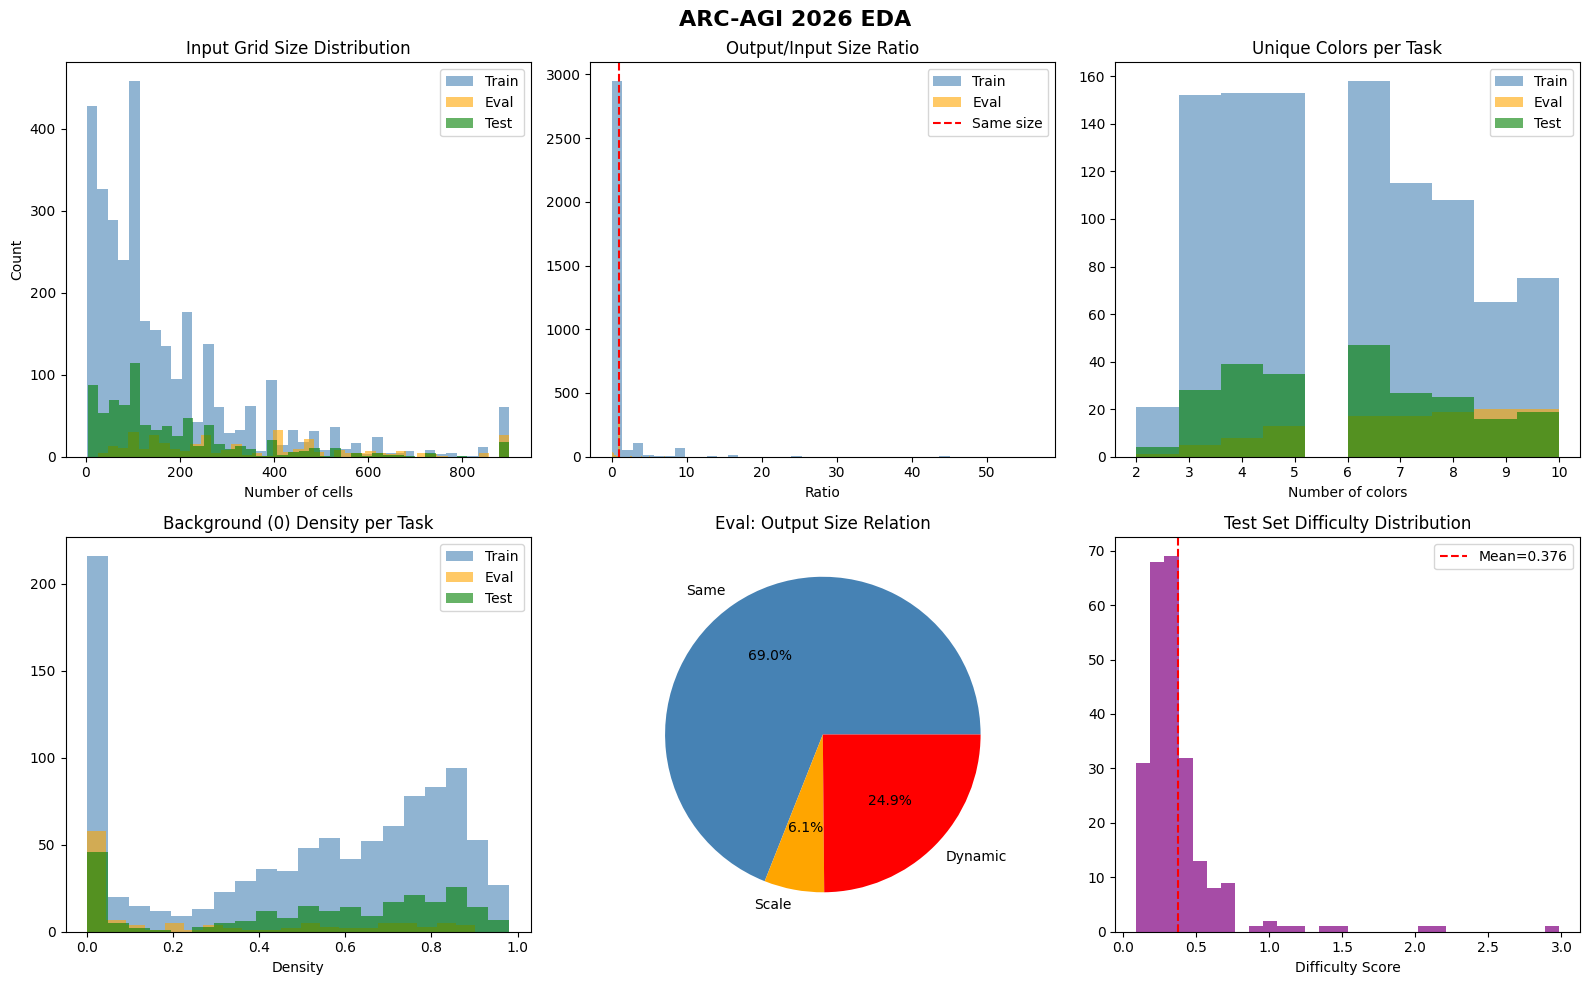

Saved: arc_eda.png


In [11]:
# ============================================================
# SECTION 7: VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('ARC-AGI 2026 EDA', fontsize=16, fontweight='bold')

# 1. Input size distribution
ax = axes[0, 0]
ax.hist(train_stats['input_cells'], bins=40, alpha=0.6, label='Train', color='steelblue')
ax.hist(eval_stats['input_cells'],  bins=40, alpha=0.6, label='Eval',  color='orange')
ax.hist(test_stats['input_cells'],  bins=40, alpha=0.6, label='Test',  color='green')
ax.set_title('Input Grid Size Distribution')
ax.set_xlabel('Number of cells')
ax.set_ylabel('Count')
ax.legend()

# 2. Output/Input ratio
ax = axes[0, 1]
train_ratios = [o/max(i,1) for i,o in zip(train_stats['input_cells'], train_stats['output_cells'])]
eval_ratios  = [o/max(i,1) for i,o in zip(eval_stats['input_cells'],  eval_stats['output_cells'])]
ax.hist(train_ratios, bins=40, alpha=0.6, label='Train', color='steelblue')
ax.hist(eval_ratios,  bins=40, alpha=0.6, label='Eval',  color='orange')
ax.axvline(1.0, color='red', linestyle='--', label='Same size')
ax.set_title('Output/Input Size Ratio')
ax.set_xlabel('Ratio')
ax.legend()

# 3. Unique colors per task
ax = axes[0, 2]
ax.hist(train_stats['unique_colors_per_task'], bins=10, alpha=0.6, label='Train', color='steelblue')
ax.hist(eval_stats['unique_colors_per_task'],  bins=10, alpha=0.6, label='Eval',  color='orange')
ax.hist(test_stats['unique_colors_per_task'],  bins=10, alpha=0.6, label='Test',  color='green')
ax.set_title('Unique Colors per Task')
ax.set_xlabel('Number of colors')
ax.legend()

# 4. Background density
ax = axes[1, 0]
ax.hist(train_stats['bg_density_per_task'], bins=20, alpha=0.6, label='Train', color='steelblue')
ax.hist(eval_stats['bg_density_per_task'],  bins=20, alpha=0.6, label='Eval',  color='orange')
ax.hist(test_stats['bg_density_per_task'],  bins=20, alpha=0.6, label='Test',  color='green')
ax.set_title('Background (0) Density per Task')
ax.set_xlabel('Density')
ax.legend()

# 5. Size relation pie
ax = axes[1, 1]
rel_counts = Counter(eval_stats['size_relation'])
ax.pie(
    [rel_counts['same'], rel_counts['scale'], rel_counts['dynamic']],
    labels=['Same', 'Scale', 'Dynamic'],
    autopct='%1.1f%%',
    colors=['steelblue', 'orange', 'red']
)
ax.set_title('Eval: Output Size Relation')

# 6. Difficulty score distribution (test set)
ax = axes[1, 2]
diff_scores = [v['score'] for v in test_difficulties.values()]
ax.hist(diff_scores, bins=30, color='purple', alpha=0.7)
ax.axvline(np.mean(diff_scores), color='red', linestyle='--', label=f'Mean={np.mean(diff_scores):.3f}')
ax.set_title('Test Set Difficulty Distribution')
ax.set_xlabel('Difficulty Score')
ax.legend()

plt.tight_layout()
plt.savefig('arc_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: arc_eda.png")

In [12]:
# ============================================================
# SECTION 8: BIMODAL ANALYSIS + RATIO DEEP DIVE
# ============================================================

# Test set এ BG density দিয়ে দুই cluster
test_bg_densities = {}
for key in test_challenges:
    train = test_challenges[key]['train']
    all_px = []
    for x in train:
        all_px.extend(np.array(x['input']).flatten().tolist())
    bg = np.mean(np.array(all_px) == 0)
    test_bg_densities[key] = bg

dense_puzzles  = {k: v for k, v in test_bg_densities.items() if v < 0.3}
sparse_puzzles = {k: v for k, v in test_bg_densities.items() if v >= 0.7}
mid_puzzles    = {k: v for k, v in test_bg_densities.items() 
                  if 0.3 <= v < 0.7}

print("=== BG DENSITY CLUSTERS (Test Set) ===")
print(f"Dense  (BG < 30%):  {len(dense_puzzles)} puzzles")
print(f"Mid    (30-70%):    {len(mid_puzzles)} puzzles")
print(f"Sparse (BG > 70%):  {len(sparse_puzzles)} puzzles")

# Ratio distribution detail
print("\n=== SIZE RATIO DETAIL (Test Set) ===")
all_ratios = []
extreme_ratio_puzzles = []
for key in test_challenges:
    train = test_challenges[key]['train']
    for x in train:
        in_s  = np.prod(np.shape(x['input']))
        out_s = np.prod(np.shape(x['output']))
        r = max(in_s, out_s) / max(min(in_s, out_s), 1)
        all_ratios.append(r)
        if r > 10:
            extreme_ratio_puzzles.append((key, r))

print(f"Ratio = 1.0 exactly:  {sum(1 for r in all_ratios if r==1.0)}")
print(f"Ratio 1.0-2.0:        {sum(1 for r in all_ratios if 1<r<=2)}")
print(f"Ratio 2.0-5.0:        {sum(1 for r in all_ratios if 2<r<=5)}")
print(f"Ratio 5.0-10.0:       {sum(1 for r in all_ratios if 5<r<=10)}")
print(f"Ratio > 10:           {sum(1 for r in all_ratios if r>10)}")
print(f"Ratio > 30:           {sum(1 for r in all_ratios if r>30)}")
print(f"Ratio > 50:           {sum(1 for r in all_ratios if r>50)}")

# Max output size — DFS কতটা token generate করতে হবে
print("\n=== MAX OUTPUT SIZE (Test Set) ===")
output_sizes = []
for key in test_challenges:
    for x in test_challenges[key]['train']:
        output_sizes.append(np.prod(np.shape(x['output'])))

print(f"Avg output cells:  {np.mean(output_sizes):.1f}")
print(f"Max output cells:  {max(output_sizes)}")
print(f"Output > 500:      {sum(1 for s in output_sizes if s>500)}")
print(f"Output > 800:      {sum(1 for s in output_sizes if s>800)}")
print(f"Output = 900:      {sum(1 for s in output_sizes if s==900)}")

# Train examples distribution
print("\n=== TRAIN EXAMPLES COUNT (Test Set) ===")
n_examples = [len(test_challenges[k]['train']) for k in test_challenges]
for n in sorted(set(n_examples)):
    print(f"  {n} examples: {n_examples.count(n)} puzzles")

# Test queries per puzzle
print("\n=== TEST QUERIES PER PUZZLE (Test Set) ===")
n_queries = [len(test_challenges[k]['test']) for k in test_challenges]
for n in sorted(set(n_queries)):
    print(f"  {n} query:    {n_queries.count(n)} puzzles")

=== BG DENSITY CLUSTERS (Test Set) ===
Dense  (BG < 30%):  61 puzzles
Mid    (30-70%):    67 puzzles
Sparse (BG > 70%):  112 puzzles

=== SIZE RATIO DETAIL (Test Set) ===
Ratio = 1.0 exactly:  519
Ratio 1.0-2.0:        17
Ratio 2.0-5.0:        102
Ratio 5.0-10.0:       62
Ratio > 10:           67
Ratio > 30:           27
Ratio > 50:           14

=== MAX OUTPUT SIZE (Test Set) ===
Avg output cells:  148.8
Max output cells:  900
Output > 500:      41
Output > 800:      14
Output = 900:      13

=== TRAIN EXAMPLES COUNT (Test Set) ===
  2 examples: 45 puzzles
  3 examples: 132 puzzles
  4 examples: 43 puzzles
  5 examples: 14 puzzles
  6 examples: 4 puzzles
  7 examples: 1 puzzles
  8 examples: 1 puzzles

=== TEST QUERIES PER PUZZLE (Test Set) ===
  1 query:    223 puzzles
  2 query:    15 puzzles
  3 query:    2 puzzles


In [13]:
# ============================================================
# SECTION 9: MULTI-QUERY + 2-EXAMPLE PUZZLE ANALYSIS
# ============================================================

print("=== MULTI-QUERY PUZZLES (Test Set) ===")
print(f"{'Key':<15} {'Queries':>8} {'Train':>6} "
      f"{'AvgSize':>8} {'Dynamic':>8} {'MaxRatio':>9}")
print("-" * 60)

multi_query = {
    k: v for k, v in test_challenges.items()
    if len(v['test']) > 1
}
for key, puzzle in sorted(
    multi_query.items(),
    key=lambda x: len(x[1]['test']),
    reverse=True
):
    train = puzzle['train']
    n_q   = len(puzzle['test'])
    n_tr  = len(train)
    avg_s = np.mean([np.prod(np.shape(x['input'])) for x in train])
    ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    is_dyn = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )
    print(f"{key:<15} {n_q:>8} {n_tr:>6} "
          f"{avg_s:>8.1f} {str(is_dyn):>8} {max(ratios):>9.2f}")

print(f"\nTotal multi-query puzzles: {len(multi_query)}")
print(f"Total extra points possible: "
      f"{sum(len(v['test'])-1 for v in multi_query.values())}")

# 2-example puzzle analysis
print("\n=== 2-EXAMPLE PUZZLES — TTT Risk (Test Set) ===")
two_ex = {k: v for k, v in test_challenges.items()
          if len(v['train']) == 2}
print(f"Total: {len(two_ex)} puzzles")

dynamic_2ex = sum(
    1 for v in two_ex.values()
    if any(np.shape(x['input']) != np.shape(x['output'])
           for x in v['train'])
)
print(f"Dynamic + 2 examples: {dynamic_2ex} (hardest for TTT)")
print(f"Static  + 2 examples: {len(two_ex)-dynamic_2ex}")

# Difficulty score of 2-example puzzles
scores_2ex = [
    test_difficulties[k]['score']
    for k in two_ex if k in test_difficulties
]
print(f"Avg difficulty score: {np.mean(scores_2ex):.4f}")
print(f"Max difficulty score: {max(scores_2ex):.4f}")

=== MULTI-QUERY PUZZLES (Test Set) ===
Key              Queries  Train  AvgSize  Dynamic  MaxRatio
------------------------------------------------------------
27a28665               3      7      9.0     True      9.00
3cd86f4f               3      3     33.3     True      2.50
12997ef3               2      4    121.0     True      6.72
17b866bd               2      2    296.0    False      1.00
1be83260               2      2    364.0     True      2.67
1d398264               2      3    241.7    False      1.00
239be575               2      6     37.0     True     42.00
25c199f5               2      5     85.0     True      3.40
25ff71a9               2      4      9.0    False      1.00
2b9ef948               2      3    700.0    False      1.00
2ccd9fef               2      2    247.5     True      3.00
31d5ba1a               2      5     30.0     True      2.00
320afe60               2      3    454.7    False      1.00
337b420f               2      4     85.0     True      3.40


In [14]:
# ============================================================
# SECTION 10: RULE-BASED SOLVER COVERAGE ANALYSIS
# ============================================================
import numpy as np
from itertools import product

def grids_equal(a, b):
    a, b = np.array(a), np.array(b)
    return a.shape == b.shape and np.array_equal(a, b)

# ── Rule 1: Tiling (output = input repeated NxM times) ──────
def check_tiling(train):
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        ih, iw = inp.shape
        oh, ow = out.shape
        if oh % ih != 0 or ow % iw != 0:
            return False
        ry, rx = oh // ih, ow // iw
        if ry == 1 and rx == 1:
            return False  # same size না, আসল tiling না
        tiled = np.tile(inp, (ry, rx))
        if not np.array_equal(tiled, out):
            # mirrored tiling ও try করো
            found = False
            for fy in [1, -1]:
                for fx in [1, -1]:
                    test = inp[::fy, ::fx]
                    test_tiled = np.tile(test, (ry, rx))
                    if np.array_equal(test_tiled, out):
                        found = True
                        break
            if not found:
                return False
    return True

# ── Rule 2: Identity/Same (output == input) ──────────────────
def check_identity(train):
    return all(grids_equal(ex['input'], ex['output']) for ex in train)

# ── Rule 3: Color mapping (consistent pixel-wise color swap) ─
def check_color_mapping(train):
    mapping = {}
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        if inp.shape != out.shape:
            return False
        for iv, ov in zip(inp.flatten(), out.flatten()):
            iv, ov = int(iv), int(ov)
            if iv in mapping and mapping[iv] != ov:
                return False
            mapping[iv] = ov
    return True

# ── Rule 4: Rotation/Flip (whole-grid geometric transform) ───
def check_rotation_flip(train):
    transforms = [
        lambda x: np.rot90(x, 1),
        lambda x: np.rot90(x, 2),
        lambda x: np.rot90(x, 3),
        lambda x: np.fliplr(x),
        lambda x: np.flipud(x),
        lambda x: x.T,
        lambda x: np.rot90(x.T, 1),
        lambda x: np.rot90(x.T, 2),
    ]
    for t in transforms:
        if all(
            np.shape(t(np.array(ex['input']))) == np.shape(ex['output']) and
            np.array_equal(t(np.array(ex['input'])), ex['output'])
            for ex in train
        ):
            return True
    return False

# ── Rule 5: Border/crop (output = consistent crop of input) ──
def check_crop(train):
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        ih, iw = inp.shape
        oh, ow = out.shape
        if oh > ih or ow > iw:
            return False
        found = False
        for y in range(ih - oh + 1):
            for x in range(iw - ow + 1):
                if np.array_equal(inp[y:y+oh, x:x+ow], out):
                    found = True
                    break
            if found:
                break
        if not found:
            return False
    return True

# ── Rule 6: Scale up (each cell repeated as block) ────────────
def check_scale_block(train):
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        ih, iw = inp.shape
        oh, ow = out.shape
        if oh % ih != 0 or ow % iw != 0:
            return False
        sy, sx = oh // ih, ow // iw
        if sy == 1 and sx == 1:
            return False
        expected = np.kron(inp, np.ones((sy, sx), dtype=inp.dtype))
        if not np.array_equal(expected, out):
            return False
    return True


RULES = {
    'identity':      check_identity,
    'color_mapping':  check_color_mapping,
    'rotation_flip':  check_rotation_flip,
    'tiling':         check_tiling,
    'scale_block':    check_scale_block,
    'crop':           check_crop,
}

print("=== RULE-BASED SOLVER COVERAGE (Test Set) ===\n")

solved_by_rule = {}
solved_keys = set()

for key, puzzle in test_challenges.items():
    train = puzzle['train']
    for rule_name, rule_fn in RULES.items():
        try:
            if rule_fn(train):
                solved_by_rule.setdefault(rule_name, []).append(key)
                solved_keys.add(key)
                break  # প্রথম match হলে থামো
        except Exception:
            continue

total_solved = len(solved_keys)
print(f"Total puzzles solvable by simple rules: {total_solved} / {len(test_challenges)} "
      f"({total_solved/len(test_challenges)*100:.1f}%)\n")

for rule_name, keys in solved_by_rule.items():
    print(f"  {rule_name:<15}: {len(keys)} puzzles")
    print(f"    examples: {keys[:5]}")

print(f"\nNOT solvable by simple rules: {len(test_challenges) - total_solved} puzzles")

=== RULE-BASED SOLVER COVERAGE (Test Set) ===

Total puzzles solvable by simple rules: 19 / 240 (7.9%)

  crop           : 17 puzzles
    examples: ['0b148d64', '1190e5a7', '1a2e2828', '1a6449f1', '1c786137']
  color_mapping  : 1 puzzles
    examples: ['0d3d703e']
  rotation_flip  : 1 puzzles
    examples: ['3c9b0459']

NOT solvable by simple rules: 221 puzzles


In [15]:
# ============================================================
# SECTION 11: VERIFY RULE ACCURACY ON TRAINING SET (sanity check)
# ============================================================
# Training set এ solution আছে, তাই rule যেটা বলে সেটা সত্যিই
# সঠিক উত্তর দেয় কিনা যাচাই করা যায়

print("=== RULE ACCURACY VERIFICATION (Training Set) ===\n")

def apply_rule_to_test(key, puzzle, rule_name):
    """rule অনুযায়ী test query এর output predict করো"""
    train = puzzle['train']
    test_input = np.array(puzzle['test'][0]['input'])

    if rule_name == 'identity':
        return test_input

    elif rule_name == 'color_mapping':
        mapping = {}
        for ex in train:
            inp, out = np.array(ex['input']), np.array(ex['output'])
            for iv, ov in zip(inp.flatten(), out.flatten()):
                mapping[int(iv)] = int(ov)
        result = np.copy(test_input)
        for iv, ov in mapping.items():
            result[test_input == iv] = ov
        return result

    elif rule_name == 'rotation_flip':
        transforms = {
            'rot90': lambda x: np.rot90(x, 1),
            'rot180': lambda x: np.rot90(x, 2),
            'rot270': lambda x: np.rot90(x, 3),
            'fliplr': lambda x: np.fliplr(x),
            'flipud': lambda x: np.flipud(x),
            'transpose': lambda x: x.T,
        }
        for name, t in transforms.items():
            if all(
                np.shape(t(np.array(ex['input']))) == np.shape(ex['output']) and
                np.array_equal(t(np.array(ex['input'])), ex['output'])
                for ex in train
            ):
                return t(test_input)
        return None

    elif rule_name == 'tiling':
        ex = train[0]
        ih, iw = np.shape(ex['input'])
        oh, ow = np.shape(ex['output'])
        ry, rx = oh // ih, ow // iw
        th, tw = test_input.shape
        return np.tile(test_input, (ry, rx))

    elif rule_name == 'scale_block':
        ex = train[0]
        ih, iw = np.shape(ex['input'])
        oh, ow = np.shape(ex['output'])
        sy, sx = oh // ih, ow // iw
        return np.kron(test_input, np.ones((sy, sx), dtype=test_input.dtype))

    elif rule_name == 'crop':
        ex = train[0]
        inp, out = np.array(ex['input']), np.array(ex['output'])
        oh, ow = out.shape
        ih, iw = inp.shape
        for y in range(ih - oh + 1):
            for x in range(iw - ow + 1):
                if np.array_equal(inp[y:y+oh, x:x+ow], out):
                    th, tw = test_input.shape
                    return test_input[y:y+oh, x:x+ow] if y+oh<=th and x+ow<=tw else None
        return None

    return None


correct, wrong, skipped = 0, 0, 0

for key in train_challenges:
    puzzle = train_challenges[key]
    train = puzzle['train']

    matched_rule = None
    for rule_name, rule_fn in RULES.items():
        try:
            if rule_fn(train):
                matched_rule = rule_name
                break
        except Exception:
            continue

    if matched_rule is None:
        continue

    try:
        predicted = apply_rule_to_test(key, puzzle, matched_rule)
        actual = np.array(train_solutions[key][0])
        if predicted is None:
            skipped += 1
        elif np.array_equal(predicted, actual):
            correct += 1
        else:
            wrong += 1
    except Exception:
        skipped += 1

total_checked = correct + wrong + skipped
print(f"Training puzzles matched by rule: {total_checked}")
print(f"  Correct:  {correct} ({correct/max(total_checked,1)*100:.1f}%)")
print(f"  Wrong:    {wrong} ({wrong/max(total_checked,1)*100:.1f}%)")
print(f"  Skipped:  {skipped}")
print(f"\nRule reliability: {correct/max(correct+wrong,1)*100:.1f}% "
      f"(among non-skipped predictions)")

=== RULE ACCURACY VERIFICATION (Training Set) ===

Training puzzles matched by rule: 72
  Correct:  20 (27.8%)
  Wrong:    50 (69.4%)
  Skipped:  2

Rule reliability: 28.6% (among non-skipped predictions)


In [16]:
# ============================================================
# EVALUATION SET থেকে STABILITY-WEIGHTING টেস্টের জন্য
# উপযুক্ত ৮টি পাজল খোঁজা
# ============================================================
import json
import numpy as np
from collections import Counter

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json') as f:
    eval_challenges = json.load(f)

print(f"Total evaluation puzzles: {len(eval_challenges)}")
print()

# ── Feature 1: multi-query puzzle (একটার বেশি test query) ──
multi_query = {k: v for k, v in eval_challenges.items() if len(v['test']) > 1}
print(f"Multi-query puzzles: {len(multi_query)}")
for k, v in sorted(multi_query.items(), key=lambda x: len(x[1]['test']), reverse=True)[:10]:
    print(f"  {k}: {len(v['test'])} queries, {len(v['train'])} train examples")

print()

# ── Feature 2: difficulty score (আগের EDA formula দিয়ে) ──
def compute_difficulty(key, data):
    train = data[key]['train']
    avg_input_size = np.mean([np.prod(np.shape(x['input'])) for x in train])
    size_ratios = [
        max(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    avg_ratio = np.mean(size_ratios)
    max_ratio = max(size_ratios)
    n_colors = len(set(
        int(c) for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(np.shape(x['input']) != np.shape(x['output']) for x in train)
    score = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    return {
        'key': key, 'score': score, 'avg_size': avg_input_size,
        'max_ratio': max_ratio, 'n_colors': n_colors,
        'is_dynamic': is_dynamic, 'n_train': len(train),
        'n_test': len(data[key]['test']),
    }

all_difficulty = {k: compute_difficulty(k, eval_challenges) for k in eval_challenges}

# ── Feature 3: candidate diversity proxy ──
# stability weighting আসলে কাজ করে যখন output token length বড়,
# কারণ তখন augmentation এর মধ্যে বেশি disagreement হওয়ার সুযোগ থাকে
# (ছোট/সহজ output এ সব augmentation সহজেই agree করে — boring test case)

print("=== DIFFICULTY DISTRIBUTION (Evaluation Set) ===")
scores = [v['score'] for v in all_difficulty.values()]
print(f"Min: {min(scores):.3f}, Max: {max(scores):.3f}, Mean: {np.mean(scores):.3f}")
print()

# Easy, medium, hard থেকে প্রতিটি থেকে কিছু করে বেছে নেওয়া
sorted_by_score = sorted(all_difficulty.values(), key=lambda x: x['score'])
n = len(sorted_by_score)

easy_pool   = sorted_by_score[:n//3]
medium_pool = sorted_by_score[n//3:2*n//3]
hard_pool   = sorted_by_score[2*n//3:]

print(f"Easy pool: {len(easy_pool)}, Medium: {len(medium_pool)}, Hard: {len(hard_pool)}")
print()

# multi-query থাকা পাজল প্রতিটা pool থেকে preference দিয়ে বেছে নেওয়া
def pick_best(pool, n_pick, prefer_multi=True):
    pool_sorted = sorted(pool, key=lambda x: (not (x['n_test'] > 1 and prefer_multi), x['score']))
    return pool_sorted[:n_pick]

picks = []
picks += pick_best(easy_pool, 2)
picks += pick_best(medium_pool, 3)
picks += pick_best(hard_pool, 3)

print("=== SUGGESTED 8 PUZZLES FOR STABILITY-WEIGHTING TEST ===")
print(f"{'Key':<12} {'Tier':<8} {'Score':>7} {'Size':>6} {'Ratio':>6} {'Colors':>7} {'Dynamic':>8} {'nTrain':>7} {'nTest':>6}")
print("-" * 75)
tier_names = ['Easy']*2 + ['Medium']*3 + ['Hard']*3
for tier, p in zip(tier_names, picks):
    print(f"{p['key']:<12} {tier:<8} {p['score']:>7.3f} {p['avg_size']:>6.0f} "
          f"{p['max_ratio']:>6.2f} {p['n_colors']:>7} {str(p['is_dynamic']):>8} "
          f"{p['n_train']:>7} {p['n_test']:>6}")

print()
print("DEBUG_PUZZLES = [")
for p in picks:
    print(f'    "{p["key"]}",')
print("]")

Total evaluation puzzles: 120

Multi-query puzzles: 49
  1ae2feb7: 3 queries, 3 train examples
  b6f77b65: 3 queries, 5 train examples
  d35bdbdc: 3 queries, 3 train examples
  13e47133: 2 queries, 3 train examples
  142ca369: 2 queries, 3 train examples
  16de56c4: 2 queries, 3 train examples
  195c6913: 2 queries, 3 train examples
  20270e3b: 2 queries, 4 train examples
  20a9e565: 2 queries, 3 train examples
  21897d95: 2 queries, 4 train examples

=== DIFFICULTY DISTRIBUTION (Evaluation Set) ===
Min: 0.113, Max: 1.818, Mean: 0.408

Easy pool: 40, Medium: 40, Hard: 40

=== SUGGESTED 8 PUZZLES FOR STABILITY-WEIGHTING TEST ===
Key          Tier       Score   Size  Ratio  Colors  Dynamic  nTrain  nTest
---------------------------------------------------------------------------
36a08778     Easy       0.113    158   1.00       3    False       6      2
dd6b8c4b     Easy       0.140    121   1.00       5    False       3      2
9385bd28     Medium     0.256    168   1.00      10    False

In [17]:
# ================================================================
# SECTION 10: OBJECT / COMPONENT ANALYSIS (FIXED)
# ================================================================
from scipy import ndimage

def count_objects_and_sizes(grid):
    """
    Count connected non-zero components and their sizes.
    Returns: (num_objects, list_of_sizes)
    """
    if grid.size == 0:
        return 0, []
    # 4-connectivity (up, down, left, right)
    labeled, num_features = ndimage.label(grid > 0, structure=np.array([[0,1,0],[1,1,1],[0,1,0]]))
    if num_features == 0:
        return 0, []
    sizes = [np.sum(labeled == i) for i in range(1, num_features+1)]
    return num_features, sizes

def get_object_features(puzzle):
    train = puzzle['train']
    obj_counts_in = []
    obj_counts_out = []
    all_obj_sizes = []
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        n_in, sizes_in = count_objects_and_sizes(inp)
        n_out, sizes_out = count_objects_and_sizes(out)
        obj_counts_in.append(n_in)
        obj_counts_out.append(n_out)
        all_obj_sizes.extend(sizes_in)
        all_obj_sizes.extend(sizes_out)
    return {
        'avg_input_objects': np.mean(obj_counts_in) if obj_counts_in else 0,
        'avg_output_objects': np.mean(obj_counts_out) if obj_counts_out else 0,
        'object_delta': np.mean([o - i for i, o in zip(obj_counts_in, obj_counts_out)]) if obj_counts_in else 0,
        'avg_obj_size': np.mean(all_obj_sizes) if all_obj_sizes else 0
    }

print("\n" + "=" * 55)
print("  OBJECT ANALYSIS (Evaluation Set)")
print("=" * 55)

obj_stats = []
for key in eval_challenges:
    feat = get_object_features(eval_challenges[key])
    obj_stats.append(feat)

print(f"Avg Input Objects/Task:  {np.mean([s['avg_input_objects'] for s in obj_stats]):.2f}")
print(f"Avg Output Objects/Task: {np.mean([s['avg_output_objects'] for s in obj_stats]):.2f}")
print(f"Avg Object Delta (Out-In): {np.mean([s['object_delta'] for s in obj_stats]):.2f}")
print(f"Avg Object Size:         {np.mean([s['avg_obj_size'] for s in obj_stats]):.2f} cells")

# Connection with difficulty
high_obj = [s['avg_input_objects'] for s in obj_stats if s['avg_input_objects'] > 3]
print(f"\nTasks with >3 input objects: {len(high_obj)} ({(len(high_obj)/len(obj_stats)*100):.1f}%)")


  OBJECT ANALYSIS (Evaluation Set)
Avg Input Objects/Task:  5.55
Avg Output Objects/Task: 5.22
Avg Object Delta (Out-In): -0.32
Avg Object Size:         207.30 cells

Tasks with >3 input objects: 43 (35.8%)


In [18]:
# ================================================================
# SECTION 11: SYMMETRY ANALYSIS
# ================================================================

def is_symmetric(grid):
    """Check if grid is horizontally or vertically symmetric."""
    if grid.size == 0:
        return False
    h_sym = np.all(grid == np.flip(grid, axis=1))
    v_sym = np.all(grid == np.flip(grid, axis=0))
    return h_sym or v_sym

sym_inputs = []
sym_outputs = []
dynamic_sym_count = 0

for key in eval_challenges:
    for ex in eval_challenges[key]['train']:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        sym_inputs.append(1 if is_symmetric(inp) else 0)
        sym_outputs.append(1 if is_symmetric(out) else 0)
    # Check if output is symmetric but input is NOT (model must create symmetry)
    first_inp = np.array(eval_challenges[key]['train'][0]['input'])
    first_out = np.array(eval_challenges[key]['train'][0]['output'])
    if is_symmetric(first_out) and not is_symmetric(first_inp):
        dynamic_sym_count += 1

print("\n" + "=" * 55)
print("  SYMMETRY ANALYSIS (Evaluation Set)")
print("=" * 55)
print(f"Symmetric Input grids:  {sum(sym_inputs)}/{len(sym_inputs)} ({sum(sym_inputs)/len(sym_inputs)*100:.1f}%)")
print(f"Symmetric Output grids: {sum(sym_outputs)}/{len(sym_outputs)} ({sum(sym_outputs)/len(sym_outputs)*100:.1f}%)")
print(f"Tasks where Output is Symmetric but Input is NOT: {dynamic_sym_count}")
print("(এই পাজলগুলোতে মডেলকে 'নতুন সিমেট্রি' তৈরি করতে হয়—এগুলো তুলনামূলক কঠিন)")


  SYMMETRY ANALYSIS (Evaluation Set)
Symmetric Input grids:  11/358 (3.1%)
Symmetric Output grids: 42/358 (11.7%)
Tasks where Output is Symmetric but Input is NOT: 8
(এই পাজলগুলোতে মডেলকে 'নতুন সিমেট্রি' তৈরি করতে হয়—এগুলো তুলনামূলক কঠিন)



  FEATURE CORRELATION WITH DIFFICULTY SCORE
  input_size : +0.622
       ratio : +0.876
      colors : +0.296
  bg_density : -0.207
  n_examples : -0.164
  is_dynamic : +0.605


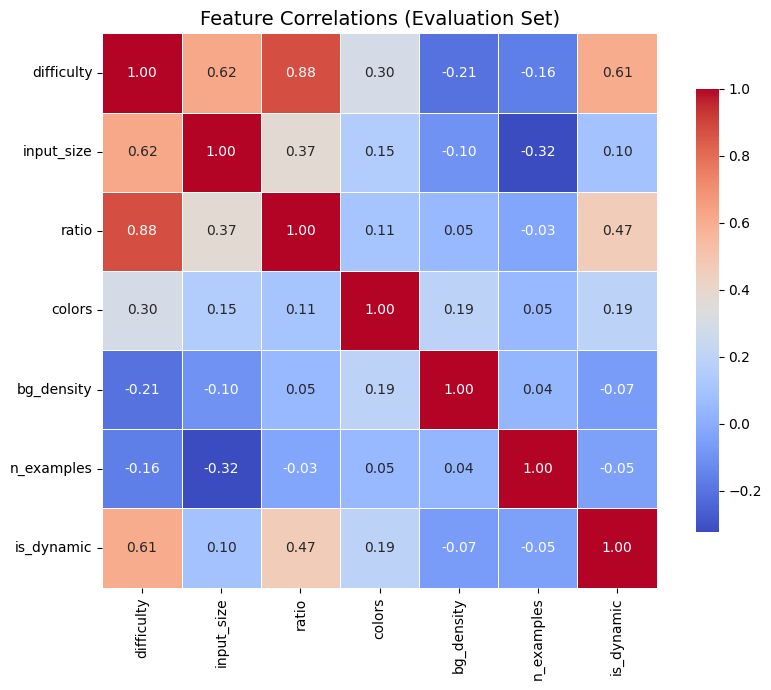

In [19]:
# ================================================================
# SECTION 12: FEATURE CORRELATION MATRIX
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compute_eval_features(key, data):
    puzzle = data[key]
    train = puzzle['train']
    
    avg_input_size = np.mean([np.prod(np.shape(x['input'])) for x in train])
    
    size_ratios = []
    for x in train:
        in_s = np.prod(np.shape(x['input']))
        out_s = np.prod(np.shape(x['output']))
        size_ratios.append(max(in_s, out_s) / max(min(in_s, out_s), 1))
    avg_ratio = np.mean(size_ratios)
    
    all_colors = set()
    all_px = []
    for x in train:
        all_colors.update(np.unique(x['input']).tolist())
        all_colors.update(np.unique(x['output']).tolist())
        all_px.extend(np.array(x['input']).flatten().tolist())
    
    n_colors = len(all_colors)
    bg_density = np.mean(np.array(all_px) == 0)
    n_examples = len(train)
    is_dynamic = any(np.shape(x['input']) != np.shape(x['output']) for x in train)
    
    # Difficulty score (same formula used in Section 3)
    score = (
        avg_input_size / 900 * 0.25 +
        (avg_ratio - 1) / 10 * 0.20 +
        n_colors / 10 * 0.20 +
        (1 - bg_density) * 0.15 +
        (1 / n_examples) * 0.10 +
        (0.10 if is_dynamic else 0)
    )
    
    return {
        'difficulty': score,
        'input_size': avg_input_size,
        'ratio': avg_ratio,
        'colors': n_colors,
        'bg_density': bg_density,
        'n_examples': n_examples,
        'is_dynamic': 1 if is_dynamic else 0
    }

# Collect features for all evaluation tasks
feature_list = []
for key in eval_challenges:
    feature_list.append(compute_eval_features(key, eval_challenges))

df = pd.DataFrame(feature_list)
corr = df.corr()

print("\n" + "=" * 55)
print("  FEATURE CORRELATION WITH DIFFICULTY SCORE")
print("=" * 55)
for col in ['input_size', 'ratio', 'colors', 'bg_density', 'n_examples', 'is_dynamic']:
    print(f"{col:>12} : {corr.loc['difficulty', col]:+.3f}")

# Plot heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, 
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlations (Evaluation Set)', fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# ================================================================
# SECTION 13: COLOR TRANSITION MATRIX
# ================================================================

from collections import defaultdict

color_pairs = defaultdict(int)
color_names = {
    0: 'BG', 1: 'Blue', 2: 'Red', 3: 'Green', 4: 'Yellow',
    5: 'Grey', 6: 'Magenta', 7: 'Orange', 8: 'Azure', 9: 'Maroon'
}

for key in eval_challenges:
    for ex in eval_challenges[key]['train']:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        in_colors = set(np.unique(inp).tolist())
        out_colors = set(np.unique(out).tolist())
        for c_in in in_colors:
            for c_out in out_colors:
                color_pairs[(c_in, c_out)] += 1

print("\n" + "=" * 55)
print("  COLOR TRANSITION MATRIX (Top 10)")
print("=" * 55)
for (c_in, c_out), count in sorted(color_pairs.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {color_names[c_in]} → {color_names[c_out]}: {count:>4} times")

# Rare transitions (occur less than 3 times)
rare = [(c_in, c_out) for (c_in, c_out), count in color_pairs.items() if count < 3]
print(f"\n⚠️ Rare color transitions (<3 occurrences): {len(rare)} pairs")
if rare:
    print("  উদাহরণ:", ', '.join([f"{color_names[a]}→{color_names[b]}" for a,b in rare[:8]]))

# Find which puzzles contain the rarest transition
print("\n🔍 পাজল যাদের মধ্যে সবচেয়ে বিরল ট্রানজিশন আছে (শুধু ১ বার):")
single_occurrence = [pair for pair, count in color_pairs.items() if count == 1]
for c_in, c_out in single_occurrence[:5]:
    print(f"  {color_names[c_in]} → {color_names[c_out]}")


  COLOR TRANSITION MATRIX (Top 10)
  Blue → Blue:  211 times
  Red → Red:  208 times
  Yellow → Yellow:  198 times
  Green → Green:  188 times
  Azure → Azure:  181 times
  Blue → Red:  164 times
  Red → Blue:  155 times
  Yellow → Blue:  154 times
  Yellow → Red:  154 times
  Blue → Green:  152 times

⚠️ Rare color transitions (<3 occurrences): 0 pairs

🔍 পাজল যাদের মধ্যে সবচেয়ে বিরল ট্রানজিশন আছে (শুধু ১ বার):


In [21]:
# ================================================================
# EXTENDED EDA — FAILURE ANALYSIS & COLOR CO-OCCURRENCE
# ================================================================

import json
import numpy as np
from collections import Counter, defaultdict

# Load datasets
with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json') as f:
    eval_data = json.load(f)

with open('/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_solutions.json') as f:
    eval_solutions = json.load(f)

# Your solved/unsolved list (from diagnostic summary — update manually or parse)
# For now, simulate with a placeholder — replace with actual data
SOLVED = ["0934a4d8", "36a08778", "981571dc", "aa4ec2a5"]  # update from your run
UNSOLVED = ["7b0280bc", "65b59efc", "3e6067c3"]            # update from your run

# ----------------------------------------------------------------
# FEATURE 1: Compare Solved vs Unsolved Characteristics
# ----------------------------------------------------------------
print("=" * 80)
print("FAILURE ANALYSIS: SOLVED vs UNSOLVED")
print("=" * 80)

def get_features(key, data):
    puzzle = data[key]
    train = puzzle['train']
    n_train = len(train)
    avg_input = np.mean([np.prod(np.shape(x['input'])) for x in train])
    avg_output = np.mean([np.prod(np.shape(x['output'])) for x in train])
    ratio = avg_output / max(avg_input, 1)
    is_dynamic = any(np.shape(x['input']) != np.shape(x['output']) for x in train)
    colors = set()
    for x in train:
        colors.update(np.unique(x['input']).tolist())
        colors.update(np.unique(x['output']).tolist())
    n_colors = len(colors)
    return {
        'n_train': n_train,
        'avg_input': avg_input,
        'avg_output': avg_output,
        'ratio': ratio,
        'is_dynamic': is_dynamic,
        'n_colors': n_colors
    }

solved_features = [get_features(k, eval_data) for k in SOLVED if k in eval_data]
unsolved_features = [get_features(k, eval_data) for k in UNSOLVED if k in eval_data]

print("\n[SOLVED PUZZLES]")
if solved_features:
    print(f"  Avg n_train: {np.mean([f['n_train'] for f in solved_features]):.1f}")
    print(f"  Avg input size: {np.mean([f['avg_input'] for f in solved_features]):.1f}")
    print(f"  Avg ratio: {np.mean([f['ratio'] for f in solved_features]):.2f}")
    print(f"  Dynamic: {sum(1 for f in solved_features if f['is_dynamic'])}/{len(solved_features)}")
    print(f"  Avg colors: {np.mean([f['n_colors'] for f in solved_features]):.1f}")

print("\n[UNSOLVED PUZZLES]")
if unsolved_features:
    print(f"  Avg n_train: {np.mean([f['n_train'] for f in unsolved_features]):.1f}")
    print(f"  Avg input size: {np.mean([f['avg_input'] for f in unsolved_features]):.1f}")
    print(f"  Avg ratio: {np.mean([f['ratio'] for f in unsolved_features]):.2f}")
    print(f"  Dynamic: {sum(1 for f in unsolved_features if f['is_dynamic'])}/{len(unsolved_features)}")
    print(f"  Avg colors: {np.mean([f['n_colors'] for f in unsolved_features]):.1f}")

# ----------------------------------------------------------------
# FEATURE 2: Color Co-occurrence Analysis
# ----------------------------------------------------------------
print("\n" + "=" * 80)
print("COLOR CO-OCCURRENCE ANALYSIS")
print("=" * 80)

color_pairs = defaultdict(int)
color_names = {
    0: 'Black', 1: 'Blue', 2: 'Red', 3: 'Green', 4: 'Yellow',
    5: 'Grey', 6: 'Magenta', 7: 'Orange', 8: 'Azure', 9: 'Maroon'
}

for key, puzzle in eval_data.items():
    for ex in puzzle['train']:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        in_colors = set(np.unique(inp).tolist())
        out_colors = set(np.unique(out).tolist())
        for c_in in in_colors:
            for c_out in out_colors:
                color_pairs[(c_in, c_out)] += 1

# Top 10 most frequent color transitions
print("\nTop 10 most frequent color transitions (Input → Output):")
for (c_in, c_out), count in sorted(color_pairs.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {color_names[c_in]} → {color_names[c_out]}: {count} times")

# Rare transitions (less than 5 occurrences)
rare = [(c_in, c_out) for (c_in, c_out), count in color_pairs.items() if count < 5]
print(f"\nRare color transitions (<5 occurrences): {len(rare)} pairs")
print("  (These might be harder for the model to learn)")

print("=" * 80)

FAILURE ANALYSIS: SOLVED vs UNSOLVED

[SOLVED PUZZLES]
  Avg n_train: 4.2
  Avg input size: 616.0
  Avg ratio: 0.76
  Dynamic: 1/4
  Avg colors: 6.8

[UNSOLVED PUZZLES]
  Avg n_train: 3.0
  Avg input size: 310.7
  Avg ratio: 1.24
  Dynamic: 1/3
  Avg colors: 9.7

COLOR CO-OCCURRENCE ANALYSIS

Top 10 most frequent color transitions (Input → Output):
  Blue → Blue: 211 times
  Red → Red: 208 times
  Yellow → Yellow: 198 times
  Green → Green: 188 times
  Azure → Azure: 181 times
  Blue → Red: 164 times
  Red → Blue: 155 times
  Yellow → Blue: 154 times
  Yellow → Red: 154 times
  Blue → Green: 152 times

Rare color transitions (<5 occurrences): 0 pairs
  (These might be harder for the model to learn)


In [22]:
# ================================================================
# SECTION 14: PATTERN REPETITION & TILING ANALYSIS
# ================================================================

def check_tiling(inp, out):
    """Check if output is a tiled version of input (or vice versa)."""
    if inp.size == 0 or out.size == 0:
        return False, 0, 0
    h_in, w_in = inp.shape
    h_out, w_out = out.shape
    
    # Check if out can be divided exactly by inp
    if h_out % h_in == 0 and w_out % w_in == 0:
        return True, h_out // h_in, w_out // w_in
    return False, 0, 0

tiling_tasks = []
for key in eval_challenges:
    ex = eval_challenges[key]['train'][0]
    inp = np.array(ex['input'])
    out = np.array(ex['output'])
    is_tile, h_mul, w_mul = check_tiling(inp, out)
    if is_tile and (h_mul > 1 or w_mul > 1):
        tiling_tasks.append((key, h_mul, w_mul))

print("\n" + "=" * 55)
print("  PATTERN REPETITION / TILING ANALYSIS")
print("=" * 55)
print(f"Tasks with tiling (output is multiplied input): {len(tiling_tasks)}")
if tiling_tasks:
    print("Examples:")
    for k, h, w in tiling_tasks[:10]:
        print(f"  {k}: Input scaled by ({h}x{w})")


  PATTERN REPETITION / TILING ANALYSIS
Tasks with tiling (output is multiplied input): 0


In [23]:
# ================================================================
# SECTION 15: OBJECT DELTA ANALYSIS (Movement & Scaling)
# ================================================================
from scipy.ndimage import center_of_mass, label

def get_object_deltas(inp, out):
    """Calculate centroid shift for the first major object."""
    if inp.size == 0 or out.size == 0:
        return None
    
    # Label objects in input and output
    labeled_in, n_in = label(inp > 0)
    labeled_out, n_out = label(out > 0)
    if n_in == 0 or n_out == 0:
        return None
    
    # Centroids
    com_in = center_of_mass(inp, labeled_in, range(1, n_in+1))
    com_out = center_of_mass(out, labeled_out, range(1, n_out+1))
    
    if not com_in or not com_out:
        return None
    
    # Average shift
    shift_x = np.mean([c[0] for c in com_out]) - np.mean([c[0] for c in com_in])
    shift_y = np.mean([c[1] for c in com_out]) - np.mean([c[1] for c in com_in])
    
    # Scale change (based on number of objects)
    scale_change = n_out / max(n_in, 1)
    
    return shift_x, shift_y, scale_change

deltas = []
for key in eval_challenges:
    ex = eval_challenges[key]['train'][0]
    inp = np.array(ex['input'])
    out = np.array(ex['output'])
    d = get_object_deltas(inp, out)
    if d:
        deltas.append(d)

print("\n" + "=" * 55)
print("  OBJECT DELTA ANALYSIS (Movement & Scale)")
print("=" * 55)
if deltas:
    shifts_x = [d[0] for d in deltas]
    shifts_y = [d[1] for d in deltas]
    scale_changes = [d[2] for d in deltas]
    print(f"Average centroid shift (X): {np.mean(shifts_x):.2f} pixels")
    print(f"Average centroid shift (Y): {np.mean(shifts_y):.2f} pixels")
    print(f"Avg Scale change (Out/In objects): {np.mean(scale_changes):.2f}")
    print(f"Tasks where scale changed significantly (>2x): {sum(1 for s in scale_changes if s > 2)}")


  OBJECT DELTA ANALYSIS (Movement & Scale)
Average centroid shift (X): -1.17 pixels
Average centroid shift (Y): -1.10 pixels
Avg Scale change (Out/In objects): 1.08
Tasks where scale changed significantly (>2x): 4


In [24]:
# ================================================================
# SECTION 16: INFORMATION DENSITY & ENTROPY
# ================================================================

def grid_entropy(grid):
    """Calculate Shannon entropy of color distribution."""
    if grid.size == 0:
        return 0
    counts = np.bincount(grid.flatten(), minlength=10)
    probs = counts[counts > 0] / grid.size
    return -np.sum(probs * np.log2(probs))

def info_density(grid):
    """Proportion of non-zero cells."""
    return np.mean(grid > 0)

info_stats = []
for key in eval_challenges:
    ex = eval_challenges[key]['train'][0]
    inp = np.array(ex['input'])
    out = np.array(ex['output'])
    info_stats.append({
        'input_density': info_density(inp),
        'output_density': info_density(out),
        'input_entropy': grid_entropy(inp),
        'output_entropy': grid_entropy(out)
    })

print("\n" + "=" * 55)
print("  INFORMATION DENSITY & ENTROPY")
print("=" * 55)
print(f"Avg Input Density (non-zero): {np.mean([s['input_density'] for s in info_stats]):.2f}")
print(f"Avg Output Density:           {np.mean([s['output_density'] for s in info_stats]):.2f}")
print(f"Avg Input Color Entropy:      {np.mean([s['input_entropy'] for s in info_stats]):.2f} bits")
print(f"Avg Output Color Entropy:     {np.mean([s['output_entropy'] for s in info_stats]):.2f} bits")


  INFORMATION DENSITY & ENTROPY
Avg Input Density (non-zero): 0.74
Avg Output Density:           0.78
Avg Input Color Entropy:      1.17 bits
Avg Output Color Entropy:     1.33 bits


In [25]:
# ================================================================
# SECTION 17: TRANSFORMATION TYPE HEURISTICS
# ================================================================

def classify_transform(inp, out):
    """Return heuristic transformation type."""
    inp_s, out_s = inp.shape, out.shape
    if inp_s == out_s and np.array_equal(inp, np.rot90(out, k=1)):
        return "Rot90"
    elif inp_s == out_s and np.array_equal(inp, np.flip(out, axis=0)):
        return "Vertical Flip"
    elif inp_s == out_s and np.array_equal(inp, np.flip(out, axis=1)):
        return "Horizontal Flip"
    elif inp_s == (out_s[1], out_s[0]):
        return "Transpose (size swap)"
    elif out_s[0] > inp_s[0] and out_s[1] > inp_s[1]:
        return "Scaling Up"
    elif out_s[0] < inp_s[0] and out_s[1] < inp_s[1]:
        return "Scaling Down"
    else:
        return "Shape Change / Pattern"

transforms = []
for key in eval_challenges:
    ex = eval_challenges[key]['train'][0]
    inp = np.array(ex['input'])
    out = np.array(ex['output'])
    transforms.append(classify_transform(inp, out))

counter = Counter(transforms)
print("\n" + "=" * 55)
print("  TRANSFORMATION TYPE HEURISTICS (Train[0])")
print("=" * 55)
for t, count in counter.most_common():
    print(f"  {t}: {count} ({count/len(transforms)*100:.1f}%)")


  TRANSFORMATION TYPE HEURISTICS (Train[0])
  Transpose (size swap): 52 (43.3%)
  Shape Change / Pattern: 42 (35.0%)
  Scaling Down: 23 (19.2%)
  Scaling Up: 3 (2.5%)


In [26]:
# ================================================================
# SECTION 18: TRAIN SEQUENCE ANALYSIS (Progressive vs Independent)
# ================================================================

progressive_count = 0
independent_count = 0

for key in eval_challenges:
    train = eval_challenges[key]['train']
    if len(train) < 2:
        continue
    
    # Check if outputs are getting progressively larger or adding elements
    sizes = [(np.array(ex['input']).size, np.array(ex['output']).size) for ex in train]
    output_sizes = [s[1] for s in sizes]
    
    # If output sizes are strictly increasing or decreasing
    is_progressive = all(output_sizes[i] < output_sizes[i+1] for i in range(len(output_sizes)-1)) or \
                     all(output_sizes[i] > output_sizes[i+1] for i in range(len(output_sizes)-1))
    
    if is_progressive:
        progressive_count += 1
    else:
        independent_count += 1

print("\n" + "=" * 55)
print("  TRAIN SEQUENCE ANALYSIS")
print("=" * 55)
print(f"Tasks with Progressive outputs (size changes): {progressive_count}")
print(f"Tasks with Independent outputs:              {independent_count}")
print(f"(Progressive = examples build upon each other)")


  TRAIN SEQUENCE ANALYSIS
Tasks with Progressive outputs (size changes): 28
Tasks with Independent outputs:              92
(Progressive = examples build upon each other)


In [27]:
# ================================================================
# SECTION 19: EDGE / BORDER PATTERN ANALYSIS
# ================================================================

def border_colors(grid):
    if grid.size == 0:
        return [], []
    h, w = grid.shape
    top = grid[0, :].tolist()
    bottom = grid[-1, :].tolist()
    left = grid[:, 0].tolist()
    right = grid[:, -1].tolist()
    return top, bottom, left, right

edge_match = 0
for key in eval_challenges:
    ex = eval_challenges[key]['train'][0]
    inp = np.array(ex['input'])
    out = np.array(ex['output'])
    t_in, b_in, l_in, r_in = border_colors(inp)
    t_out, b_out, l_out, r_out = border_colors(out)
    
    # Check if borders are similar (color sets match)
    if set(t_in) == set(t_out) or set(l_in) == set(l_out):
        edge_match += 1

print("\n" + "=" * 55)
print("  EDGE / BORDER PATTERN ANALYSIS")
print("=" * 55)
print(f"Tasks where Top/Left borders match input-output: {edge_match}")
print(f"Percentage: {edge_match/len(eval_challenges)*100:.1f}%")
print("(This suggests 'frame' is often preserved)")


  EDGE / BORDER PATTERN ANALYSIS
Tasks where Top/Left borders match input-output: 79
Percentage: 65.8%
(This suggests 'frame' is often preserved)


In [28]:
# ================================================================
# SUGGEST NEW DEBUG PUZZLES FROM EVALUATION SET
# (Based on current gaps in 23-puzzle debug set)
# ================================================================

import json
import numpy as np

# ── 1. Load Evaluation Set ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── 2. Current DEBUG_PUZZLES (23 items) ──
CURRENT_DEBUG = [
    "0934a4d8", "36a08778", "981571dc", "aa4ec2a5",
    "135a2760", "b5ca7ac4", "7b0280bc", "8b9c3697",
    "a395ee82", "65b59efc", "7666fa5d", "1818057f",
    "2d0172a1", "3e6067c3", "6e4f6532",
    "20a9e565", "4c7dc4dd", "89565ca0", "7b3084d4", "fc7cae8d",
    "1ae2feb7", "b6f77b65", "13e47133"
]
current_set = set(CURRENT_DEBUG)

# ── 3. Exact get_puzzle_priority logic (from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return (tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train)

# ── 4. Scan all evaluation puzzles ──
candidates = []
for key in eval_data:
    if key in current_set:
        continue
    try:
        tier, fine, size, ratio, colors, dynamic, n_train = get_puzzle_priority(key, eval_data)
        
        # Check for rare colors (Magenta=6, Maroon=9) in the puzzle
        puzzle = eval_data[key]
        all_colors = set()
        for ex in puzzle['train']:
            all_colors.update(np.unique(ex['input']).tolist())
            all_colors.update(np.unique(ex['output']).tolist())
        has_rare_color = (6 in all_colors or 9 in all_colors)
        
        n_queries = len(puzzle['test'])
        
        # Calculate a "gap score" – higher means it fills a missing category
        gap_score = 0
        if tier == 3:
            gap_score += 3   # We need more Tier 3
        if has_rare_color:
            gap_score += 2   # We have only 1 rare color puzzle
        if n_queries > 1:
            gap_score += 2   # Multi-query coverage is good but can be better
        if ratio > 15:
            gap_score += 2   # Extreme ratio
        if size > 500:
            gap_score += 1   # Very large grids
        
        candidates.append({
            'key': key,
            'tier': tier,
            'fine': fine,
            'size': size,
            'ratio': ratio,
            'colors': colors,
            'dynamic': dynamic,
            'n_train': n_train,
            'n_queries': n_queries,
            'has_rare_color': has_rare_color,
            'gap_score': gap_score
        })
    except:
        continue

# ── 5. Sort by gap_score and print top recommendations ──
candidates_sorted = sorted(candidates, key=lambda x: x['gap_score'], reverse=True)

print("=" * 80)
print("RECOMMENDED NEW PUZZLES FOR DEBUG SET (7-8 picks)")
print("=" * 80)
print(f"{'Key':<15} {'Tier':<6} {'Size':<8} {'Ratio':<8} {'Colors':<8} {'Queries':<8} {'Rare':<6} {'Score':<6}")
print("-" * 80)

for idx, c in enumerate(candidates_sorted[:15]):  # Show top 15
    print(f"{c['key']:<15} {c['tier']:<6} {c['size']:<8.0f} {c['ratio']:<8.2f} {c['colors']:<8} {c['n_queries']:<8} {str(c['has_rare_color']):<6} {c['gap_score']:<6}")

print("\n" + "=" * 80)
print(f"Total candidates available: {len(candidates)}")
print("Pick the top 7-8 from the list above that best fit your needs.")
print("=" * 80)

RECOMMENDED NEW PUZZLES FOR DEBUG SET (7-8 picks)
Key             Tier   Size     Ratio    Colors   Queries  Rare   Score 
--------------------------------------------------------------------------------
195c6913        2      550      1.00     7        2        True   5     
4e34c42c        2      588      9.58     8        2        True   5     
62593bfd        2      716      1.00     8        2        True   5     
a32d8b75        2      600      1.25     10       2        True   5     
d8e07eb2        2      660      1.00     10       2        True   5     
142ca369        1      375      1.00     8        2        True   4     
16de56c4        1      131      1.00     9        2        True   4     
21897d95        1      130      1.00     10       2        True   4     
247ef758        1      169      1.00     9        2        True   4     
38007db0        2      418      3.57     4        2        True   4     
3a25b0d8        2      484      5.32     8        2        True   

In [29]:
import json
import numpy as np

eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

CURRENT_DEBUG = [
    "0934a4d8", "36a08778", "981571dc", "aa4ec2a5",
    "135a2760", "b5ca7ac4", "7b0280bc", "8b9c3697",
    "a395ee82", "65b59efc", "7666fa5d", "1818057f",
    "2d0172a1", "3e6067c3", "6e4f6532",
    "20a9e565", "4c7dc4dd", "89565ca0", "7b3084d4", "fc7cae8d",
    "1ae2feb7", "b6f77b65", "13e47133"
]

def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)
    avg_input_size = np.mean([np.prod(np.shape(x['input'])) for x in train])
    size_ratios = [
        max(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])), np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)
    n_colors = len(set(int(c) for x in train for arr in [x['input'], x['output']] for c in np.unique(arr).tolist()))
    is_dynamic = any(np.shape(x['input']) != np.shape(x['output']) for x in train)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1
    return tier, max_ratio, avg_input_size, is_dynamic

tier3_list = []
for key in eval_data:
    tier, ratio, size, dyn = get_puzzle_priority(key, eval_data)
    if tier == 3:
        status = "✅ Already in DEBUG" if key in CURRENT_DEBUG else "❌ NEW"
        tier3_list.append((key, ratio, size, status))

print("=" * 60)
print(f"Total Tier 3 puzzles in Evaluation set: {len(tier3_list)}")
print("=" * 60)
for k, r, s, st in tier3_list:
    print(f"{k}: ratio={r:.2f}, size={s:.0f}, {st}")

Total Tier 3 puzzles in Evaluation set: 4
0934a4d8: ratio=56.25, size=900, ✅ Already in DEBUG
20a9e565: ratio=50.00, size=880, ✅ Already in DEBUG
4c7dc4dd: ratio=56.25, size=900, ✅ Already in DEBUG
89565ca0: ratio=51.33, size=557, ✅ Already in DEBUG


In [30]:
import json
import numpy as np

# ── 1. Load Test Set ──
test_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_test_challenges.json"
with open(test_path, "r") as f:
    test_data = json.load(f)

# ── 2. Exact get_puzzle_priority logic (from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 3. Scan all test puzzles ──
tier_counts = {1: 0, 2: 0, 3: 0}
tier_puzzles = {1: [], 2: [], 3: []}
tier3_details = []

for key in test_data:
    tier, fine, size, ratio, colors, dynamic, n_train = get_puzzle_priority(key, test_data)
    tier_counts[tier] += 1
    tier_puzzles[tier].append(key)
    if tier == 3:
        tier3_details.append((key, size, ratio, colors, dynamic, fine))

# ── 4. Print Report ──
print("=" * 60)
print("TEST SET TIER DISTRIBUTION (Total: 240 puzzles)")
print("=" * 60)
print(f"Tier 1 (Easy):   {tier_counts[1]:>3} puzzles ({tier_counts[1]/240*100:.1f}%)")
print(f"Tier 2 (Hard):   {tier_counts[2]:>3} puzzles ({tier_counts[2]/240*100:.1f}%)")
print(f"Tier 3 (Extreme):{tier_counts[3]:>3} puzzles ({tier_counts[3]/240*100:.1f}%)")
print("=" * 60)

print("\n🔍 Tier 3 (Extreme) Puzzle Details:")
if tier3_details:
    print(f"{'Key':<15} {'Size':<8} {'Ratio':<8} {'Colors':<8} {'Dynamic':<8} {'fine_score':<10}")
    print("-" * 70)
    for k, s, r, c, d, f in sorted(tier3_details, key=lambda x: x[1], reverse=True):
        print(f"{k:<15} {s:<8.0f} {r:<8.2f} {c:<8} {str(d):<8} {f:<10.4f}")
else:
    print("No Tier 3 puzzles found in Test set.")

print("\n" + "=" * 60)
print("COMPARISON WITH EVALUATION SET")
print("=" * 60)
print("Evaluation (120): Tier1=65, Tier2=51, Tier3=4")
print("Test      (240): Tier1={}, Tier2={}, Tier3={}".format(
    tier_counts[1], tier_counts[2], tier_counts[3]
))
print("=" * 60)

TEST SET TIER DISTRIBUTION (Total: 240 puzzles)
Tier 1 (Easy):   178 puzzles (74.2%)
Tier 2 (Hard):    52 puzzles (21.7%)
Tier 3 (Extreme): 10 puzzles (4.2%)

🔍 Tier 3 (Extreme) Puzzle Details:
Key             Size     Ratio    Colors   Dynamic  fine_score
----------------------------------------------------------------------
0a1d4ef5        900      150.00   10       True     3.6417    
1f85a75f        900      100.00   6        True     2.6450    
2037f2c7        561      40.33    8        True     1.2992    
3194b014        400      44.44    10       True     1.6694    
23b5c85d        223      67.50    8        True     1.3920    
19bb5feb        220      60.00    7        True     1.8111    
22425bda        137      51.20    9        True     1.3572    
1a2e2828        91       132.00   8        True     2.7005    
33067df9        44       45.07    5        True     0.8881    
239be575        37       42.00    3        True     1.2223    

COMPARISON WITH EVALUATION SET
Evaluation

In [31]:
# ================================================================
# FIND HARDEST TIER 1 PUZZLES (not in current DEBUG_PUZZLES)
# ================================================================

import json
import numpy as np

# ── 1. Load Evaluation Set ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── 2. Current DEBUG_PUZZLES (23 items) ──
CURRENT_DEBUG = [
    "0934a4d8", "36a08778", "981571dc", "aa4ec2a5",
    "135a2760", "b5ca7ac4", "7b0280bc", "8b9c3697",
    "a395ee82", "65b59efc", "7666fa5d", "1818057f",
    "2d0172a1", "3e6067c3", "6e4f6532",
    "20a9e565", "4c7dc4dd", "89565ca0", "7b3084d4", "fc7cae8d",
    "1ae2feb7", "b6f77b65", "13e47133"
]

# ── 3. get_puzzle_priority function (exact copy from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 4. Scan all evaluation puzzles for Tier 1 ──
tier1_candidates = []

for key in eval_data:
    if key in CURRENT_DEBUG:
        continue
    tier, fine, size, ratio, colors, dynamic, n_train = get_puzzle_priority(key, eval_data)
    if tier == 1:
        tier1_candidates.append({
            'key': key,
            'fine': fine,
            'size': size,
            'ratio': ratio,
            'colors': colors,
            'dynamic': dynamic,
            'n_train': n_train
        })

# ── 5. Sort by fine_score (descending) and show top 10 ──
tier1_candidates_sorted = sorted(tier1_candidates, key=lambda x: x['fine'], reverse=True)

print("=" * 70)
print(f"Total Tier 1 puzzles in Evaluation set: {len(tier1_candidates) + len([k for k in CURRENT_DEBUG if k in eval_data and get_puzzle_priority(k, eval_data)[0] == 1])}")
print(f"Already in DEBUG: {len([k for k in CURRENT_DEBUG if k in eval_data and get_puzzle_priority(k, eval_data)[0] == 1])}")
print(f"Available to add: {len(tier1_candidates)}")
print("=" * 70)
print("\n🔍 Top 10 Hardest Tier 1 Puzzles (by fine_score):")
print(f"{'#':<4} {'Key':<15} {'fine_score':<12} {'Size':<8} {'Ratio':<8} {'Colors':<8} {'Dynamic':<8} {'Train':<6}")
print("-" * 80)

for i, c in enumerate(tier1_candidates_sorted[:10]):
    print(f"{i+1:<4} {c['key']:<15} {c['fine']:<12.4f} {c['size']:<8.0f} {c['ratio']:<8.2f} {c['colors']:<8} {str(c['dynamic']):<8} {c['n_train']:<6}")

print("\n" + "=" * 70)
print("✅ Pick the top 4 from this list to add to DEBUG_PUZZLES.")
print("   These are the hardest Tier 1 puzzles not already in your debug set.")
print("=" * 70)

Total Tier 1 puzzles in Evaluation set: 65
Already in DEBUG: 9
Available to add: 56

🔍 Top 10 Hardest Tier 1 Puzzles (by fine_score):
#    Key             fine_score   Size     Ratio    Colors   Dynamic  Train 
--------------------------------------------------------------------------------
1    6ffbe589        0.6047       400      4.00     8        True     3     
2    58f5dbd5        0.6006       386      2.71     9        True     3     
3    5dbc8537        0.5837       312      2.22     10       True     2     
4    5545f144        0.5332       259      4.50     7        True     3     
5    291dc1e1        0.5169       164      2.75     9        True     4     
6    21897d95        0.4932       130      1.00     10       True     4     
7    136b0064        0.4736       165      2.14     7        True     3     
8    45a5af55        0.4729       176      3.69     5        True     2     
9    bf45cf4b        0.4549       164      1.89     7        True     3     
10   78332cb0  

In [32]:
import json

# ── Load Evaluation Set ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── Your full DEBUG_PUZZLES list ──
DEBUG_PUZZLES = [
    # ── Core 4 ──
    "0934a4d8",
    "36a08778",
    "981571dc",
    "aa4ec2a5",

    # ── New additions ──
    "135a2760",
    "b5ca7ac4",
    "7b0280bc",
    "8b9c3697",
    "a395ee82",
    "65b59efc",
    "7666fa5d",
    "1818057f",
    "2d0172a1",
    "3e6067c3",
    "6e4f6532",

    # ── Large + Dynamic ──
    "20a9e565",
    "4c7dc4dd",
    "89565ca0",
    "7b3084d4",
    "fc7cae8d",

    # ── Multi-query ──
    "1ae2feb7",
    "b6f77b65",
    "13e47133",

    # ── Rare Color + Multi-query ──
    "195c6913",
    "62593bfd",
    "4e34c42c",
    "a32d8b75",
    "38007db0",
    "3a25b0d8",
    "5dbc8537",
    "d8e07eb2",

    # ── Hardest Tier 1 ──
    "6ffbe589",
    "58f5dbd5",
    "5545f144",
    "291dc1e1",
]

# ── Verification ──
print("=" * 60)
print("VERIFYING ALL 35 DEBUG PUZZLES IN EVALUATION SET")
print("=" * 60)

missing = []
found = []

for pid in DEBUG_PUZZLES:
    if pid in eval_data:
        found.append(pid)
        print(f"✅ FOUND: {pid}")
    else:
        missing.append(pid)
        print(f"❌ MISSING: {pid}")

print("\n" + "=" * 60)
print(f"Total puzzles:  {len(DEBUG_PUZZLES)}")
print(f"Found:          {len(found)}")
print(f"Missing:        {len(missing)}")

if missing:
    print(f"\n⚠️  Missing puzzle IDs: {', '.join(missing)}")
    print("   Please remove these from DEBUG_PUZZLES.")
else:
    print("\n✅ ALL 35 PUZZLES ARE PRESENT IN THE EVALUATION SET!")
print("=" * 60)

VERIFYING ALL 35 DEBUG PUZZLES IN EVALUATION SET
✅ FOUND: 0934a4d8
✅ FOUND: 36a08778
✅ FOUND: 981571dc
✅ FOUND: aa4ec2a5
✅ FOUND: 135a2760
✅ FOUND: b5ca7ac4
✅ FOUND: 7b0280bc
✅ FOUND: 8b9c3697
✅ FOUND: a395ee82
✅ FOUND: 65b59efc
✅ FOUND: 7666fa5d
✅ FOUND: 1818057f
✅ FOUND: 2d0172a1
✅ FOUND: 3e6067c3
✅ FOUND: 6e4f6532
✅ FOUND: 20a9e565
✅ FOUND: 4c7dc4dd
✅ FOUND: 89565ca0
✅ FOUND: 7b3084d4
✅ FOUND: fc7cae8d
✅ FOUND: 1ae2feb7
✅ FOUND: b6f77b65
✅ FOUND: 13e47133
✅ FOUND: 195c6913
✅ FOUND: 62593bfd
✅ FOUND: 4e34c42c
✅ FOUND: a32d8b75
✅ FOUND: 38007db0
✅ FOUND: 3a25b0d8
✅ FOUND: 5dbc8537
✅ FOUND: d8e07eb2
✅ FOUND: 6ffbe589
✅ FOUND: 58f5dbd5
✅ FOUND: 5545f144
✅ FOUND: 291dc1e1

Total puzzles:  35
Found:          35
Missing:        0

✅ ALL 35 PUZZLES ARE PRESENT IN THE EVALUATION SET!


In [33]:
# ================================================================
# EDA REPORT — DEBUG PUZZLES (35 puzzles)
# ================================================================

import json
import numpy as np
from collections import Counter

# ── 1. Load Evaluation Set ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── 2. Your DEBUG_PUZZLES list ──
DEBUG_PUZZLES = [
    # ── Core 4 ──
    "0934a4d8", "36a08778", "981571dc", "aa4ec2a5",

    # ── New additions ──
    "135a2760", "b5ca7ac4", "7b0280bc", "8b9c3697",
    "a395ee82", "65b59efc", "7666fa5d", "1818057f",
    "2d0172a1", "3e6067c3", "6e4f6532",

    # ── Large + Dynamic ──
    "20a9e565", "4c7dc4dd", "89565ca0", "7b3084d4", "fc7cae8d",

    # ── Multi-query ──
    "1ae2feb7", "b6f77b65", "13e47133",

    # ── Rare Color + Multi-query ──
    "195c6913", "62593bfd", "4e34c42c", "a32d8b75",
    "38007db0", "3a25b0d8", "5dbc8537", "d8e07eb2",

    # ── Hardest Tier 1 ──
    "6ffbe589", "58f5dbd5", "5545f144", "291dc1e1",
]

# ── 3. Exact get_puzzle_priority function (from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train, avg_ratio

# ── 4. Check for Rare Color (magenta=6, maroon=9) ──
def has_rare_color(puzzle):
    all_colors = set()
    for ex in puzzle['train']:
        all_colors.update(np.unique(ex['input']).tolist())
        all_colors.update(np.unique(ex['output']).tolist())
    return 6 in all_colors or 9 in all_colors

# ── 5. Build the report ──
report_data = []
rare_count = 0
multi_query_count = 0
dynamic_count = 0

print("=" * 110)
print(f"{'Puzzle ID':<15} {'Tier':<6} {'Fine Score':<12} {'Size':<8} {'Max Ratio':<10} {'Colors':<8} {'Dynamic':<9} {'Train':<6} {'Queries':<8} {'Rare':<6}")
print("=" * 110)

for pid in DEBUG_PUZZLES:
    if pid not in eval_data:
        print(f"{pid:<15} {'NOT FOUND':<10}")
        continue
    
    puzzle = eval_data[pid]
    tier, fine, size, max_ratio, colors, dynamic, n_train, avg_ratio = get_puzzle_priority(pid, eval_data)
    n_queries = len(puzzle['test'])
    rare = has_rare_color(puzzle)
    
    if rare:
        rare_count += 1
    if n_queries > 1:
        multi_query_count += 1
    if dynamic:
        dynamic_count += 1
    
    # Category label (soft mapping)
    if pid in ["20a9e565", "4c7dc4dd", "89565ca0", "7b3084d4", "fc7cae8d"]:
        cat = "Extreme"
    elif pid in ["1ae2feb7", "b6f77b65", "13e47133"]:
        cat = "MultiQ"
    elif pid in ["195c6913", "62593bfd", "4e34c42c", "a32d8b75", "38007db0", "3a25b0d8", "5dbc8537", "d8e07eb2"]:
        cat = "Rare+MQ"
    elif pid in ["6ffbe589", "58f5dbd5", "5545f144", "291dc1e1"]:
        cat = "HardT1"
    else:
        cat = "Core/Other"
    
    report_data.append({
        'id': pid,
        'tier': tier,
        'fine': fine,
        'size': size,
        'max_ratio': max_ratio,
        'colors': colors,
        'dynamic': dynamic,
        'n_train': n_train,
        'n_queries': n_queries,
        'rare': rare,
        'cat': cat
    })
    
    print(f"{pid:<15} {tier:<6} {fine:<12.4f} {size:<8.0f} {max_ratio:<10.2f} {colors:<8} {str(dynamic):<9} {n_train:<6} {n_queries:<8} {str(rare):<6}")

# ── 6. Summary Statistics ──
print("\n" + "=" * 110)
print("SUMMARY STATISTICS")
print("=" * 110)

tiers = Counter([r['tier'] for r in report_data])
rare_puzzles = [r['id'] for r in report_data if r['rare']]
multi_puzzles = [r['id'] for r in report_data if r['n_queries'] > 1]
dynamic_puzzles = [r['id'] for r in report_data if r['dynamic']]
hard_tier1 = [r['id'] for r in report_data if r['tier'] == 1 and r['fine'] > 0.45]

print(f"Total puzzles:                 {len(report_data)}")
print(f"Tier 1 (Easy):                 {tiers.get(1, 0)}")
print(f"Tier 2 (Hard):                 {tiers.get(2, 0)}")
print(f"Tier 3 (Extreme):              {tiers.get(3, 0)}")
print(f"Rare Color (6/9):              {len(rare_puzzles)} -> {rare_puzzles}")
print(f"Multi-query (>1):              {len(multi_puzzles)} -> {multi_puzzles}")
print(f"Dynamic Shape:                 {len(dynamic_puzzles)} -> {dynamic_puzzles}")
print(f"Hardest Tier 1 (fine>0.45):    {len(hard_tier1)} -> {hard_tier1}")

# ── 7. Category-wise breakdown ──
print("\n" + "=" * 110)
print("CATEGORY-WISE BREAKDOWN")
print("=" * 110)
cat_counts = Counter([r['cat'] for r in report_data])
for cat, count in sorted(cat_counts.items()):
    print(f"  {cat}: {count} puzzles")

print("=" * 110)
print("✅ EDA REPORT COMPLETE.")
print("=" * 110)

Puzzle ID       Tier   Fine Score   Size     Max Ratio  Colors   Dynamic   Train  Queries  Rare  
0934a4d8        3      1.7619       900      56.25      9        True      4      1        True  
36a08778        1      0.0788       158      1.00       3        False     6      2        True  
981571dc        2      0.5000       900      1.00       10       False     4      1        True  
aa4ec2a5        2      0.2688       506      1.00       5        False     3      1        True  
135a2760        1      0.2078       264      1.00       6        False     2      1        True  
b5ca7ac4        2      0.3413       484      1.00       9        False     3      1        True  
7b0280bc        1      0.3054       316      1.00       10       False     3      1        True  
8b9c3697        2      0.2593       418      1.00       6        False     3      1        False 
a395ee82        2      0.3013       484      1.00       7        False     3      1        True  
65b59efc        1   

TIER 1 DISTRIBUTION COMPARISON: DEBUG (EVAL) vs TEST SET

📊 TEST SET Tier 1 (Total: 178 puzzles):
  Min fine_score:  0.0572
  Max fine_score:  0.5628
  Mean fine_score: 0.2082
  Median fine_score: 0.1778
  Std dev:         0.1101

🔍 DEBUG Tier 1 (Total: 14 puzzles, from Evaluation set):
  Min fine_score:  0.0788
  Max fine_score:  0.6047
  Mean fine_score: 0.3591
  Median fine_score: 0.3044
  Std dev:         0.1852

📌 DEBUG PUZZLES — POSITION IN TEST TIER 1 DISTRIBUTION:
Puzzle ID       fine_score   Percentile   Difficulty Level
----------------------------------------------------------------------
36a08778        0.0788       2.8         % Easier than 75% of Test Tier 1
135a2760        0.2078       64.6        % Harder than 50% of Test Tier 1
7b0280bc        0.3054       82.6        % Harder than 75% of Test Tier 1 (Top 25%)
65b59efc        0.5204       98.9        % Harder than 75% of Test Tier 1 (Top 25%)
7666fa5d        0.1653       41.6        % Easier than 50% of Test Tier 1
181

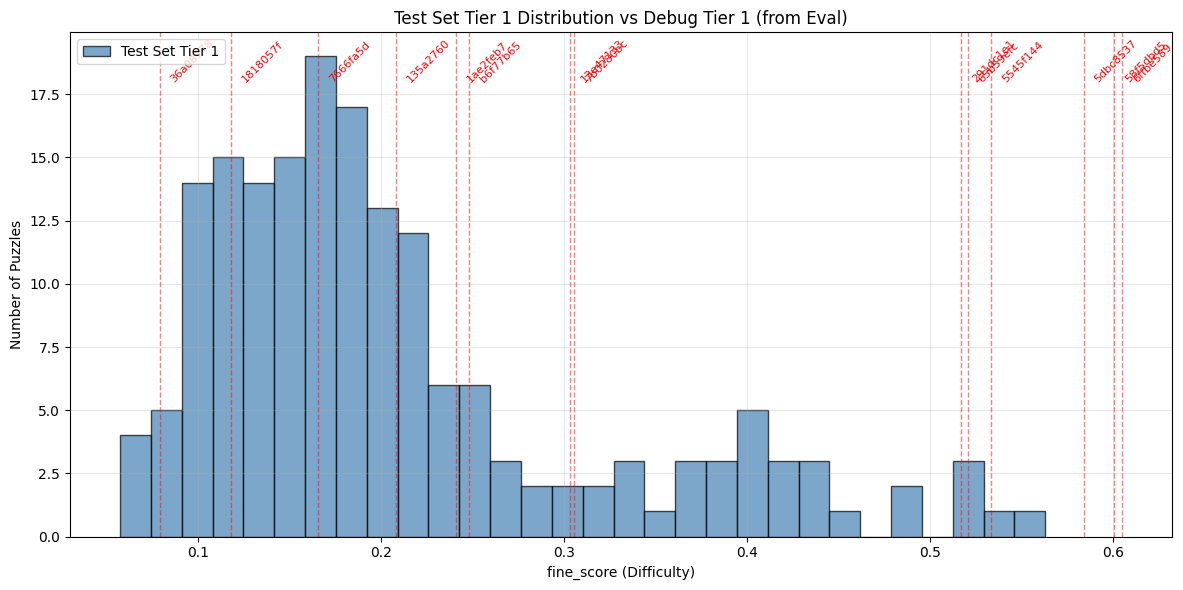


✅ SUMMARY
Debug puzzles in top 25% (hardest Tier 1 of test): 10/14
Debug puzzles in bottom 50% (easiest Tier 1 of test): 3/14

🔴 DEBUG Tier 1 is HARDER than average Test Tier 1 by 0.1509 points


In [34]:
# ================================================================
# COMPARE DEBUG TIER 1 vs TEST SET TIER 1 DISTRIBUTION (FIXED)
# ================================================================

import json
import numpy as np
import matplotlib.pyplot as plt

# ── 1. Load Test Set and Evaluation Set ──
test_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_test_challenges.json"
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"

with open(test_path, "r") as f:
    test_data = json.load(f)
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── 2. get_puzzle_priority function (exact copy) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 3. Your DEBUG_PUZZLES Tier 1 IDs ──
DEBUG_TIER1 = [
    "36a08778", "135a2760", "7b0280bc", "65b59efc",
    "7666fa5d", "1818057f", "1ae2feb7", "b6f77b65",
    "13e47133", "5dbc8537", "6ffbe589", "58f5dbd5",
    "5545f144", "291dc1e1"
]

# ── 4. Collect all Tier 1 puzzles from Test Set ──
test_tier1_scores = []
for key in test_data:
    tier, fine, _, _, _, _, _ = get_puzzle_priority(key, test_data)
    if tier == 1:
        test_tier1_scores.append(fine)

# ── 5. Collect fine_scores for debug puzzles from Evaluation Set ──
debug_tier1_scores = []
debug_tier1_labels = []

for pid in DEBUG_TIER1:
    if pid in eval_data:
        tier, fine, _, _, _, _, _ = get_puzzle_priority(pid, eval_data)
        if tier == 1:
            debug_tier1_scores.append(fine)
            debug_tier1_labels.append(pid)
        else:
            print(f"⚠️ {pid} is NOT Tier 1 in Evaluation set (tier={tier}) — skipping")
    else:
        print(f"⚠️ {pid} not found in Evaluation set — check your DEBUG list")

# ── 6. Convert to numpy arrays ──
test_scores = np.array(test_tier1_scores)
debug_scores = np.array(debug_tier1_scores)

# ── 7. Print statistics ──
print("=" * 70)
print("TIER 1 DISTRIBUTION COMPARISON: DEBUG (EVAL) vs TEST SET")
print("=" * 70)

print(f"\n📊 TEST SET Tier 1 (Total: {len(test_tier1_scores)} puzzles):")
print(f"  Min fine_score:  {test_scores.min():.4f}")
print(f"  Max fine_score:  {test_scores.max():.4f}")
print(f"  Mean fine_score: {test_scores.mean():.4f}")
print(f"  Median fine_score: {np.median(test_scores):.4f}")
print(f"  Std dev:         {test_scores.std():.4f}")

if len(debug_scores) > 0:
    print(f"\n🔍 DEBUG Tier 1 (Total: {len(debug_tier1_scores)} puzzles, from Evaluation set):")
    print(f"  Min fine_score:  {debug_scores.min():.4f}")
    print(f"  Max fine_score:  {debug_scores.max():.4f}")
    print(f"  Mean fine_score: {debug_scores.mean():.4f}")
    print(f"  Median fine_score: {np.median(debug_scores):.4f}")
    print(f"  Std dev:         {debug_scores.std():.4f}")
else:
    print("\n🔍 DEBUG Tier 1: No puzzles found (check your DEBUG_TIER1 list).")

# ── 8. Percentile positions of debug puzzles in TEST distribution ──
if len(debug_scores) > 0:
    print("\n📌 DEBUG PUZZLES — POSITION IN TEST TIER 1 DISTRIBUTION:")
    print(f"{'Puzzle ID':<15} {'fine_score':<12} {'Percentile':<12} {'Difficulty Level'}")
    print("-" * 70)

    for pid, score in zip(debug_tier1_labels, debug_tier1_scores):
        percentile = np.sum(test_scores < score) / len(test_scores) * 100
        if percentile < 25:
            level = "Easier than 75% of Test Tier 1"
        elif percentile < 50:
            level = "Easier than 50% of Test Tier 1"
        elif percentile < 75:
            level = "Harder than 50% of Test Tier 1"
        else:
            level = "Harder than 75% of Test Tier 1 (Top 25%)"
        print(f"{pid:<15} {score:<12.4f} {percentile:<12.1f}% {level}")

    # ── 9. Visualization ──
    plt.figure(figsize=(12, 6))
    plt.hist(test_tier1_scores, bins=30, alpha=0.7, color='steelblue', edgecolor='black', label='Test Set Tier 1')

    for pid, score in zip(debug_tier1_labels, debug_tier1_scores):
        plt.axvline(x=score, color='red', linestyle='--', alpha=0.5, linewidth=1)
        plt.text(score + 0.005, plt.ylim()[1] * 0.9, pid, rotation=45, fontsize=8, color='red')

    plt.xlabel('fine_score (Difficulty)')
    plt.ylabel('Number of Puzzles')
    plt.title('Test Set Tier 1 Distribution vs Debug Tier 1 (from Eval)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# ── 10. Summary ──
print("\n" + "=" * 70)
print("✅ SUMMARY")
print("=" * 70)

if len(debug_scores) > 0:
    hard_count = sum(1 for s in debug_scores if s > np.percentile(test_scores, 75))
    print(f"Debug puzzles in top 25% (hardest Tier 1 of test): {hard_count}/{len(debug_scores)}")
    easy_count = sum(1 for s in debug_scores if s < np.percentile(test_scores, 50))
    print(f"Debug puzzles in bottom 50% (easiest Tier 1 of test): {easy_count}/{len(debug_scores)}")

    if debug_scores.mean() > test_scores.mean():
        print(f"\n🔴 DEBUG Tier 1 is HARDER than average Test Tier 1 by {debug_scores.mean() - test_scores.mean():.4f} points")
    else:
        print(f"\n🟢 DEBUG Tier 1 is EASIER than average Test Tier 1 by {test_scores.mean() - debug_scores.mean():.4f} points")
else:
    print("No debug Tier 1 puzzles to analyze.")

print("=" * 70)

In [35]:
# ================================================================
# EDA ANALYSIS — 6 NO OUTPUT PUZZLES
# ================================================================

import json
import numpy as np
from collections import Counter

# ── 1. Load Evaluation Set ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(eval_path, "r") as f:
    eval_data = json.load(f)

# ── 2. The 6 problematic puzzles ──
NO_OUTPUT_PUZZLES = [
    "291dc1e1",
    "4e34c42c",
    "6ffbe589",
    "5dbc8537",
    "6e4f6532",
    "13e47133"
]

# ── 3. Helper: get_puzzle_priority logic (exact copy from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 4. Helper: get grid details ──
def get_grid_details(puzzle):
    train = puzzle['train']
    details = {
        'input_shapes': [],
        'output_shapes': [],
        'input_colors': set(),
        'output_colors': set(),
        'input_sizes': [],
        'output_sizes': []
    }
    for ex in train:
        inp = np.array(ex['input'])
        out = np.array(ex['output'])
        details['input_shapes'].append(inp.shape)
        details['output_shapes'].append(out.shape)
        details['input_sizes'].append(inp.size)
        details['output_sizes'].append(out.size)
        details['input_colors'].update(np.unique(inp).tolist())
        details['output_colors'].update(np.unique(out).tolist())
    return details

# ── 5. Generate the report ──
print("=" * 110)
print("EDA REPORT: 6 NO OUTPUT PUZZLES")
print("=" * 110)

# Summary counters
all_colors_count = []
all_ratios = []
output_gt_30 = 0
high_ratio = 0
dynamic_count = 0

for pid in NO_OUTPUT_PUZZLES:
    if pid not in eval_data:
        print(f"⚠️ {pid} not found in evaluation set!")
        continue
    
    puzzle = eval_data[pid]
    tier, fine, size, ratio, colors, dynamic, n_train = get_puzzle_priority(pid, eval_data)
    details = get_grid_details(puzzle)
    n_queries = len(puzzle['test'])
    
    # Check output dimensions > 30
    max_out_rows = max([s[0] for s in details['output_shapes']])
    max_out_cols = max([s[1] for s in details['output_shapes']])
    out_gt_30 = max_out_rows > 30 or max_out_cols > 30
    
    if out_gt_30:
        output_gt_30 += 1
    if ratio > 10:
        high_ratio += 1
    if dynamic:
        dynamic_count += 1
    
    all_colors_count.append(colors)
    all_ratios.append(ratio)
    
    # Detect rare colors (6 or 9)
    all_colors = details['input_colors'].union(details['output_colors'])
    has_rare = (6 in all_colors or 9 in all_colors)
    
    print(f"\n📌 Puzzle: {pid}")
    print(f"   Tier: {tier} | Fine Score: {fine:.4f} | Train: {n_train} | Queries: {n_queries}")
    print(f"   Avg Input Size: {size:.1f} | Max Ratio: {ratio:.2f} | Colors: {colors}")
    print(f"   Dynamic: {dynamic} | Rare Color (6/9): {has_rare}")
    print(f"   Input Shapes: {details['input_shapes']}")
    print(f"   Output Shapes: {details['output_shapes']}")
    print(f"   Output > 30x30? {out_gt_30} (Max rows: {max_out_rows}, Max cols: {max_out_cols})")
    print(f"   Input Colors: {sorted(details['input_colors'])}")
    print(f"   Output Colors: {sorted(details['output_colors'])}")
    print("-" * 60)

# ── 6. Summary ──
print("\n" + "=" * 110)
print("SUMMARY & PATTERNS")
print("=" * 110)

print(f"Total puzzles analyzed: {len(NO_OUTPUT_PUZZLES)}")
print(f"Dynamic puzzles: {dynamic_count}/{len(NO_OUTPUT_PUZZLES)}")
print(f"Puzzles with Ratio > 10: {high_ratio}/{len(NO_OUTPUT_PUZZLES)}")
print(f"Puzzles with Output > 30x30: {output_gt_30}/{len(NO_OUTPUT_PUZZLES)}")
print(f"Avg Colors: {np.mean(all_colors_count):.1f}")
print(f"Avg Max Ratio: {np.mean(all_ratios):.2f}")

print("\n🔍 COMMON THREADS (Likely Reasons for NO OUTPUT):")
if output_gt_30 > 0:
    print("  - Some outputs exceed 30x30 (limit_rows=30 truncates or rejects)")
if high_ratio > 3:
    print("  - High scaling ratio (model struggles to generate large grids correctly)")
if np.mean(all_colors_count) > 8:
    print("  - High color diversity (model may hallucinate colors > 9)")
if dynamic_count == len(NO_OUTPUT_PUZZLES):
    print("  - ALL are dynamic shapes (invert_mod / jagged row risk)")

print("=" * 110)

EDA REPORT: 6 NO OUTPUT PUZZLES

📌 Puzzle: 291dc1e1
   Tier: 1 | Fine Score: 0.5169 | Train: 4 | Queries: 1
   Avg Input Size: 164.0 | Max Ratio: 2.75 | Colors: 9
   Dynamic: True | Rare Color (6/9): True
   Input Shapes: [(20, 8), (8, 11), (8, 28), (8, 23)]
   Output Shapes: [(12, 6), (8, 4), (14, 8), (14, 6)]
   Output > 30x30? False (Max rows: 14, Max cols: 8)
   Input Colors: [0, 1, 2, 3, 4, 6, 7, 8, 9]
   Output Colors: [1, 2, 3, 4, 6, 7, 8, 9]
------------------------------------------------------------

📌 Puzzle: 4e34c42c
   Tier: 2 | Fine Score: 0.7688 | Train: 2 | Queries: 2
   Avg Input Size: 587.5 | Max Ratio: 9.58 | Colors: 8
   Dynamic: True | Rare Color (6/9): True
   Input Shapes: [(23, 25), (30, 20)]
   Output Shapes: [(5, 12), (5, 22)]
   Output > 30x30? False (Max rows: 5, Max cols: 22)
   Input Colors: [1, 2, 3, 4, 5, 6, 8, 9]
   Output Colors: [1, 2, 3, 4, 5, 6, 8, 9]
------------------------------------------------------------

📌 Puzzle: 6ffbe589
   Tier: 1 | Fine 

In [36]:
import json
import numpy as np
from collections import Counter

EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"

with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

CURRENT_KEEP_HINTS = {
    "7666fa5d", "135a2760", "65b59efc", "58f5dbd5", "5dbc8537",
    "8b9c3697", "aa4ec2a5", "7b3084d4", "fc7cae8d", "4e34c42c",
    "1ae2feb7", "b6f77b65", "4c7dc4dd",
}

def cells(a):
    return int(np.prod(np.shape(a)))

def puzzle_features(key, data):
    p = data[key]
    train = p["train"]

    input_sizes = [cells(x["input"]) for x in train]
    output_sizes = [cells(x["output"]) for x in train]
    ratios = [max(i, o) / max(min(i, o), 1) for i, o in zip(input_sizes, output_sizes)]

    colors = set()
    px = []
    for ex in train:
        for name in ["input", "output"]:
            arr = np.array(ex[name])
            colors.update(np.unique(arr).tolist())
            px.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(p["test"])
    dynamic = any(np.shape(x["input"]) != np.shape(x["output"]) for x in train)
    rare = bool(6 in colors or 9 in colors)
    bg_density = px.count(0) / max(len(px), 1)

    if dynamic and max_ratio > 30:
        tier = 3
    elif dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if dynamic:
        tags.append("dynamic")
    if rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": dynamic,
        "rare": rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
        "keep_hint": key in CURRENT_KEEP_HINTS,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}
items = list(features.values())

TARGETS = {
    "total": 48,
    "tier1": 35,
    "tier2": 10,
    "tier3": 3,
    "easy_static_min": 17,
    "rare_max": 24,
    "multi_max": 14,
    "dynamic_max": 16,
    "hard_tier1_max": 5,
}

suite = []
selected = set()

def counts(rows):
    c = Counter()
    c["total"] = len(rows)
    c["tier1"] = sum(x["tier"] == 1 for x in rows)
    c["tier2"] = sum(x["tier"] == 2 for x in rows)
    c["tier3"] = sum(x["tier"] == 3 for x in rows)
    c["easy_static"] = sum("easy_static" in x["tags"] for x in rows)
    c["rare"] = sum(x["rare"] for x in rows)
    c["multi"] = sum(x["n_queries"] > 1 for x in rows)
    c["dynamic"] = sum(x["dynamic"] for x in rows)
    c["hard_tier1"] = sum("hard_tier1" in x["tags"] for x in rows)
    c["high_ratio"] = sum(x["max_ratio"] > 5 for x in rows)
    return c

def can_add(x, strict=True):
    if x["key"] in selected:
        return False

    c = counts(suite)
    if c["total"] >= TARGETS["total"]:
        return False

    if strict:
        if x["rare"] and c["rare"] >= TARGETS["rare_max"]:
            return False
        if x["n_queries"] > 1 and c["multi"] >= TARGETS["multi_max"]:
            return False
        if x["dynamic"] and c["dynamic"] >= TARGETS["dynamic_max"]:
            return False
        if "hard_tier1" in x["tags"] and c["hard_tier1"] >= TARGETS["hard_tier1_max"]:
            return False

    return True

def add_bucket(name, candidates, n, sort_key):
    added = []
    for x in sorted(candidates, key=sort_key):
        if len(added) >= n:
            break
        if can_add(x, strict=True):
            suite.append(x)
            selected.add(x["key"])
            added.append(x)
    print(f"{name}: added {len(added)}")
    return added

# 1. Easy/static backbone, prefer around Tier1 median and low rarity pressure
add_bucket(
    "easy_static",
    [x for x in items if x["tier"] == 1 and "easy_static" in x["tags"]],
    17,
    lambda x: (x["rare"], abs(x["fine"] - 0.17), -x["n_train"])
)

# 2. Normal Tier1, non-dynamic, not too rare/multi-heavy
add_bucket(
    "normal_tier1",
    [x for x in items if x["tier"] == 1 and not x["dynamic"] and 0.18 <= x["fine"] <= 0.34],
    11,
    lambda x: (x["rare"], x["n_queries"] > 1, abs(x["fine"] - 0.23))
)

# 3. Hard Tier1 capped
add_bucket(
    "hard_tier1",
    [x for x in items if x["tier"] == 1 and "hard_tier1" in x["tags"]],
    5,
    lambda x: (-int(x["keep_hint"]), -x["fine"])
)

# 4. Tier2 static/large representative
add_bucket(
    "tier2_static",
    [x for x in items if x["tier"] == 2 and not x["dynamic"]],
    6,
    lambda x: (-int(x["keep_hint"]), x["rare"], abs(x["fine"] - 0.30))
)

# 5. Tier2 dynamic/high-ratio stress, capped
add_bucket(
    "tier2_dynamic",
    [x for x in items if x["tier"] == 2 and x["dynamic"]],
    5,
    lambda x: (-int(x["keep_hint"]), -x["fine"])
)

# 6. Tier3 extreme, include 3
add_bucket(
    "tier3",
    [x for x in items if x["tier"] == 3],
    3,
    lambda x: (-int(x["keep_hint"]), -x["fine"])
)

# 7. Fill remaining with low-pressure Tier1/Tier2 representatives
while len(suite) < TARGETS["total"]:
    c = counts(suite)
    candidates = [x for x in items if x["key"] not in selected and x["tier"] in (1, 2)]

    def fill_score(x):
        tier_need = 0
        if c["tier1"] < TARGETS["tier1"] and x["tier"] == 1:
            tier_need -= 2
        if c["tier2"] < TARGETS["tier2"] and x["tier"] == 2:
            tier_need -= 2
        if c["easy_static"] < TARGETS["easy_static_min"] and "easy_static" in x["tags"]:
            tier_need -= 2
        penalty = 0
        penalty += 2 if x["rare"] and c["rare"] >= TARGETS["rare_max"] else 0
        penalty += 2 if x["n_queries"] > 1 and c["multi"] >= TARGETS["multi_max"] else 0
        penalty += 2 if x["dynamic"] and c["dynamic"] >= TARGETS["dynamic_max"] else 0
        return (penalty, tier_need, x["rare"], x["n_queries"] > 1, abs(x["fine"] - 0.22))

    candidates = sorted(candidates, key=fill_score)
    picked = None
    for x in candidates:
        if can_add(x, strict=False):
            picked = x
            break
    if picked is None:
        break
    suite.append(picked)
    selected.add(picked["key"])

DEBUG_PUZZLES = [x["key"] for x in suite]
DEBUG_TAGS = {x["key"]: x["tags"] for x in suite}

print("=" * 100)
print("REVISED_COMPOSITE_DEBUG_48")
print("=" * 100)
print("DEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features[k]
    print(
        f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, '
        f'size={x["avg_input_size"]:.0f}, ratio={x["max_ratio"]:.2f}, '
        f'colors={x["n_colors"]}, train={x["n_train"]}, q={x["n_queries"]}, '
        f'tags={",".join(x["tags"])}'
    )
print("]")

print("\nDEBUG_TAGS = {")
for k in DEBUG_PUZZLES:
    print(f'    "{k}": {DEBUG_TAGS[k]},')
print("}")

def summarize(rows):
    c = counts(rows)
    print("\n" + "=" * 100)
    print("REVISED COMPOSITE SUMMARY")
    print("=" * 100)
    for k in ["total", "tier1", "tier2", "tier3", "easy_static", "rare", "multi", "dynamic", "hard_tier1", "high_ratio"]:
        print(f"{k:<15}: {c[k]}")
    print(f"Mean fine:       {np.mean([x['fine'] for x in rows]):.4f}")
    print(f"Median fine:     {np.median([x['fine'] for x in rows]):.4f}")
    print(f"Mean size:       {np.mean([x['avg_input_size'] for x in rows]):.1f}")
    print(f"Mean max ratio:  {np.mean([x['max_ratio'] for x in rows]):.2f}")
    print(f"Mean colors:     {np.mean([x['n_colors'] for x in rows]):.2f}")
    print(f"Mean queries:    {np.mean([x['n_queries'] for x in rows]):.2f}")

summarize(suite)

print("\n" + "=" * 100)
print("LENS MEMBERS")
print("=" * 100)

lenses = {
    "SMOKE_LENS": lambda x: (
        "easy_static" in x["tags"]
        or x["n_queries"] > 1
        or x["dynamic"]
        or x["tier"] == 3
    ),
    "PROXY_LENS": lambda x: (
        x["tier"] == 1
        or (x["tier"] == 2 and not x["dynamic"])
    ),
    "STRESS_LENS": lambda x: (
        x["dynamic"]
        or x["rare"]
        or x["n_queries"] > 1
        or x["max_ratio"] > 5
        or x["tier"] == 3
        or x["fine"] > 0.45
    ),
    "EASY_STATIC_LENS": lambda x: "easy_static" in x["tags"],
    "MULTI_QUERY_LENS": lambda x: x["n_queries"] > 1,
    "DYNAMIC_LENS": lambda x: x["dynamic"],
    "RARE_COLOR_LENS": lambda x: x["rare"],
    "HIGH_RATIO_LENS": lambda x: x["max_ratio"] > 5,
}

for name, fn in lenses.items():
    members = [x["key"] for x in suite if fn(x)]
    print(f"\n{name} ({len(members)}):")
    print(members)

print("\n" + "=" * 100)
print("CSV_STYLE_TABLE")
print("=" * 100)
print("key,tier,fine,size,max_ratio,colors,dynamic,rare,n_train,n_queries,tags")
for x in suite:
    print(
        f'{x["key"]},{x["tier"]},{x["fine"]:.4f},{x["avg_input_size"]:.1f},'
        f'{x["max_ratio"]:.2f},{x["n_colors"]},{x["dynamic"]},{x["rare"]},'
        f'{x["n_train"]},{x["n_queries"]},{"|".join(x["tags"])}'
    )

easy_static: added 16
normal_tier1: added 11
hard_tier1: added 5
tier2_static: added 6
tier2_dynamic: added 4
tier3: added 1
REVISED_COMPOSITE_DEBUG_48
DEBUG_PUZZLES = [
    "4a21e3da",  # tier=1, fine=0.1680, size=324, ratio=1.00, colors=3, train=3, q=2, tags=tier1,easy_static,easy,multi_query,dense_non_bg
    "7666fa5d",  # tier=1, fine=0.1653, size=256, ratio=1.00, colors=4, train=2, q=1, tags=tier1,easy_static,easy,dense_non_bg,low_train
    "cb2d8a2c",  # tier=1, fine=0.1766, size=290, ratio=1.00, colors=4, train=4, q=2, tags=tier1,easy_static,easy,multi_query,dense_non_bg
    "71e489b6",  # tier=1, fine=0.1528, size=278, ratio=1.00, colors=3, train=3, q=2, tags=tier1,easy_static,easy,multi_query
    "da515329",  # tier=1, fine=0.1382, size=295, ratio=1.00, colors=2, train=3, q=1, tags=tier1,easy_static,easy,sparse_bg
    "332f06d7",  # tier=1, fine=0.1380, size=174, ratio=1.00, colors=4, train=4, q=1, tags=tier1,easy_static,easy,dense_non_bg
    "53fb4810",  # tier=1, fine=0.2058

In [37]:
import json
import numpy as np
from collections import Counter

# ── 1. Load Test Set ──
test_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_test_challenges.json"
with open(test_path, "r") as f:
    test_data = json.load(f)

# ── 2. Exact get_puzzle_priority function (from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 3. Helper: has_rare_color ──
def has_rare_color(puzzle):
    all_colors = set()
    for ex in puzzle['train']:
        all_colors.update(np.unique(ex['input']).tolist())
        all_colors.update(np.unique(ex['output']).tolist())
    return 6 in all_colors or 9 in all_colors

# ── 4. Scan all test puzzles ──
categories = {
    "Total": 0,
    "Tier1": 0,
    "Tier2": 0,
    "Tier3": 0,
    "Easy static": 0,
    "Rare": 0,
    "Multi-query": 0,
    "Dynamic": 0,
    "Hard Tier1": 0,
    "High ratio": 0,
    "Extreme ratio": 0,
}

for key in test_data:
    puzzle = test_data[key]
    tier, fine, size, max_ratio, colors, dynamic, n_train = get_puzzle_priority(key, test_data)
    n_queries = len(puzzle['test'])
    rare = has_rare_color(puzzle)

    categories["Total"] += 1
    if tier == 1:
        categories["Tier1"] += 1
    elif tier == 2:
        categories["Tier2"] += 1
    elif tier == 3:
        categories["Tier3"] += 1

    if tier == 1 and not dynamic:
        categories["Easy static"] += 1

    if rare:
        categories["Rare"] += 1

    if n_queries > 1:
        categories["Multi-query"] += 1

    if dynamic:
        categories["Dynamic"] += 1

    if tier == 1 and fine > 0.45:
        categories["Hard Tier1"] += 1

    if max_ratio > 10:
        categories["High ratio"] += 1

    if max_ratio > 30:
        categories["Extreme ratio"] += 1

# ── 5. Print results ──
total = categories["Total"]
print("=" * 60)
print("TEST SET CATEGORY DISTRIBUTION")
print("=" * 60)
print(f"{'Category':<15} {'Count':>6} {'%':>8}")
print("-" * 60)
for cat, count in categories.items():
    if cat == "Total":
        continue
    pct = count / total * 100
    print(f"{cat:<15} {count:>6} {pct:>7.1f}%")
print("=" * 60)
print(f"Total puzzles in test set: {total}")
print("=" * 60)

TEST SET CATEGORY DISTRIBUTION
Category         Count        %
------------------------------------------------------------
Tier1              178    74.2%
Tier2               52    21.7%
Tier3               10     4.2%
Easy static        149    62.1%
Rare               131    54.6%
Multi-query         17     7.1%
Dynamic             71    29.6%
Hard Tier1           7     2.9%
High ratio          24    10.0%
Extreme ratio       10     4.2%
Total puzzles in test set: 240


In [38]:
import json
import numpy as np
from collections import Counter

# ── 1. Load both sets ──
eval_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
test_path = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_test_challenges.json"

with open(eval_path, "r") as f:
    eval_data = json.load(f)
with open(test_path, "r") as f:
    test_data = json.load(f)

# ── 2. Exact get_puzzle_priority function (from starter.py) ──
def get_puzzle_priority(key, data):
    train = data[key]['train']
    n_train = len(train)

    avg_input_size = np.mean([
        np.prod(np.shape(x['input'])) for x in train
    ])
    size_ratios = [
        max(np.prod(np.shape(x['output'])),
            np.prod(np.shape(x['input']))) /
        max(min(np.prod(np.shape(x['output'])),
                np.prod(np.shape(x['input']))), 1)
        for x in train
    ]
    max_ratio = max(size_ratios)
    avg_ratio = np.mean(size_ratios)

    n_colors = len(set(
        int(c)
        for x in train
        for arr in [x['input'], x['output']]
        for c in np.unique(arr).tolist()
    ))
    is_dynamic = any(
        np.shape(x['input']) != np.shape(x['output'])
        for x in train
    )

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )

    if n_train >= 6 and tier < 3:
        fine *= 0.7

    return tier, fine, avg_input_size, max_ratio, n_colors, is_dynamic, n_train

# ── 3. Helper: has_rare_color ──
def has_rare_color(puzzle):
    all_colors = set()
    for ex in puzzle['train']:
        all_colors.update(np.unique(ex['input']).tolist())
        all_colors.update(np.unique(ex['output']).tolist())
    return 6 in all_colors or 9 in all_colors

# ── 4. Function to compute categories for a dataset ──
def compute_categories(data):
    categories = {
        "Total": 0,
        "Tier1": 0,
        "Tier2": 0,
        "Tier3": 0,
        "Easy static": 0,
        "Rare": 0,
        "Multi-query": 0,
        "Dynamic": 0,
        "Hard Tier1": 0,
        "High ratio": 0,
        "Extreme ratio": 0,
    }
    for key in data:
        puzzle = data[key]
        tier, fine, size, max_ratio, colors, dynamic, n_train = get_puzzle_priority(key, data)
        n_queries = len(puzzle['test'])
        rare = has_rare_color(puzzle)

        categories["Total"] += 1
        if tier == 1:
            categories["Tier1"] += 1
        elif tier == 2:
            categories["Tier2"] += 1
        elif tier == 3:
            categories["Tier3"] += 1

        if tier == 1 and not dynamic:
            categories["Easy static"] += 1

        if rare:
            categories["Rare"] += 1

        if n_queries > 1:
            categories["Multi-query"] += 1

        if dynamic:
            categories["Dynamic"] += 1

        if tier == 1 and fine > 0.45:
            categories["Hard Tier1"] += 1

        if max_ratio > 10:
            categories["High ratio"] += 1

        if max_ratio > 30:
            categories["Extreme ratio"] += 1

    return categories

# ── 5. Compute for both sets ──
test_cats = compute_categories(test_data)
eval_cats = compute_categories(eval_data)

# ── 6. Print comparison table ──
print("=" * 80)
print("CATEGORY COMPARISON: TEST vs EVALUATION")
print("=" * 80)

# Define categories to display (excluding "Total")
cat_names = [
    "Tier1", "Tier2", "Tier3",
    "Easy static", "Rare", "Multi-query", "Dynamic",
    "Hard Tier1", "High ratio", "Extreme ratio"
]

print(f"{'Category':<15} {'Test Count':>12} {'Test %':>8} {'Eval Count':>12} {'Eval %':>8} {'Diff (pp)':>10}")
print("-" * 80)

test_total = test_cats["Total"]
eval_total = eval_cats["Total"]

for cat in cat_names:
    test_cnt = test_cats[cat]
    test_pct = test_cnt / test_total * 100
    eval_cnt = eval_cats[cat]
    eval_pct = eval_cnt / eval_total * 100
    diff = test_pct - eval_pct
    print(f"{cat:<15} {test_cnt:>12} {test_pct:>7.1f}% {eval_cnt:>12} {eval_pct:>7.1f}% {diff:>9.1f}pp")

print("-" * 80)
print(f"{'Total':<15} {test_total:>12} {100.0:>7.1f}% {eval_total:>12} {100.0:>7.1f}% {'':>10}")
print("=" * 80)

# Also print the raw differences for quick reference
print("\n🔍 Key differences:")
for cat in cat_names:
    test_pct = test_cats[cat] / test_total * 100
    eval_pct = eval_cats[cat] / eval_total * 100
    diff = test_pct - eval_pct
    if abs(diff) > 5:
        print(f"  {cat}: Test {test_pct:.1f}% vs Eval {eval_pct:.1f}% (diff {diff:+.1f}pp)")

CATEGORY COMPARISON: TEST vs EVALUATION
Category          Test Count   Test %   Eval Count   Eval %  Diff (pp)
--------------------------------------------------------------------------------
Tier1                    178    74.2%           65    54.2%      20.0pp
Tier2                     52    21.7%           51    42.5%     -20.8pp
Tier3                     10     4.2%            4     3.3%       0.8pp
Easy static              149    62.1%           52    43.3%      18.8pp
Rare                     131    54.6%           96    80.0%     -25.4pp
Multi-query               17     7.1%           49    40.8%     -33.8pp
Dynamic                   71    29.6%           39    32.5%      -2.9pp
Hard Tier1                 7     2.9%           10     8.3%      -5.4pp
High ratio                24    10.0%           10     8.3%       1.7pp
Extreme ratio             10     4.2%            4     3.3%       0.8pp
--------------------------------------------------------------------------------
Total  

In [39]:
import json
import numpy as np
from collections import Counter

# Load evaluation set
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

TARGET_N = 48

TARGET_COUNTS = {
    "tier1": 36,
    "tier2": 10,
    "tier3": 2,
    "easy_static": 30,
    "rare": 26,
    "multi_query": 3,
    "dynamic": 14,
    "hard_tier1": 2,
    "high_ratio": 5,
    "extreme_ratio": 2,
}

PREFERRED_TIER3 = ["89565ca0", "4c7dc4dd"]  # must include

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}
items = list(features.values())

def count_suite(rows):
    c = Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })
    return c

def category_keys(x):
    out = []
    out.append(f"tier{x['tier']}")
    if "easy_static" in x["tags"]:
        out.append("easy_static")
    if x["rare"]:
        out.append("rare")
    if x["n_queries"] > 1:
        out.append("multi_query")
    if x["dynamic"]:
        out.append("dynamic")
    if "hard_tier1" in x["tags"]:
        out.append("hard_tier1")
    if x["max_ratio"] > 5:
        out.append("high_ratio")
    if x["max_ratio"] > 30:
        out.append("extreme_ratio")
    return out

# Greedy selection with deficit‑based scoring
def selection_score(x, current_counts, target_counts, alpha=3.0):
    """
    Returns a score; higher is better.
    We reward belonging to deficit categories, penalize overfilled ones.
    """
    score = 0.0
    for cat in category_keys(x):
        if cat not in target_counts:
            continue
        cur = current_counts[cat]
        tgt = target_counts[cat]
        if cur < tgt:
            # deficit: encourage
            score += (tgt - cur) * alpha
        else:
            # surplus: penalize
            score -= (cur - tgt) * 2.0
    # small preference for puzzles with more tags to cover multiple deficits
    score += len(category_keys(x)) * 0.5
    # prefer lower fine for easy_static to stay within easy range
    if "easy_static" in x["tags"]:
        score -= abs(x["fine"] - 0.17) * 2.0
    return score

# Start with preferred Tier3
suite = []
selected = set()
def add_one(x):
    suite.append(x)
    selected.add(x["key"])

for k in PREFERRED_TIER3:
    if k in features:
        add_one(features[k])

# Iteratively pick best puzzle until we reach TARGET_N
while len(suite) < TARGET_N:
    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break
    current_counts = count_suite(suite)
    # Score each candidate
    scored = [(selection_score(x, current_counts, TARGET_COUNTS), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

# If we overshot, remove the least useful (lowest score) while respecting protected
while len(suite) > TARGET_N:
    protected = set(PREFERRED_TIER3)
    def removal_score(x):
        if x["key"] in protected:
            return -9999
        # compute a score: how much it contributes to overfilled categories
        current_counts = count_suite([s for s in suite if s["key"] != x["key"]])
        over_penalty = 0
        for cat in category_keys(x):
            if cat in TARGET_COUNTS:
                cur = current_counts[cat]
                tgt = TARGET_COUNTS[cat]
                if cur > tgt:
                    over_penalty += (cur - tgt) * 2.0
        return over_penalty
    drop = max(suite, key=removal_score)
    suite.remove(drop)
    selected.remove(drop["key"])

DEBUG_PUZZLES = [x["key"] for x in suite]
DEBUG_TAGS = {x["key"]: x["tags"] for x in suite}

# Print summary
print("=" * 100)
print("NEW SELECTION SUMMARY VS TARGET")
print("=" * 100)
c = count_suite(suite)
for cat in [
    "total", "tier1", "tier2", "tier3", "easy_static", "rare",
    "multi_query", "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"
]:
    target = TARGET_N if cat == "total" else TARGET_COUNTS.get(cat, None)
    actual = c[cat]
    if target is None:
        print(f"{cat:<15}: {actual}")
    else:
        print(f"{cat:<15}: actual={actual:<3} target={target:<3} diff={actual-target:+}")

print(f"\nMean fine:       {np.mean([x['fine'] for x in suite]):.4f}")
print(f"Median fine:     {np.median([x['fine'] for x in suite]):.4f}")

print("\nDEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features[k]
    print(f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={",".join(x["tags"])}')
print("]")

NEW SELECTION SUMMARY VS TARGET
total          : actual=48  target=48  diff=+0
tier1          : actual=36  target=36  diff=+0
tier2          : actual=10  target=10  diff=+0
tier3          : actual=2   target=2   diff=+0
easy_static    : actual=16  target=30  diff=-14
rare           : actual=31  target=26  diff=+5
multi_query    : actual=8   target=3   diff=+5
dynamic        : actual=15  target=14  diff=+1
hard_tier1     : actual=7   target=2   diff=+5
high_ratio     : actual=7   target=5   diff=+2
extreme_ratio  : actual=2   target=2   diff=+0

Mean fine:       0.3766
Median fine:     0.2558

DEBUG_PUZZLES = [
    "89565ca0",  # tier=3, fine=1.4844, tags=tier3,dynamic,high_ratio,extreme_ratio,many_colors,large
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,large,dense_non_bg,low_train
    "dd6b8c4b",  # tier=1, fine=0.1403, tags=tier1,easy_static,easy,rare,multi_query,dense_non_bg
    "36a08778",  # tier=1, fine=0.0788, tags=tier1,e

In [40]:
import json
import numpy as np
from collections import Counter

EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}

# Filter only easy_static puzzles
easy_static_items = [x for x in features.values() if "easy_static" in x["tags"]]

total_easy_static = len(easy_static_items)

multi_query_easy = sum(1 for x in easy_static_items if x["n_queries"] > 1)
rare_easy = sum(1 for x in easy_static_items if x["rare"])
hard_tier1_easy = sum(1 for x in easy_static_items if "hard_tier1" in x["tags"])

both_rare_multi = sum(1 for x in easy_static_items if x["rare"] and x["n_queries"] > 1)
both_rare_hard = sum(1 for x in easy_static_items if x["rare"] and "hard_tier1" in x["tags"])
both_multi_hard = sum(1 for x in easy_static_items if x["n_queries"] > 1 and "hard_tier1" in x["tags"])
all_three = sum(1 for x in easy_static_items if x["rare"] and x["n_queries"] > 1 and "hard_tier1" in x["tags"])

pure_easy_static = sum(1 for x in easy_static_items if not x["rare"] and x["n_queries"] <= 1 and "hard_tier1" not in x["tags"])

print("=" * 80)
print("ANALYSIS OF EASY_STATIC PUZZLES IN EVALUATION SET")
print("=" * 80)
print(f"Total easy_static puzzles available: {total_easy_static}")
print()
print(f"easy_static + multi_query       : {multi_query_easy}")
print(f"easy_static + rare              : {rare_easy}")
print(f"easy_static + hard_tier1        : {hard_tier1_easy}")
print()
print(f"easy_static + rare + multi_query: {both_rare_multi}")
print(f"easy_static + rare + hard_tier1 : {both_rare_hard}")
print(f"easy_static + multi_query + hard_tier1: {both_multi_hard}")
print(f"all three (rare & multi & hard) : {all_three}")
print(f"pure easy_static (none of above): {pure_easy_static}")

print("\nExamples:")
print("easy_static + multi_query:", [x["key"] for x in easy_static_items if x["n_queries"] > 1][:5])
print("easy_static + rare:", [x["key"] for x in easy_static_items if x["rare"]][:5])
print("easy_static + hard_tier1:", [x["key"] for x in easy_static_items if "hard_tier1" in x["tags"]][:5])
print("pure easy_static:", [x["key"] for x in easy_static_items if not x["rare"] and x["n_queries"] <= 1 and "hard_tier1" not in x["tags"]][:5])

# Breakdown of other tags among easy_static
counter_tags = Counter()
for x in easy_static_items:
    for tag in x["tags"]:
        if tag not in ["tier1", "easy_static", "easy"]:
            counter_tags[tag] += 1
print("\nOther tags among easy_static:")
for tag, cnt in counter_tags.most_common():
    print(f"  {tag}: {cnt}")

ANALYSIS OF EASY_STATIC PUZZLES IN EVALUATION SET
Total easy_static puzzles available: 16

easy_static + multi_query       : 5
easy_static + rare              : 8
easy_static + hard_tier1        : 0

easy_static + rare + multi_query: 2
easy_static + rare + hard_tier1 : 0
easy_static + multi_query + hard_tier1: 0
all three (rare & multi & hard) : 0
pure easy_static (none of above): 5

Examples:
easy_static + multi_query: ['36a08778', '4a21e3da', '71e489b6', 'cb2d8a2c', 'dd6b8c4b']
easy_static + rare: ['271d71e2', '2b83f449', '36a08778', '409aa875', '6e453dd6']
easy_static + hard_tier1: []
pure easy_static: ['1818057f', '332f06d7', '53fb4810', '7666fa5d', 'da515329']

Other tags among easy_static:
  dense_non_bg: 13
  rare: 8
  multi_query: 5
  low_train: 3
  sparse_bg: 1


In [41]:
import json
import numpy as np
from collections import Counter

EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}

# Filter Tier 2 puzzles
tier2_items = [x for x in features.values() if x["tier"] == 2]

print("=" * 100)
print(f"TOTAL TIER 2 PUZZLES IN EVALUATION SET: {len(tier2_items)}")
print("=" * 100)

# Sort by fine score ascending (easiest first)
tier2_sorted = sorted(tier2_items, key=lambda x: x["fine"])

print(f"\n🔍 TOP 10 EASIEST TIER 2 PUZZLES:\n")
print(f"{'#':<4} {'Key':<15} {'Fine Score':<12} {'Size':<8} {'Max Ratio':<10} {'Colors':<8} {'Dynamic':<8} {'Train':<6} {'Queries':<8} {'Tags'}")
print("-" * 120)

for i, x in enumerate(tier2_sorted[:10]):
    print(f"{i+1:<4} {x['key']:<15} {x['fine']:<12.4f} {x['avg_input_size']:<8.0f} {x['max_ratio']:<10.2f} {x['n_colors']:<8} {str(x['dynamic']):<8} {x['n_train']:<6} {x['n_queries']:<8} {','.join(x['tags'])}")

# Also show the full list distribution
print("\n" + "=" * 100)
print("TIER 2 DISTRIBUTION:")
print("=" * 100)
dynamic_t2 = sum(1 for x in tier2_items if x["dynamic"])
static_t2 = len(tier2_items) - dynamic_t2
rare_t2 = sum(1 for x in tier2_items if x["rare"])
multi_t2 = sum(1 for x in tier2_items if x["n_queries"] > 1)
high_ratio_t2 = sum(1 for x in tier2_items if x["max_ratio"] > 5)
large_t2 = sum(1 for x in tier2_items if x["avg_input_size"] >= 500)

print(f"Dynamic Tier 2: {dynamic_t2}")
print(f"Static Tier 2: {static_t2}")
print(f"Rare Tier 2: {rare_t2}")
print(f"Multi-query Tier 2: {multi_t2}")
print(f"High Ratio (>5) Tier 2: {high_ratio_t2}")
print(f"Large (>500 cells) Tier 2: {large_t2}")

TOTAL TIER 2 PUZZLES IN EVALUATION SET: 51

🔍 TOP 10 EASIEST TIER 2 PUZZLES:

#    Key             Fine Score   Size     Max Ratio  Colors   Dynamic  Train  Queries  Tags
------------------------------------------------------------------------------------------------------------------------
1    5961cc34        0.2485       446      1.00       5        False    4      1        tier2,dense_non_bg
2    8b9c3697        0.2593       418      1.00       6        False    3      1        tier2,dense_non_bg
3    aa4ec2a5        0.2688       506      1.00       5        False    3      1        tier2,rare,large,dense_non_bg
4    7b80bb43        0.2720       576      1.00       4        False    2      1        tier2,rare,large,low_train
5    c4d067a0        0.2763       529      1.00       5        False    3      1        tier2,large,dense_non_bg
6    8e5c0c38        0.2813       484      1.00       6        False    2      2        tier2,rare,multi_query,low_train
7    80a900e0        0.2867

In [42]:
import json
import numpy as np
from collections import Counter

# Load evaluation set
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

TARGET_N = 48

# Hard constraints: these MUST be exactly these numbers
HARD_CATS = {
    "rare": 26,
    "multi_query": 3,
    "hard_tier1": 2,
    "high_ratio": 5,
}

# Other targets (will try to match as closely as possible)
SOFT_TARGETS = {
    "tier1": 36,
    "tier2": 10,
    "tier3": 2,
    "easy_static": 16,  # max available in eval set
    "dynamic": 14,
    "extreme_ratio": 2,
}

PREFERRED_TIER3 = ["89565ca0", "4c7dc4dd"]

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}
items = list(features.values())

def count_suite(rows):
    c = Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })
    return c

def category_keys(x):
    out = []
    out.append(f"tier{x['tier']}")
    if "easy_static" in x["tags"]:
        out.append("easy_static")
    if x["rare"]:
        out.append("rare")
    if x["n_queries"] > 1:
        out.append("multi_query")
    if x["dynamic"]:
        out.append("dynamic")
    if "hard_tier1" in x["tags"]:
        out.append("hard_tier1")
    if x["max_ratio"] > 5:
        out.append("high_ratio")
    if x["max_ratio"] > 30:
        out.append("extreme_ratio")
    return out

def is_hard_ok(x, current_counts):
    """Check if adding this puzzle would violate any hard constraint"""
    for cat in HARD_CATS:
        if cat in category_keys(x):
            cur = current_counts[cat]
            tgt = HARD_CATS[cat]
            if cur >= tgt:
                return False
    return True

# Selection score (for soft targets only)
def selection_score(x, current_counts):
    score = 0.0
    for cat in category_keys(x):
        if cat in SOFT_TARGETS:
            cur = current_counts[cat]
            tgt = SOFT_TARGETS[cat]
            if cur < tgt:
                score += (tgt - cur) * 2.0
            else:
                score -= (cur - tgt) * 1.5
    # Prefer puzzles with more tags to cover multiple soft deficits
    score += len(category_keys(x)) * 0.3
    # Encourage easy_static (since we know we need all of them)
    if "easy_static" in x["tags"]:
        score += 10.0
    # Prefer lower fine for easy puzzles
    if x["tier"] == 1:
        score -= abs(x["fine"] - 0.2) * 1.0
    return score

# Start with preferred Tier3
suite = []
selected = set()
def add_one(x):
    suite.append(x)
    selected.add(x["key"])

for k in PREFERRED_TIER3:
    if k in features:
        add_one(features[k])

# First, fill hard constraints greedily
# We'll cycle through hard cats to ensure they get filled
for _ in range(100):  # safety limit
    current_counts = count_suite(suite)
    # Check if all hard constraints are met
    all_hard_met = all(current_counts[cat] >= HARD_CATS[cat] for cat in HARD_CATS)
    if all_hard_met:
        break
    
    # Find candidates that help fill missing hard cats
    candidates = [x for x in items if x["key"] not in selected]
    scored = []
    for x in candidates:
        if not is_hard_ok(x, current_counts):
            continue
        # Score: prioritize hard deficits
        score = 0.0
        for cat in HARD_CATS:
            if cat in category_keys(x):
                cur = current_counts[cat]
                tgt = HARD_CATS[cat]
                if cur < tgt:
                    score += (tgt - cur) * 10.0
        # Also consider soft targets
        score += selection_score(x, current_counts) * 0.3
        scored.append((score, x))
    
    if not scored:
        break
    scored.sort(key=lambda t: t[0], reverse=True)
    add_one(scored[0][1])

# Now fill remaining slots (up to TARGET_N) using soft targets
while len(suite) < TARGET_N:
    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break
    current_counts = count_suite(suite)
    # Filter: must not violate hard constraints
    candidates = [x for x in candidates if is_hard_ok(x, current_counts)]
    if not candidates:
        break
    scored = [(selection_score(x, current_counts), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    add_one(scored[0][1])

# If we overshot, remove least useful while preserving hard constraints
def removal_score(x, current_counts):
    # If removing this would break a hard constraint, return very low (don't remove)
    temp_counts = count_suite([s for s in suite if s["key"] != x["key"]])
    for cat in HARD_CATS:
        if temp_counts[cat] < HARD_CATS[cat]:
            return -9999
    # Otherwise, score by how much it contributes to overfilled soft targets
    s = 0
    for cat in SOFT_TARGETS:
        cur = current_counts[cat]
        tgt = SOFT_TARGETS[cat]
        if cat in category_keys(x):
            if cur > tgt:
                s += (cur - tgt) * 2.0
    return s

while len(suite) > TARGET_N:
    protected = set(PREFERRED_TIER3)
    current_counts = count_suite(suite)
    best_remove = None
    best_score = -9999
    for x in suite:
        if x["key"] in protected:
            continue
        sc = removal_score(x, current_counts)
        if sc > best_score:
            best_score = sc
            best_remove = x
    if best_remove is None:
        break
    suite.remove(best_remove)
    selected.remove(best_remove["key"])

DEBUG_PUZZLES = [x["key"] for x in suite]
DEBUG_TAGS = {x["key"]: x["tags"] for x in suite}

# Print summary
print("=" * 100)
print("FINAL SELECTION SUMMARY")
print("=" * 100)
c = count_suite(suite)
all_cats = ["total"] + list(HARD_CATS.keys()) + list(SOFT_TARGETS.keys())
# Deduplicate
all_cats = list(dict.fromkeys(all_cats))

print(f"{'Category':<15} {'Actual':>8} {'Target':>8} {'Diff':>8}")
print("-" * 45)
for cat in all_cats:
    if cat == "total":
        target = TARGET_N
    elif cat in HARD_CATS:
        target = HARD_CATS[cat]
    else:
        target = SOFT_TARGETS.get(cat, None)
    actual = c[cat]
    if target is not None:
        print(f"{cat:<15} {actual:>8} {target:>8} {actual-target:>+8}")
    else:
        print(f"{cat:<15} {actual:>8} {'-':>8} {'-':>8}")

print(f"\nMean fine:       {np.mean([x['fine'] for x in suite]):.4f}")
print(f"Median fine:     {np.median([x['fine'] for x in suite]):.4f}")
print(f"Total puzzles:   {len(suite)}")

print("\nDEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features[k]
    print(f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={",".join(x["tags"])}')
print("]")

FINAL SELECTION SUMMARY
Category          Actual   Target     Diff
---------------------------------------------
total                 39       48       -9
rare                  26       26       +0
multi_query            3        3       +0
hard_tier1             2        2       +0
high_ratio             5        5       +0
tier1                 29       36       -7
tier2                  8       10       -2
tier3                  2        2       +0
easy_static           11       16       -5
dynamic                7       14       -7
extreme_ratio          2        2       +0

Mean fine:       0.3436
Median fine:     0.2485
Total puzzles:   39

DEBUG_PUZZLES = [
    "89565ca0",  # tier=3, fine=1.4844, tags=tier3,dynamic,high_ratio,extreme_ratio,many_colors,large
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,large,dense_non_bg,low_train
    "21897d95",  # tier=1, fine=0.4932, tags=tier1,hard_tier1,dynamic,rare,multi_query,many_co

In [43]:
import json
import numpy as np
from collections import Counter

# Load evaluation set
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

TARGET_N = 48

# ---- PRIORITY CATEGORIES (must hit these targets) ----
PRIORITY_TARGETS = {
    "rare": 26,
    "multi_query": 3,
    "hard_tier1": 2,
    "high_ratio": 5,
    "extreme_ratio": 2,
}

# ---- SECONDARY TARGETS (try to get close, but not mandatory) ----
SECONDARY_TARGETS = {
    "tier1": 36,
    "tier2": 10,
    "tier3": 2,
    "easy_static": 16,  # max available in eval set
    "dynamic": 14,
}

PREFERRED_TIER3 = ["89565ca0", "4c7dc4dd"]

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}
items = list(features.values())

def count_suite(rows):
    c = Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })
    return c

def category_priority_keys(x):
    """Return list of priority categories this puzzle belongs to."""
    out = []
    if x["rare"]:
        out.append("rare")
    if x["n_queries"] > 1:
        out.append("multi_query")
    if "hard_tier1" in x["tags"]:
        out.append("hard_tier1")
    if x["max_ratio"] > 5:
        out.append("high_ratio")
    if x["max_ratio"] > 30:
        out.append("extreme_ratio")
    return out

def category_secondary_keys(x):
    out = []
    out.append(f"tier{x['tier']}")
    if "easy_static" in x["tags"]:
        out.append("easy_static")
    if x["dynamic"]:
        out.append("dynamic")
    return out

# ---- Phase 1: Force priority categories ----
suite = []
selected = set()
def add_one(x):
    suite.append(x)
    selected.add(x["key"])

# Start with preferred Tier3
for k in PREFERRED_TIER3:
    if k in features:
        add_one(features[k])

# Now, iteratively add puzzles that help meet priority targets
while True:
    current_counts = count_suite(suite)
    # Check if all priority targets met
    all_met = True
    for cat, tgt in PRIORITY_TARGETS.items():
        if current_counts[cat] < tgt:
            all_met = False
            break
    if all_met:
        break

    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break

    scored = []
    for x in candidates:
        score = 0.0
        # For each priority category, add deficit weight
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur < tgt:
                    score += (tgt - cur) * 5.0  # high weight
                else:
                    score -= (cur - tgt) * 3.0  # penalty
        # Prefer puzzles that cover multiple categories
        score += len(category_priority_keys(x)) * 2.0
        scored.append((score, x))

    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

# ---- Phase 2: Fill remaining slots up to TARGET_N ----
# Now we have a set that meets priority targets, but may be less than 48.
# We'll add more puzzles, prioritizing secondary targets but without strict constraints.
while len(suite) < TARGET_N:
    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break
    current_counts = count_suite(suite)

    def fill_score(x):
        score = 0.0
        # Reward for secondary categories that are still below targets
        for cat in category_secondary_keys(x):
            if cat in SECONDARY_TARGETS:
                cur = current_counts[cat]
                tgt = SECONDARY_TARGETS[cat]
                if cur < tgt:
                    score += (tgt - cur) * 1.0
                else:
                    score -= (cur - tgt) * 1.5
        # Also reward if puzzle is easy (low fine) and doesn't add too much complexity
        if x["tier"] == 1 and x["fine"] < 0.25:
            score += 0.5
        # Penalize if it would push priority categories over target too much
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur >= tgt:
                    score -= (cur - tgt + 1) * 1.5
        # Ensure easy_static doesn't go above 16
        if "easy_static" in x["tags"]:
            cur_es = current_counts["easy_static"]
            if cur_es >= 16:
                score -= 10.0
        return score

    scored = [(fill_score(x), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

# If we overshot, trim back to 48 by removing least useful
while len(suite) > TARGET_N:
    protected = set(PREFERRED_TIER3)
    def removal_score(x):
        if x["key"] in protected:
            return -9999
        current_counts = count_suite([s for s in suite if s["key"] != x["key"]])
        # Compute how much this puzzle contributes to overfilled categories
        over_penalty = 0
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur > tgt:
                    over_penalty += (cur - tgt) * 2.0
        for cat in category_secondary_keys(x):
            if cat in SECONDARY_TARGETS:
                cur = current_counts[cat]
                tgt = SECONDARY_TARGETS[cat]
                if cur > tgt:
                    over_penalty += (cur - tgt) * 1.0
        return over_penalty
    drop = max(suite, key=removal_score)
    suite.remove(drop)
    selected.remove(drop["key"])

DEBUG_PUZZLES = [x["key"] for x in suite]
DEBUG_TAGS = {x["key"]: x["tags"] for x in suite}

# Print summary
print("=" * 100)
print("FINAL SELECTION SUMMARY")
print("=" * 100)
c = count_suite(suite)
all_cats = list(PRIORITY_TARGETS.keys()) + list(SECONDARY_TARGETS.keys()) + ["total"]
all_cats = sorted(set(all_cats))

print(f"{'Category':<15} {'Actual':>8} {'Target':>8} {'Diff':>8}")
print("-" * 45)
for cat in all_cats:
    if cat == "total":
        target = TARGET_N
    else:
        target = PRIORITY_TARGETS.get(cat, SECONDARY_TARGETS.get(cat, None))
    actual = c.get(cat, 0)
    if target is not None:
        print(f"{cat:<15} {actual:>8} {target:>8} {actual-target:>+8}")
    else:
        print(f"{cat:<15} {actual:>8} {'N/A':>8} {'':>8}")

print(f"\nTotal puzzles: {len(suite)}")
print(f"Mean fine:     {np.mean([x['fine'] for x in suite]):.4f}")
print(f"Median fine:   {np.median([x['fine'] for x in suite]):.4f}")

print("\nDEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features[k]
    tags_str = ",".join(x["tags"])
    print(f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={tags_str}')
print("]")

FINAL SELECTION SUMMARY
Category          Actual   Target     Diff
---------------------------------------------
dynamic               12       14       -2
easy_static           14       16       -2
extreme_ratio          3        2       +1
hard_tier1             3        2       +1
high_ratio             7        5       +2
multi_query            9        3       +6
rare                  31       26       +5
tier1                 32       36       -4
tier2                 13       10       +3
tier3                  3        2       +1
total                 48       48       +0

Total puzzles: 48
Mean fine:     0.3784
Median fine:   0.2558

DEBUG_PUZZLES = [
    "89565ca0",  # tier=3, fine=1.4844, tags=tier3,dynamic,high_ratio,extreme_ratio,many_colors,large
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,large,dense_non_bg,low_train
    "20a9e565",  # tier=3, fine=1.5125, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio

In [44]:
import json
import numpy as np
from collections import Counter

# Load evaluation set
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

TARGET_N = 48

# ---- NEW TARGETS AS PER USER ----
PRIORITY_TARGETS = {
    "rare": 26,
    "multi_query": 4,
    "hard_tier1": 3,
    "high_ratio": 5,
    "tier3": 4,
}

# Secondary targets (keep as close as possible)
SECONDARY_TARGETS = {
    "tier1": 36,
    "tier2": 10,
    "easy_static": 16,  # max available
    "dynamic": 14,
    "extreme_ratio": 2, # already included in high_ratio? but we can keep
}

# Ensure we have at least 4 tier3 puzzles; if not, we will fill with tier2/1.

def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

features = {k: puzzle_features(k, eval_data) for k in eval_data}
items = list(features.values())

def count_suite(rows):
    c = Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })
    return c

def category_priority_keys(x):
    out = []
    if x["rare"]:
        out.append("rare")
    if x["n_queries"] > 1:
        out.append("multi_query")
    if "hard_tier1" in x["tags"]:
        out.append("hard_tier1")
    if x["max_ratio"] > 5:
        out.append("high_ratio")
    if x["tier"] == 3:
        out.append("tier3")
    return out

def category_secondary_keys(x):
    out = []
    out.append(f"tier{x['tier']}")
    if "easy_static" in x["tags"]:
        out.append("easy_static")
    if x["dynamic"]:
        out.append("dynamic")
    return out

# ---- Phase 1: Force priority targets ----
suite = []
selected = set()
def add_one(x):
    suite.append(x)
    selected.add(x["key"])

# First, try to get all tier3 puzzles available (up to 4)
tier3_items = [x for x in items if x["tier"] == 3]
# Sort by fine (maybe include all)
for x in tier3_items[:4]:
    if x["key"] not in selected:
        add_one(x)

# Now iteratively add puzzles to meet remaining priority targets
while True:
    current_counts = count_suite(suite)
    # Check if all priority targets met
    all_met = True
    for cat, tgt in PRIORITY_TARGETS.items():
        if current_counts[cat] < tgt:
            all_met = False
            break
    if all_met:
        break

    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break

    scored = []
    for x in candidates:
        score = 0.0
        # For each priority category, add deficit weight
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur < tgt:
                    score += (tgt - cur) * 5.0
                else:
                    score -= (cur - tgt) * 3.0
        # Prefer puzzles that cover multiple categories
        score += len(category_priority_keys(x)) * 2.0
        # If we are under tier3, give extra boost to tier3 candidates
        if current_counts["tier3"] < PRIORITY_TARGETS["tier3"] and x["tier"] == 3:
            score += 10.0
        scored.append((score, x))

    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

# ---- Phase 2: Fill remaining slots up to TARGET_N ----
while len(suite) < TARGET_N:
    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break
    current_counts = count_suite(suite)

    def fill_score(x):
        score = 0.0
        # Reward for secondary categories that are still below targets
        for cat in category_secondary_keys(x):
            if cat in SECONDARY_TARGETS:
                cur = current_counts[cat]
                tgt = SECONDARY_TARGETS[cat]
                if cur < tgt:
                    score += (tgt - cur) * 1.0
                else:
                    score -= (cur - tgt) * 1.5
        # Also reward if puzzle is easy (low fine)
        if x["tier"] == 1 and x["fine"] < 0.25:
            score += 0.5
        # Penalize if it would push priority categories over target too much
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur >= tgt:
                    score -= (cur - tgt + 1) * 1.5
        # Ensure easy_static doesn't go above 16
        if "easy_static" in x["tags"]:
            cur_es = current_counts["easy_static"]
            if cur_es >= 16:
                score -= 10.0
        return score

    scored = [(fill_score(x), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

# ---- Phase 3: Trim to exact targets if needed ----
# We might have overshot some priority targets. Try to remove puzzles that cause overshoot.
while True:
    current_counts = count_suite(suite)
    # Check if any priority target is overshot
    overshot = False
    for cat, tgt in PRIORITY_TARGETS.items():
        if current_counts[cat] > tgt:
            overshot = True
            break
    if not overshot:
        break
    # Remove the puzzle that contributes most to overshot categories and is least important
    protected = set()
    # Protect all tier3 puzzles if we have exactly 4; else protect them all.
    def removal_score(x):
        # Don't remove if we would drop below tier3 target
        if x["tier"] == 3:
            temp = [s for s in suite if s["key"] != x["key"]]
            if count_suite(temp)["tier3"] < PRIORITY_TARGETS["tier3"]:
                return -9999
        # Compute penalty: how much does removing this puzzle reduce overshoot?
        current = count_suite(suite)
        temp = count_suite([s for s in suite if s["key"] != x["key"]])
        penalty = 0
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur > tgt and temp[cat] < cur:
                    penalty += (cur - tgt) * 3.0
        # Also consider secondary overshoot
        for cat in category_secondary_keys(x):
            if cat in SECONDARY_TARGETS:
                cur = current[cat]
                tgt = SECONDARY_TARGETS[cat]
                if cur > tgt and temp[cat] < cur:
                    penalty += (cur - tgt) * 1.0
        # Favor removing puzzles with fewer priority tags
        penalty -= len(category_priority_keys(x)) * 1.0
        return penalty

    drop = max(suite, key=removal_score)
    suite.remove(drop)
    selected.remove(drop["key"])

# If we are still below TARGET_N, add more (but should be 48)
while len(suite) < TARGET_N:
    candidates = [x for x in items if x["key"] not in selected]
    if not candidates:
        break
    current_counts = count_suite(suite)
    def fill_score2(x):
        score = 0.0
        # Prefer puzzles that don't push priority categories over target
        for cat in category_priority_keys(x):
            if cat in PRIORITY_TARGETS:
                cur = current_counts[cat]
                tgt = PRIORITY_TARGETS[cat]
                if cur >= tgt:
                    score -= 5.0
        # Prefer easy puzzles
        if x["tier"] == 1 and x["fine"] < 0.3:
            score += 1.0
        return score
    scored = [(fill_score2(x), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    best = scored[0][1]
    add_one(best)

DEBUG_PUZZLES = [x["key"] for x in suite]
DEBUG_TAGS = {x["key"]: x["tags"] for x in suite}

# Print summary
print("=" * 100)
print("FINAL SELECTION SUMMARY")
print("=" * 100)
c = count_suite(suite)
all_cats = list(PRIORITY_TARGETS.keys()) + list(SECONDARY_TARGETS.keys()) + ["total"]
all_cats = sorted(set(all_cats))

print(f"{'Category':<15} {'Actual':>8} {'Target':>8} {'Diff':>8}")
print("-" * 45)
for cat in all_cats:
    if cat == "total":
        target = TARGET_N
    else:
        target = PRIORITY_TARGETS.get(cat, SECONDARY_TARGETS.get(cat, None))
    actual = c.get(cat, 0)
    if target is not None:
        print(f"{cat:<15} {actual:>8} {target:>8} {actual-target:>+8}")
    else:
        print(f"{cat:<15} {actual:>8} {'N/A':>8} {'':>8}")

print(f"\nTotal puzzles: {len(suite)}")
print(f"Mean fine:     {np.mean([x['fine'] for x in suite]):.4f}")
print(f"Median fine:   {np.median([x['fine'] for x in suite]):.4f}")

print("\nDEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features[k]
    tags_str = ",".join(x["tags"])
    print(f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={tags_str}')
print("]")

FINAL SELECTION SUMMARY
Category          Actual   Target     Diff
---------------------------------------------
dynamic                8       14       -6
easy_static           14       16       -2
extreme_ratio          4        2       +2
hard_tier1             2        3       -1
high_ratio             5        5       +0
multi_query            8        4       +4
rare                  28       26       +2
tier1                 32       36       -4
tier2                 12       10       +2
tier3                  4        4       +0
total                 48       48       +0

Total puzzles: 48
Mean fine:     0.3752
Median fine:   0.2509

DEBUG_PUZZLES = [
    "0934a4d8",  # tier=3, fine=1.7619, tags=tier3,dynamic,rare,high_ratio,extreme_ratio,many_colors,large,dense_non_bg
    "20a9e565",  # tier=3, fine=1.5125, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,many_colors,large,sparse_bg
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,multi_query,high_ra

In [45]:
import json
import numpy as np
from collections import Counter

# ── 1. Load Evaluation Set ──
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

# ── 2. Exact puzzle_features function ──
def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

# ── 3. Scan entire evaluation set ──
all_features = [puzzle_features(k, eval_data) for k in eval_data]

# ── 4. Count categories available in evaluation set ──
available = Counter()
for x in all_features:
    available[f"tier{x['tier']}"] += 1
    if "easy_static" in x["tags"]:
        available["easy_static"] += 1
    if x["rare"]:
        available["rare"] += 1
    if x["n_queries"] > 1:
        available["multi_query"] += 1
    if x["dynamic"]:
        available["dynamic"] += 1
    if "hard_tier1" in x["tags"]:
        available["hard_tier1"] += 1
    if x["max_ratio"] > 5:
        available["high_ratio"] += 1
    if x["max_ratio"] > 30:
        available["extreme_ratio"] += 1
available["total"] = len(all_features)

# ── 5. Define targets ──
TARGETS = {
    "total": 48,
    "tier1": 36,
    "tier2": 10,
    "tier3": 4,
    "easy_static": 16,
    "rare": 26,
    "multi_query": 4,
    "dynamic": 14,
    "hard_tier1": 3,
    "high_ratio": 5,
    "extreme_ratio": 2,
}

display_names = {
    "total": "Total",
    "tier1": "Tier1",
    "tier2": "Tier2",
    "tier3": "Tier3",
    "easy_static": "Easy static",
    "rare": "Rare",
    "multi_query": "Multi-query",
    "dynamic": "Dynamic",
    "hard_tier1": "Hard Tier1",
    "high_ratio": "High ratio",
    "extreme_ratio": "Extreme ratio",
}

order = [
    "total", "tier1", "tier2", "tier3",
    "easy_static", "rare", "multi_query",
    "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"
]

# ── 6. Print availability report ──
print("=" * 100)
print("AVAILABILITY IN EVALUATION SET VS TARGETS")
print("=" * 100)
print(f"{'Category':<15} {'Available':>10} {'Target':>10} {'Shortage':>10} {'Excess':>10}")
print("-" * 65)

total_shortage = 0
total_excess = 0

for cat in order:
    avail = available.get(cat, 0)
    target = TARGETS.get(cat, 0)
    if cat == "total":
        shortage = max(0, target - avail)
        excess = max(0, avail - target)
        print(f"{display_names[cat]:<15} {avail:>10} {target:>10} {shortage:>10} {excess:>10}")
    else:
        shortage = max(0, target - avail)
        excess = max(0, avail - target)
        total_shortage += shortage
        total_excess += excess
        print(f"{display_names[cat]:<15} {avail:>10} {target:>10} {shortage:>10} {excess:>10}")

print("-" * 65)
print(f"{'Total (all cats)':<15} {total_shortage:>10} {'':>10} {total_shortage:>10} {total_excess:>10}")
print("=" * 100)

print("\n🔍 INTERPRETATION:")
print("  - 'Shortage' means how many more puzzles of this category we need to reach target.")
print("  - 'Excess' means how many extra puzzles are available beyond target (can be ignored).")
print("  - Note: A single puzzle can belong to multiple categories, so totals may overlap.")
print("=" * 100)

AVAILABILITY IN EVALUATION SET VS TARGETS
Category         Available     Target   Shortage     Excess
-----------------------------------------------------------------
Total                  120         48          0         72
Tier1                   65         36          0         29
Tier2                   51         10          0         41
Tier3                    4          4          0          0
Easy static             16         16          0          0
Rare                    96         26          0         70
Multi-query             49          4          0         45
Dynamic                 39         14          0         25
Hard Tier1              10          3          0          7
High ratio              20          5          0         15
Extreme ratio            4          2          0          2
-----------------------------------------------------------------
Total (all cats)          0                     0        234

🔍 INTERPRETATION:
  - 'Shortage' means how m

In [46]:
import json
import numpy as np
from collections import Counter

# ── 1. Load Evaluation Set ──
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

# ── 2. Puzzle features (same as before) ──
def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

# ── 3. Get all features ──
all_features = [puzzle_features(k, eval_data) for k in eval_data]
features_by_key = {x["key"]: x for x in all_features}

# ── 4. Define adjusted targets (total 48) ──
TARGETS = {
    "total": 48,
    "tier1": 34,   # 16 easy_static + 18 others
    "tier2": 10,
    "tier3": 4,
    "easy_static": 16,
    "rare": 26,
    "multi_query": 4,
    "dynamic": 14,
    "hard_tier1": 3,
    "high_ratio": 5,
    "extreme_ratio": 2,
}

# ── 5. Helper to count categories in a list of features ──
def count_categories(features_list):
    c = Counter()
    for x in features_list:
        c[f"tier{x['tier']}"] += 1
        if "easy_static" in x["tags"]:
            c["easy_static"] += 1
        if x["rare"]:
            c["rare"] += 1
        if x["n_queries"] > 1:
            c["multi_query"] += 1
        if x["dynamic"]:
            c["dynamic"] += 1
        if "hard_tier1" in x["tags"]:
            c["hard_tier1"] += 1
        if x["max_ratio"] > 5:
            c["high_ratio"] += 1
        if x["max_ratio"] > 30:
            c["extreme_ratio"] += 1
    c["total"] = len(features_list)
    return c

# ── 6. Select puzzles with prioritized categories ──

# Start with mandatory tier3 (4 puzzles)
tier3_puzzles = [x for x in all_features if x["tier"] == 3]
selected = tier3_puzzles[:]  # all 4

# Next, mandatory easy_static (16 puzzles, all tier1)
easy_static_puzzles = [x for x in all_features if "easy_static" in x["tags"]]
selected.extend(easy_static_puzzles[:16])

# Now we have 4 + 16 = 20 puzzles. Need 28 more.

# Remaining candidates (excluding already selected)
selected_keys = {x["key"] for x in selected}
candidates = [x for x in all_features if x["key"] not in selected_keys]

# Helper: score a candidate based on current counts
def score_candidate(x, current_counts):
    score = 0
    # Prioritize categories that are below target
    for cat in ["rare", "multi_query", "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"]:
        if cat in TARGETS:
            cur = current_counts.get(cat, 0)
            tgt = TARGETS[cat]
            # Check if this puzzle contributes to this category
            if cat == "rare" and x["rare"]:
                if cur < tgt:
                    score += (tgt - cur) * 3
                else:
                    score -= (cur - tgt) * 2
            elif cat == "multi_query" and x["n_queries"] > 1:
                if cur < tgt:
                    score += (tgt - cur) * 3
                else:
                    score -= (cur - tgt) * 2
            elif cat == "dynamic" and x["dynamic"]:
                if cur < tgt:
                    score += (tgt - cur) * 2
                else:
                    score -= (cur - tgt) * 1.5
            elif cat == "hard_tier1" and "hard_tier1" in x["tags"]:
                if cur < tgt:
                    score += (tgt - cur) * 4
                else:
                    score -= (cur - tgt) * 3
            elif cat == "high_ratio" and x["max_ratio"] > 5:
                if cur < tgt:
                    score += (tgt - cur) * 2
                else:
                    score -= (cur - tgt) * 1.5
            elif cat == "extreme_ratio" and x["max_ratio"] > 30:
                if cur < tgt:
                    score += (tgt - cur) * 5
                else:
                    score -= (cur - tgt) * 4
    # Prefer puzzles that cover multiple deficit categories
    score += len([cat for cat in ["rare", "multi_query", "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"]
                  if (cat == "rare" and x["rare"]) or
                     (cat == "multi_query" and x["n_queries"] > 1) or
                     (cat == "dynamic" and x["dynamic"]) or
                     (cat == "hard_tier1" and "hard_tier1" in x["tags"]) or
                     (cat == "high_ratio" and x["max_ratio"] > 5) or
                     (cat == "extreme_ratio" and x["max_ratio"] > 30)]) * 1.5
    # Also consider tier balance: we need tier1=34, tier2=10
    # After mandatory, we have tier1=16 (from easy_static), tier2=0, tier3=4
    # So we need 18 more tier1 and 10 tier2.
    if x["tier"] == 1:
        if current_counts.get("tier1", 0) < TARGETS["tier1"]:
            score += 0.5
        else:
            score -= 1
    elif x["tier"] == 2:
        if current_counts.get("tier2", 0) < TARGETS["tier2"]:
            score += 1
        else:
            score -= 1.5
    return score

# Greedy selection for remaining 28 puzzles
while len(selected) < TARGETS["total"]:
    current_counts = count_categories(selected)
    # Score all candidates
    scored = [(score_candidate(x, current_counts), x) for x in candidates]
    scored.sort(key=lambda t: t[0], reverse=True)
    # Pick the best
    best = scored[0][1]
    selected.append(best)
    candidates = [x for x in candidates if x["key"] != best["key"]]

# ── 7. Final list ──
DEBUG_PUZZLES = [x["key"] for x in selected]
DEBUG_TAGS = {x["key"]: x["tags"] for x in selected}

# ── 8. Print summary ──
print("=" * 100)
print("FINAL SELECTION SUMMARY (ADJUSTED TARGETS)")
print("=" * 100)
c = count_categories(selected)
print(f"{'Category':<15} {'Actual':>8} {'Target':>8} {'Diff':>8}")
print("-" * 45)
for cat in ["total", "tier1", "tier2", "tier3", "easy_static", "rare",
            "multi_query", "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"]:
    actual = c.get(cat, 0)
    target = TARGETS.get(cat, 0)
    diff = actual - target
    print(f"{cat:<15} {actual:>8} {target:>8} {diff:>+8}")

print(f"\nTotal puzzles: {len(selected)}")
print(f"Mean fine:     {np.mean([x['fine'] for x in selected]):.4f}")
print(f"Median fine:   {np.median([x['fine'] for x in selected]):.4f}")

print("\nDEBUG_PUZZLES = [")
for k in DEBUG_PUZZLES:
    x = features_by_key[k]
    print(f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={",".join(x["tags"])}')
print("]")

FINAL SELECTION SUMMARY (ADJUSTED TARGETS)
Category          Actual   Target     Diff
---------------------------------------------
total                 48       48       +0
tier1                 28       34       -6
tier2                 16       10       +6
tier3                  4        4       +0
easy_static           16       16       +0
rare                  30       26       +4
multi_query            8        4       +4
dynamic               16       14       +2
hard_tier1             4        3       +1
high_ratio             8        5       +3
extreme_ratio          4        2       +2

Total puzzles: 48
Mean fine:     0.4360
Median fine:   0.2563

DEBUG_PUZZLES = [
    "0934a4d8",  # tier=3, fine=1.7619, tags=tier3,dynamic,rare,high_ratio,extreme_ratio,many_colors,large,dense_non_bg
    "20a9e565",  # tier=3, fine=1.5125, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,many_colors,large,sparse_bg
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,

In [47]:
import json
import numpy as np
import pandas as pd
from collections import Counter

# ── 1. Load Evaluation Set ──
EVAL_PATH = "/kaggle/input/competitions/arc-prize-2026-arc-agi-2/arc-agi_evaluation_challenges.json"
with open(EVAL_PATH, "r") as f:
    eval_data = json.load(f)

# ── 2. Puzzle features function ──
def n_cells(grid):
    return int(np.prod(np.shape(grid)))

def puzzle_features(key, data):
    puzzle = data[key]
    train = puzzle["train"]
    input_sizes = [n_cells(ex["input"]) for ex in train]
    output_sizes = [n_cells(ex["output"]) for ex in train]
    ratios = [
        max(i, o) / max(min(i, o), 1)
        for i, o in zip(input_sizes, output_sizes)
    ]
    colors = set()
    pixels = []
    for ex in train:
        for field in ["input", "output"]:
            arr = np.array(ex[field])
            colors.update(np.unique(arr).tolist())
            pixels.extend(arr.reshape(-1).tolist())

    avg_input_size = float(np.mean(input_sizes))
    avg_ratio = float(np.mean(ratios))
    max_ratio = float(max(ratios))
    n_colors = len(colors)
    n_train = len(train)
    n_queries = len(puzzle["test"])
    is_dynamic = any(np.shape(ex["input"]) != np.shape(ex["output"]) for ex in train)
    is_rare = bool(6 in colors or 9 in colors)
    bg_density = pixels.count(0) / max(len(pixels), 1)

    if is_dynamic and max_ratio > 30:
        tier = 3
    elif is_dynamic and max_ratio > 5:
        tier = 2
    elif avg_input_size > 400:
        tier = 2
    else:
        tier = 1

    fine = (
        avg_input_size / 900 * 0.30 +
        (avg_ratio - 1) / 10 * 0.25 +
        n_colors / 10 * 0.20 +
        (0.25 if is_dynamic else 0.0)
    )
    if n_train >= 6 and tier < 3:
        fine *= 0.7

    tags = [f"tier{tier}"]
    if tier == 1 and (not is_dynamic) and max_ratio == 1 and n_colors <= 5:
        tags.append("easy_static")
    if tier == 1 and fine <= 0.22:
        tags.append("easy")
    if tier == 1 and fine > 0.45:
        tags.append("hard_tier1")
    if is_dynamic:
        tags.append("dynamic")
    if is_rare:
        tags.append("rare")
    if n_queries > 1:
        tags.append("multi_query")
    if max_ratio > 5:
        tags.append("high_ratio")
    if max_ratio > 30:
        tags.append("extreme_ratio")
    if n_colors >= 8:
        tags.append("many_colors")
    if avg_input_size >= 500:
        tags.append("large")
    if bg_density >= 0.70:
        tags.append("sparse_bg")
    if bg_density <= 0.30:
        tags.append("dense_non_bg")
    if n_train <= 2:
        tags.append("low_train")

    return {
        "key": key,
        "tier": tier,
        "fine": fine,
        "avg_input_size": avg_input_size,
        "max_ratio": max_ratio,
        "avg_ratio": avg_ratio,
        "n_colors": n_colors,
        "dynamic": is_dynamic,
        "rare": is_rare,
        "n_train": n_train,
        "n_queries": n_queries,
        "bg_density": bg_density,
        "tags": tags,
    }

# ── 3. Your puzzle list ──
DEBUG_PUZZLES = [
    "0934a4d8",  # tier=3, fine=1.7619, tags=tier3,dynamic,rare,high_ratio,extreme_ratio,many_colors,large,dense_non_bg
    "20a9e565",  # tier=3, fine=1.5125, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,many_colors,large,sparse_bg
    "4c7dc4dd",  # tier=3, fine=1.8181, tags=tier3,dynamic,rare,multi_query,high_ratio,extreme_ratio,large,dense_non_bg,low_train
    "89565ca0",  # tier=3, fine=1.4844, tags=tier3,dynamic,high_ratio,extreme_ratio,many_colors,large
    "136b0064",  # tier=1, fine=0.4736, tags=tier1,hard_tier1,dynamic,rare,sparse_bg
    "291dc1e1",  # tier=1, fine=0.5169, tags=tier1,hard_tier1,dynamic,rare,many_colors,dense_non_bg
    "16b78196",  # tier=2, fine=0.4400, tags=tier2,rare,large,sparse_bg,low_train
    "271d71e2",  # tier=1, fine=0.1552, tags=tier1,easy_static,easy,rare,dense_non_bg
    "28a6681f",  # tier=1, fine=0.1733, tags=tier1,easy,rare
    "2b83f449",  # tier=1, fine=0.1705, tags=tier1,easy_static,easy,rare,low_train
    "2c181942",  # tier=2, fine=0.2887, tags=tier2,rare,dense_non_bg
    "31f7f899",  # tier=1, fine=0.2092, tags=tier1,easy,rare,many_colors,dense_non_bg
    "35ab12c3",  # tier=1, fine=0.2654, tags=tier1,rare,many_colors,sparse_bg
    "3dc255db",  # tier=1, fine=0.1631, tags=tier1,easy,rare,sparse_bg
    "409aa875",  # tier=1, fine=0.1853, tags=tier1,easy_static,easy,rare,dense_non_bg
    "4c416de3",  # tier=2, fine=0.3368, tags=tier2,rare,many_colors,dense_non_bg
    "64efde09",  # tier=2, fine=0.3802, tags=tier2,rare,many_colors,large,dense_non_bg,low_train
    "6e453dd6",  # tier=1, fine=0.1484, tags=tier1,easy_static,easy,rare,dense_non_bg
    "7491f3cf",  # tier=1, fine=0.2583, tags=tier1,rare,many_colors,dense_non_bg
    "7b0280bc",  # tier=1, fine=0.3054, tags=tier1,rare,many_colors,dense_non_bg
    "7b80bb43",  # tier=2, fine=0.2720, tags=tier2,rare,large,low_train
    "7c66cb00",  # tier=2, fine=0.3800, tags=tier2,rare,large,dense_non_bg
    "1818057f",  # tier=1, fine=0.1177, tags=tier1,easy_static,easy,dense_non_bg
    "332f06d7",  # tier=1, fine=0.1380, tags=tier1,easy_static,easy,dense_non_bg
    "53fb4810",  # tier=1, fine=0.2058, tags=tier1,easy_static,easy,dense_non_bg,low_train
    "7666fa5d",  # tier=1, fine=0.1653, tags=tier1,easy_static,easy,dense_non_bg,low_train
    "da515329",  # tier=1, fine=0.1382, tags=tier1,easy_static,easy,sparse_bg
    "8f3a5a89",  # tier=1, fine=0.1640, tags=tier1,easy_static,easy,rare,dense_non_bg
    "db695cfb",  # tier=1, fine=0.1465, tags=tier1,easy_static,easy,rare,dense_non_bg
    "97d7923e",  # tier=1, fine=0.1644, tags=tier1,easy,sparse_bg
    "de809cff",  # tier=1, fine=0.2533, tags=tier1,dense_non_bg,low_train
    "c7f57c3e",  # tier=1, fine=0.2280, tags=tier1,rare,dense_non_bg,low_train
    "cb2d8a2c",  # tier=1, fine=0.1766, tags=tier1,easy_static,easy,multi_query,dense_non_bg
    "58490d8a",  # tier=2, fine=0.7666, tags=tier2,dynamic,high_ratio,dense_non_bg
    "dbff022c",  # tier=1, fine=0.2338, tags=tier1,rare,many_colors
    "5961cc34",  # tier=2, fine=0.2485, tags=tier2,dense_non_bg
    "80a900e0",  # tier=2, fine=0.2867, tags=tier2,large,low_train
    "269e22fb",  # tier=1, fine=0.4397, tags=tier1,dynamic,multi_query,dense_non_bg
    "8b9c3697",  # tier=2, fine=0.2593, tags=tier2,dense_non_bg
    "e376de54",  # tier=1, fine=0.2253, tags=tier1,rare,dense_non_bg
    "b99e7126",  # tier=2, fine=0.3803, tags=tier2,large,dense_non_bg
    "c4d067a0",  # tier=2, fine=0.2763, tags=tier2,large,dense_non_bg
    "135a2760",  # tier=1, fine=0.2078, tags=tier1,easy,rare,dense_non_bg,low_train
    "4a21e3da",  # tier=1, fine=0.1680, tags=tier1,easy_static,easy,multi_query,dense_non_bg
    "71e489b6",  # tier=1, fine=0.1528, tags=tier1,easy_static,easy,multi_query
    "800d221b",  # tier=1, fine=0.2840, tags=tier1,rare,many_colors,dense_non_bg
    "dd6b8c4b",  # tier=1, fine=0.1403, tags=tier1,easy_static,easy,rare,multi_query,dense_non_bg
    "36a08778",  # tier=1, fine=0.0788, tags=tier1,easy_static,easy,rare,multi_query,dense_non_bg
]

# ── 4. Get features ──
features = []
missing = []
for pid in DEBUG_PUZZLES:
    if pid in eval_data:
        features.append(puzzle_features(pid, eval_data))
    else:
        missing.append(pid)

if missing:
    print(f"⚠️ Warning: {len(missing)} puzzles not found: {missing}")
    print("=" * 80)

# ── 5. Create DataFrame ──
df = pd.DataFrame(features)

# ── 6. Category counts ──
def count_categories(df):
    c = Counter()
    c["total"] = len(df)
    for _, row in df.iterrows():
        c[f"tier{row['tier']}"] += 1
        if "easy_static" in row["tags"]:
            c["easy_static"] += 1
        if row["rare"]:
            c["rare"] += 1
        if row["n_queries"] > 1:
            c["multi_query"] += 1
        if row["dynamic"]:
            c["dynamic"] += 1
        if "hard_tier1" in row["tags"]:
            c["hard_tier1"] += 1
        if row["max_ratio"] > 5:
            c["high_ratio"] += 1
        if row["max_ratio"] > 30:
            c["extreme_ratio"] += 1
    return c

c = count_categories(df)

# ── 7. Print EDA ──
print("=" * 100)
print("EDA REPORT FOR 44 SELECTED PUZZLES")
print("=" * 100)

print(f"\n📊 BASIC STATISTICS:")
print(f"  Total puzzles: {len(df)}")
print(f"  Mean fine:     {df['fine'].mean():.4f}")
print(f"  Median fine:   {df['fine'].median():.4f}")
print(f"  Mean size:     {df['avg_input_size'].mean():.1f}")
print(f"  Mean max ratio:{df['max_ratio'].mean():.2f}")
print(f"  Mean colors:   {df['n_colors'].mean():.2f}")
print(f"  Mean queries:  {df['n_queries'].mean():.2f}")

print("\n" + "=" * 100)
print("CATEGORY DISTRIBUTION")
print("=" * 100)
print(f"{'Category':<15} {'Count':>6} {'%':>8}")
print("-" * 35)
order = [
    "total", "tier1", "tier2", "tier3",
    "easy_static", "rare", "multi_query",
    "dynamic", "hard_tier1", "high_ratio", "extreme_ratio"
]
display_names = {
    "total": "Total",
    "tier1": "Tier1",
    "tier2": "Tier2",
    "tier3": "Tier3",
    "easy_static": "Easy static",
    "rare": "Rare",
    "multi_query": "Multi-query",
    "dynamic": "Dynamic",
    "hard_tier1": "Hard Tier1",
    "high_ratio": "High ratio",
    "extreme_ratio": "Extreme ratio",
}
for cat in order:
    count = c.get(cat, 0)
    pct = count / len(df) * 100 if len(df) > 0 else 0
    print(f"{display_names[cat]:<15} {count:>6} {pct:>7.1f}%")
print("=" * 100)

# ── 8. Tag frequency ──
tag_counter = Counter()
for tags in df["tags"]:
    for tag in tags:
        tag_counter[tag] += 1

print("\n📌 TAG FREQUENCY (all tags):")
for tag, cnt in sorted(tag_counter.items(), key=lambda x: x[1], reverse=True):
    print(f"  {tag}: {cnt}")

# ── 9. Distribution by tier and dynamic ──
print("\n" + "=" * 100)
print("TIER + DYNAMIC CROSS-TAB")
print("=" * 100)
tier_dyn = df.groupby(["tier", "dynamic"]).size().unstack(fill_value=0)
print(tier_dyn)

print("\n" + "=" * 100)
print("📊 SUMMARY")
print("=" * 100)
print(f"Easy static count: {c.get('easy_static', 0)}")
print(f"Rare count:        {c.get('rare', 0)}")
print(f"Multi-query count: {c.get('multi_query', 0)}")
print(f"Dynamic count:     {c.get('dynamic', 0)}")
print(f"Hard Tier1 count:  {c.get('hard_tier1', 0)}")
print(f"High ratio count:  {c.get('high_ratio', 0)}")
print(f"Extreme ratio:     {c.get('extreme_ratio', 0)}")
print("=" * 100)

EDA REPORT FOR 44 SELECTED PUZZLES

📊 BASIC STATISTICS:
  Total puzzles: 48
  Mean fine:     0.3697
  Median fine:   0.2411
  Mean size:     357.8
  Mean max ratio:5.84
  Mean colors:   6.08
  Mean queries:  1.17

CATEGORY DISTRIBUTION
Category         Count        %
-----------------------------------
Total               48   100.0%
Tier1               32    66.7%
Tier2               12    25.0%
Tier3                4     8.3%
Easy static         16    33.3%
Rare                30    62.5%
Multi-query          8    16.7%
Dynamic              8    16.7%
Hard Tier1           2     4.2%
High ratio           5    10.4%
Extreme ratio        4     8.3%

📌 TAG FREQUENCY (all tags):
  dense_non_bg: 34
  tier1: 32
  rare: 30
  easy: 21
  easy_static: 16
  many_colors: 12
  tier2: 12
  large: 11
  low_train: 11
  dynamic: 8
  multi_query: 8
  sparse_bg: 7
  high_ratio: 5
  tier3: 4
  extreme_ratio: 4
  hard_tier1: 2

TIER + DYNAMIC CROSS-TAB
dynamic  False  True 
tier                 
1        

====================================================================================================
Category          Actual   Target     Diff
---------------------------------------------
total                 48       48       +0
tier1                 28       34       -6
tier2                 16       10       +6
tier3                  4        4       +0
easy_static           16       16       +0
rare                  30       26       +4
multi_query            8        4       +4
dynamic               16       14       +2
hard_tier1             4        3       +1
high_ratio             8        5       +3
extreme_ratio          4        2       +2

In [48]:
import numpy as np
from collections import Counter

CURRENT_DEBUG_48 = [
    "0934a4d8",
    "20a9e565",
    "4c7dc4dd",
    "89565ca0",
    "136b0064",
    "291dc1e1",
    "16b78196",
    "271d71e2",
    "28a6681f",
    "2b83f449",
    "2c181942",
    "31f7f899",
    "35ab12c3",
    "3dc255db",
    "409aa875",
    "4c416de3",
    "64efde09",
    "6e453dd6",
    "7491f3cf",
    "7b0280bc",
    "7b80bb43",
    "7c66cb00",
    "1818057f",
    "332f06d7",
    "53fb4810",
    "7666fa5d",
    "da515329",
    "8f3a5a89",
    "db695cfb",
    "97d7923e",
    "de809cff",
    "c7f57c3e",
    "cb2d8a2c",
    "58490d8a",
    "dbff022c",
    "5961cc34",
    "80a900e0",
    "269e22fb",
    "8b9c3697",
    "e376de54",
    "b99e7126",
    "c4d067a0",
    "135a2760",
    "4a21e3da",
    "71e489b6",
    "7ed72f31",
    "800d221b",
    "88e364bc",
]

TARGET_COUNTS = {
    "total": 48,
    "tier1": 36,
    "tier2": 10,
    "tier3": 4,
    "easy_static": 16,
    "rare": 26,
    "multi_query": 4,
    "dynamic": 14,
    "hard_tier1": 3,
    "high_ratio": 5,
    "extreme_ratio": 2,
}

# IMPORTANT:
# Previous EDA cells may overwrite `features` as a list of only selected puzzles.
# So rebuild the full evaluation feature pool from eval_data.
if "eval_data" not in globals():
    raise RuntimeError("Run the EDA load cell first so `eval_data` exists.")

if "puzzle_features" not in globals():
    raise RuntimeError("Run the cell that defines `puzzle_features` first.")

F = {k: puzzle_features(k, eval_data) for k in eval_data}

missing = [k for k in CURRENT_DEBUG_48 if k not in F]
if missing:
    raise RuntimeError(f"These CURRENT_DEBUG_48 keys are missing from eval_data: {missing}")

def count_suite(keys):
    rows = [F[k] for k in keys]
    return Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })

def print_summary(keys, title):
    c = count_suite(keys)
    print("=" * 100)
    print(title)
    print("=" * 100)
    print(f"{'Category':<15} {'Actual':>7} {'Target':>7} {'Diff':>7}")
    print("-" * 45)

    for cat in [
        "dynamic", "easy_static", "extreme_ratio", "hard_tier1",
        "high_ratio", "multi_query", "rare", "tier1", "tier2",
        "tier3", "total"
    ]:
        actual = c[cat]
        target = TARGET_COUNTS[cat]
        print(f"{cat:<15} {actual:>7} {target:>7} {actual-target:>+7}")

    rows = [F[k] for k in keys]
    print()
    print(f"Total puzzles: {len(keys)}")
    print(f"Mean fine:     {np.mean([x['fine'] for x in rows]):.4f}")
    print(f"Median fine:   {np.median([x['fine'] for x in rows]):.4f}")

def mirror_loss(keys):
    c = count_suite(keys)

    weights = {
        "total": 1000,
        "tier1": 8,
        "tier2": 8,
        "tier3": 10,
        "easy_static": 8,
        "multi_query": 8,
        "dynamic": 5,
        "rare": 3,
        "hard_tier1": 3,
        "high_ratio": 4,
        "extreme_ratio": 4,
    }

    return sum(
        weights[cat] * abs(c[cat] - target)
        for cat, target in TARGET_COUNTS.items()
    )

def is_non_easy_multi(k):
    x = F[k]
    return x["n_queries"] > 1 and "easy_static" not in x["tags"]

def add_priority(k, mode):
    x = F[k]

    if mode == "easy_static":
        return (
            x["n_queries"] > 1,
            x["dynamic"],
            x["tier"] != 1,
            abs(x["fine"] - 0.16),
            x["rare"],
        )

    if mode == "dynamic":
        return (
            x["n_queries"] > 1,
            x["tier"] == 3,
            "easy_static" in x["tags"],
            abs(x["fine"] - 0.45),
            x["rare"],
        )

    return (abs(x["fine"] - 0.22),)

print_summary(CURRENT_DEBUG_48, "BEFORE ADJUSTMENT")

selected = list(CURRENT_DEBUG_48)
selected_set = set(selected)

# Remove 2 multi_query puzzles that are NOT easy_static.
removable = [k for k in selected if is_non_easy_multi(k)]

def removal_priority(k):
    trial = [x for x in selected if x != k]
    x = F[k]
    return (
        mirror_loss(trial),
        x["tier"] == 1,
        not x["dynamic"],
        not x["rare"],
        x["fine"],
    )

to_remove = sorted(removable, key=removal_priority)[:2]

for k in to_remove:
    selected.remove(k)
    selected_set.remove(k)

print("\nREMOVED:")
for k in to_remove:
    x = F[k]
    print(f'  "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={",".join(x["tags"])}')

added = []

def add_best_candidate(mode):
    candidates = []

    for k, x in F.items():
        if k in selected_set:
            continue

        if mode == "easy_static":
            if "easy_static" not in x["tags"]:
                continue

        elif mode == "dynamic":
            if not x["dynamic"]:
                continue
            if x["n_queries"] > 1:
                continue
            if "easy_static" in x["tags"]:
                continue

        trial = selected + [k]
        candidates.append((mirror_loss(trial), add_priority(k, mode), k))

    if not candidates:
        return None

    best = sorted(candidates)[0][2]
    selected.append(best)
    selected_set.add(best)
    added.append(best)
    return best

# First recover easy_static toward 16.
while len(selected) < 48 and count_suite(selected)["easy_static"] < TARGET_COUNTS["easy_static"]:
    if add_best_candidate("easy_static") is None:
        break

# Then add dynamic non-multi non-easy if slots remain.
while len(selected) < 48:
    if add_best_candidate("dynamic") is None:
        break

# Final fallback.
while len(selected) < 48:
    candidates = []
    for k, x in F.items():
        if k in selected_set:
            continue
        trial = selected + [k]
        candidates.append((mirror_loss(trial), abs(x["fine"] - 0.22), k))

    if not candidates:
        break

    best = sorted(candidates)[0][2]
    selected.append(best)
    selected_set.add(best)
    added.append(best)

print("\nADDED:")
for k in added:
    x = F[k]
    print(f'  "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, tags={",".join(x["tags"])}')

print_summary(selected, "AFTER ADJUSTMENT")

print("\nDEBUG_PUZZLES = [")
for k in selected:
    x = F[k]
    print(
        f'    "{k}",  # tier={x["tier"]}, fine={x["fine"]:.4f}, '
        f'tags={",".join(x["tags"])}'
    )
print("]")

print("\nLENSES:")
lenses = {
    "ALL": lambda x: True,
    "TIER1": lambda x: x["tier"] == 1,
    "EASY_STATIC": lambda x: "easy_static" in x["tags"],
    "RARE": lambda x: x["rare"],
    "MULTI_QUERY": lambda x: x["n_queries"] > 1,
    "DYNAMIC": lambda x: x["dynamic"],
    "HIGH_RATIO": lambda x: x["max_ratio"] > 5,
    "TIER3": lambda x: x["tier"] == 3,
}

for name, fn in lenses.items():
    members = [k for k in selected if fn(F[k])]
    print(f"{name:<15} {len(members):>3}  {members}")

BEFORE ADJUSTMENT
Category         Actual  Target    Diff
---------------------------------------------
dynamic               8      14      -6
easy_static          14      16      -2
extreme_ratio         4       2      +2
hard_tier1            2       3      -1
high_ratio            5       5      +0
multi_query           8       4      +4
rare                 28      26      +2
tier1                32      36      -4
tier2                12      10      +2
tier3                 4       4      +0
total                48      48      +0

Total puzzles: 48
Mean fine:     0.3752
Median fine:   0.2509

REMOVED:
  "7ed72f31",  # tier=1, fine=0.2280, tags=tier1,multi_query,dense_non_bg,low_train
  "88e364bc",  # tier=1, fine=0.2533, tags=tier1,multi_query

ADDED:
  "dd6b8c4b",  # tier=1, fine=0.1403, tags=tier1,easy_static,easy,rare,multi_query,dense_non_bg
  "36a08778",  # tier=1, fine=0.0788, tags=tier1,easy_static,easy,rare,multi_query,dense_non_bg
AFTER ADJUSTMENT
Category         Actu

In [49]:
import numpy as np
import pandas as pd
from collections import Counter

# ============================================================
# 1. Put current set here
# ============================================================

MAIN_DEBUG_48 = [
    "0934a4d8", "20a9e565", "4c7dc4dd", "89565ca0",
    "136b0064", "291dc1e1", "16b78196", "271d71e2",
    "28a6681f", "2b83f449", "2c181942", "31f7f899",
    "35ab12c3", "3dc255db", "409aa875", "4c416de3",
    "64efde09", "6e453dd6", "7491f3cf", "7b0280bc",
    "7b80bb43", "7c66cb00", "1818057f", "332f06d7",
    "53fb4810", "7666fa5d", "da515329", "8f3a5a89",
    "db695cfb", "97d7923e", "de809cff", "c7f57c3e",
    "cb2d8a2c", "58490d8a", "dbff022c", "5961cc34",
    "80a900e0", "269e22fb", "8b9c3697", "e376de54",
    "b99e7126", "c4d067a0", "135a2760", "4a21e3da",
    "71e489b6", "800d221b", "dd6b8c4b", "36a08778",
]

# ============================================================
# 2. Add your other 3 sets here
#    Replace the [] with your actual puzzle lists.
# ============================================================

OTHER_SETS = {
    "OLD_41": [
        # paste old 41 IDs here
    ],
    "PREV_48": [
        # paste previous 48 IDs here
    ],
    "STRESS_35": [
        # paste stress/debug 35 IDs here
    ],
}

# ============================================================
# 3. Test-set target percentages from your earlier EDA
# ============================================================

TEST_TARGET_PCT = {
    "tier1": 74.2,
    "tier2": 21.7,
    "tier3": 4.2,
    "easy_static": 62.1,
    "rare": 54.6,
    "multi_query": 7.1,
    "dynamic": 29.6,
    "hard_tier1": 2.9,
    "high_ratio": 10.0,
    "extreme_ratio": 4.2,
}

CATS = [
    "tier1", "tier2", "tier3",
    "easy_static", "rare", "multi_query", "dynamic",
    "hard_tier1", "high_ratio", "extreme_ratio",
]

# ============================================================
# 4. Rebuild feature pool safely
# ============================================================

if "eval_data" not in globals():
    raise RuntimeError("Run the EDA load cell first so eval_data exists.")

if "puzzle_features" not in globals():
    raise RuntimeError("Run the cell that defines puzzle_features first.")

F = {k: puzzle_features(k, eval_data) for k in eval_data}

def suite_counts(keys):
    rows = [F[k] for k in keys if k in F]
    return Counter({
        "total": len(rows),
        "tier1": sum(x["tier"] == 1 for x in rows),
        "tier2": sum(x["tier"] == 2 for x in rows),
        "tier3": sum(x["tier"] == 3 for x in rows),
        "easy_static": sum("easy_static" in x["tags"] for x in rows),
        "rare": sum(x["rare"] for x in rows),
        "multi_query": sum(x["n_queries"] > 1 for x in rows),
        "dynamic": sum(x["dynamic"] for x in rows),
        "hard_tier1": sum("hard_tier1" in x["tags"] for x in rows),
        "high_ratio": sum(x["max_ratio"] > 5 for x in rows),
        "extreme_ratio": sum(x["max_ratio"] > 30 for x in rows),
    })

def suite_pct(keys):
    c = suite_counts(keys)
    n = max(c["total"], 1)
    return {cat: c[cat] / n * 100 for cat in CATS}

def mirror_report(keys, name="SET"):
    c = suite_counts(keys)
    p = suite_pct(keys)

    rows = []
    for cat in CATS:
        rows.append({
            "category": cat,
            "count": c[cat],
            "set_pct": p[cat],
            "test_pct": TEST_TARGET_PCT[cat],
            "diff_pp": p[cat] - TEST_TARGET_PCT[cat],
            "abs_diff_pp": abs(p[cat] - TEST_TARGET_PCT[cat]),
        })

    df = pd.DataFrame(rows)

    # Weighted score: lower is better.
    # Easy/static and Tier1 matter more for LB proxy.
    weights = {
        "tier1": 2.0,
        "tier2": 1.5,
        "tier3": 1.2,
        "easy_static": 2.0,
        "multi_query": 1.7,
        "dynamic": 1.2,
        "rare": 1.0,
        "hard_tier1": 1.0,
        "high_ratio": 1.0,
        "extreme_ratio": 1.0,
    }

    weighted_gap = sum(
        weights[cat] * abs(p[cat] - TEST_TARGET_PCT[cat])
        for cat in CATS
    ) / sum(weights.values())

    print("=" * 100)
    print(f"{name} MIRROR REPORT")
    print("=" * 100)
    print(f"Total puzzles: {c['total']}")
    print(f"Weighted mirror gap: {weighted_gap:.2f} pp lower_is_better")
    print()
    print(df[["category", "count", "set_pct", "test_pct", "diff_pp"]].to_string(
        index=False,
        formatters={
            "set_pct": "{:.1f}".format,
            "test_pct": "{:.1f}".format,
            "diff_pp": "{:+.1f}".format,
        }
    ))

    print("\nBiggest mismatches:")
    print(df.sort_values("abs_diff_pp", ascending=False).head(5)[
        ["category", "set_pct", "test_pct", "diff_pp"]
    ].to_string(
        index=False,
        formatters={
            "set_pct": "{:.1f}".format,
            "test_pct": "{:.1f}".format,
            "diff_pp": "{:+.1f}".format,
        }
    ))

    return df, weighted_gap

def overlap_report(base_keys, other_sets):
    base = set(base_keys)
    rows = []

    for name, keys in other_sets.items():
        if not keys:
            continue

        s = set(keys)
        inter = base & s
        union = base | s

        base_counts = suite_counts(base_keys)
        other_counts = suite_counts(keys)

        cat_abs_diff = np.mean([
            abs((base_counts[cat] / max(base_counts["total"], 1) * 100) -
                (other_counts[cat] / max(other_counts["total"], 1) * 100))
            for cat in CATS
        ])

        rows.append({
            "set": name,
            "other_n": len(s),
            "overlap_n": len(inter),
            "overlap_vs_main_pct": len(inter) / max(len(base), 1) * 100,
            "jaccard_pct": len(inter) / max(len(union), 1) * 100,
            "avg_category_pct_gap": cat_abs_diff,
            "only_in_main": len(base - s),
            "only_in_other": len(s - base),
        })

    if not rows:
        print("\nNo OTHER_SETS filled yet.")
        return pd.DataFrame()

    df = pd.DataFrame(rows).sort_values("jaccard_pct", ascending=False)

    print("\n" + "=" * 100)
    print("OVERLAP / CONSISTENCY WITH OTHER SETS")
    print("=" * 100)
    print(df.to_string(
        index=False,
        formatters={
            "overlap_vs_main_pct": "{:.1f}".format,
            "jaccard_pct": "{:.1f}".format,
            "avg_category_pct_gap": "{:.1f}".format,
        }
    ))

    return df

def lens_members(keys):
    lenses = {
        "ALL": lambda x: True,
        "TIER1": lambda x: x["tier"] == 1,
        "EASY_STATIC": lambda x: "easy_static" in x["tags"],
        "RARE": lambda x: x["rare"],
        "MULTI_QUERY": lambda x: x["n_queries"] > 1,
        "DYNAMIC": lambda x: x["dynamic"],
        "HIGH_RATIO": lambda x: x["max_ratio"] > 5,
        "EXTREME_RATIO": lambda x: x["max_ratio"] > 30,
        "TIER3": lambda x: x["tier"] == 3,
    }

    print("\n" + "=" * 100)
    print("LENS MEMBERS")
    print("=" * 100)

    out = {}
    for name, fn in lenses.items():
        members = [k for k in keys if k in F and fn(F[k])]
        out[name] = members
        print(f"{name:<15} {len(members):>3}  {members}")

    return out

# ============================================================
# 5. Run reports
# ============================================================

main_df, main_gap = mirror_report(MAIN_DEBUG_48, "MAIN_DEBUG_48")
lens = lens_members(MAIN_DEBUG_48)
overlap_df = overlap_report(MAIN_DEBUG_48, OTHER_SETS)

# Optional: compare mirror gap of other sets too.
print("\n" + "=" * 100)
print("MIRROR GAP RANKING")
print("=" * 100)

gap_rows = [{"set": "MAIN_DEBUG_48", "n": len(MAIN_DEBUG_48), "weighted_gap_pp": main_gap}]

for name, keys in OTHER_SETS.items():
    if keys:
        _, gap = mirror_report(keys, name)
        gap_rows.append({"set": name, "n": len(keys), "weighted_gap_pp": gap})

gap_df = pd.DataFrame(gap_rows).sort_values("weighted_gap_pp")
print(gap_df.to_string(
    index=False,
    formatters={"weighted_gap_pp": "{:.2f}".format}
))

MAIN_DEBUG_48 MIRROR REPORT
Total puzzles: 48
Weighted mirror gap: 9.41 pp lower_is_better

     category  count set_pct test_pct diff_pp
        tier1     32    66.7     74.2    -7.5
        tier2     12    25.0     21.7    +3.3
        tier3      4     8.3      4.2    +4.1
  easy_static     16    33.3     62.1   -28.8
         rare     30    62.5     54.6    +7.9
  multi_query      8    16.7      7.1    +9.6
      dynamic      8    16.7     29.6   -12.9
   hard_tier1      2     4.2      2.9    +1.3
   high_ratio      5    10.4     10.0    +0.4
extreme_ratio      4     8.3      4.2    +4.1

Biggest mismatches:
   category set_pct test_pct diff_pp
easy_static    33.3     62.1   -28.8
    dynamic    16.7     29.6   -12.9
multi_query    16.7      7.1    +9.6
       rare    62.5     54.6    +7.9
      tier1    66.7     74.2    -7.5

LENS MEMBERS
ALL              48  ['0934a4d8', '20a9e565', '4c7dc4dd', '89565ca0', '136b0064', '291dc1e1', '16b78196', '271d71e2', '28a6681f', '2b83f449', '2c

In [50]:
# ============================================================
# ARC-AGI-2 PROXY-48 DEEP DISTRIBUTION DIAGNOSTICS
#
# Purpose:
# 1. Recover the 48-puzzle feature DataFrame safely
# 2. Detect the full/test-like feature pool
# 3. Compare marginal and joint feature distributions
# 4. Detect hard-puzzle overrepresentation
# 5. Create easy-puzzle protection groups
#
# Run this cell at the END of the EDA notebook.
# ============================================================

import pandas as pd
import numpy as np
from collections import Counter
from itertools import combinations

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

PROXY_KEYS = list(MAIN_DEBUG_48)

EXPECTED_FEATURE_COLUMNS = [
    "key",
    "tier",
    "fine",
    "avg_input_size",
    "max_ratio",
    "avg_ratio",
    "n_colors",
    "dynamic",
    "rare",
    "n_train",
    "n_queries",
    "bg_density",
    "tags",
]

print("=" * 100)
print("ARC-AGI-2 PROXY-48 DEEP DISTRIBUTION DIAGNOSTICS")
print("=" * 100)

# ------------------------------------------------------------
# STEP 1: Find all record-like containers
# ------------------------------------------------------------

record_sources = []

for variable_name, variable_value in globals().copy().items():

    records = None

    # List/tuple of dictionaries
    if isinstance(variable_value, (list, tuple)):
        if len(variable_value) > 0 and all(
            isinstance(item, dict) for item in variable_value
        ):
            records = list(variable_value)

    # Dictionary whose values are dictionaries
    elif isinstance(variable_value, dict):
        values = list(variable_value.values())

        if len(values) > 0 and all(
            isinstance(item, dict) for item in values
        ):
            records = values

    if records is None:
        continue

    sample_columns = set()

    for row in records[:20]:
        sample_columns.update(row.keys())

    matching_features = [
        column
        for column in EXPECTED_FEATURE_COLUMNS
        if column in sample_columns
    ]

    if "key" in sample_columns and len(matching_features) >= 5:
        source_df = pd.DataFrame(records)

        record_sources.append(
            {
                "name": variable_name,
                "rows": len(source_df),
                "columns": list(source_df.columns),
                "df": source_df,
                "proxy_overlap": int(
                    source_df["key"].astype(str).isin(PROXY_KEYS).sum()
                ),
            }
        )

print("\n[1] RECORD-LIKE FEATURE SOURCES")
print("-" * 100)

if not record_sources:
    print("No record source with a 'key' column was found.")
else:
    for source in sorted(
        record_sources,
        key=lambda item: (
            item["proxy_overlap"],
            item["rows"],
        ),
        reverse=True,
    ):
        print(
            f"\nVariable      : {source['name']}"
            f"\nRows          : {source['rows']}"
            f"\nProxy overlap : {source['proxy_overlap']} / 48"
            f"\nColumns       : {source['columns']}"
        )

# ------------------------------------------------------------
# STEP 2: Find DataFrames that still contain puzzle features
# ------------------------------------------------------------

dataframe_sources = []

for variable_name, variable_value in globals().copy().items():
    if not isinstance(variable_value, pd.DataFrame):
        continue

    if "key" not in variable_value.columns:
        continue

    matching_features = [
        column
        for column in EXPECTED_FEATURE_COLUMNS
        if column in variable_value.columns
    ]

    if len(matching_features) < 5:
        continue

    dataframe_sources.append(
        {
            "name": variable_name,
            "rows": len(variable_value),
            "columns": list(variable_value.columns),
            "df": variable_value.copy(),
            "proxy_overlap": int(
                variable_value["key"].astype(str).isin(PROXY_KEYS).sum()
            ),
        }
    )

print("\n\n[2] PUZZLE-FEATURE DATAFRAME SOURCES")
print("-" * 100)

if not dataframe_sources:
    print("No surviving puzzle-feature DataFrame was found.")
else:
    for source in sorted(
        dataframe_sources,
        key=lambda item: (
            item["proxy_overlap"],
            item["rows"],
        ),
        reverse=True,
    ):
        print(
            f"\nVariable      : {source['name']}"
            f"\nRows          : {source['rows']}"
            f"\nProxy overlap : {source['proxy_overlap']} / 48"
            f"\nColumns       : {source['columns']}"
        )

# ------------------------------------------------------------
# STEP 3: Combine candidate sources and select the best source
# ------------------------------------------------------------

all_sources = record_sources + dataframe_sources

if not all_sources:
    raise RuntimeError(
        "Could not locate the puzzle feature records. "
        "Run the EDA feature-extraction cells again, then rerun this cell."
    )

# Prefer:
# 1. Complete overlap with proxy keys
# 2. Larger row count
# 3. More expected feature columns
best_source = max(
    all_sources,
    key=lambda item: (
        item["proxy_overlap"] == 48,
        item["proxy_overlap"],
        item["rows"],
        len(
            set(item["columns"]).intersection(
                EXPECTED_FEATURE_COLUMNS
            )
        ),
    ),
)

feature_pool_df = best_source["df"].copy()
feature_pool_df["key"] = feature_pool_df["key"].astype(str)

print("\n\n[3] SELECTED FEATURE SOURCE")
print("-" * 100)
print(f"Source variable : {best_source['name']}")
print(f"Rows            : {len(feature_pool_df)}")
print(f"Proxy overlap   : {best_source['proxy_overlap']} / 48")

# Remove duplicate puzzle rows if any
feature_pool_df = (
    feature_pool_df
    .drop_duplicates(subset=["key"], keep="first")
    .reset_index(drop=True)
)

proxy48_df = (
    feature_pool_df[
        feature_pool_df["key"].isin(PROXY_KEYS)
    ]
    .copy()
)

# Preserve the exact requested order
proxy_order = {
    key: index
    for index, key in enumerate(PROXY_KEYS)
}

proxy48_df["_proxy_order"] = proxy48_df["key"].map(proxy_order)

proxy48_df = (
    proxy48_df
    .sort_values("_proxy_order")
    .drop(columns="_proxy_order")
    .reset_index(drop=True)
)

missing_keys = [
    key
    for key in PROXY_KEYS
    if key not in set(proxy48_df["key"])
]

print(f"Recovered proxy rows: {len(proxy48_df)} / 48")

if missing_keys:
    print("Missing puzzle keys:", missing_keys)
else:
    print("All 48 proxy puzzle features recovered successfully.")

# ------------------------------------------------------------
# STEP 4: Normalize columns and create derived features
# ------------------------------------------------------------

def normalize_tags(value):
    if isinstance(value, list):
        return value

    if isinstance(value, tuple):
        return list(value)

    if isinstance(value, set):
        return list(value)

    if pd.isna(value):
        return []

    return [str(value)]


for frame in [feature_pool_df, proxy48_df]:

    if "tags" in frame.columns:
        frame["tags"] = frame["tags"].apply(normalize_tags)

    for column in ["dynamic", "rare"]:
        if column in frame.columns:
            frame[column] = frame[column].astype(bool)

    # Derived feature: same input/output shape
    if "max_ratio" in frame.columns:
        frame["same_shape"] = np.isclose(
            frame["max_ratio"].astype(float),
            1.0,
            atol=1e-9,
        )

    # Derived feature: easy/static protection class
    if all(
        column in frame.columns
        for column in ["tier", "dynamic", "max_ratio"]
    ):
        frame["easy_static_guard"] = (
            (frame["tier"] == 1)
            & (~frame["dynamic"])
            & np.isclose(frame["max_ratio"], 1.0)
        )

    # Derived feature: hard/extreme stress class
    if all(
        column in frame.columns
        for column in ["tier", "dynamic", "max_ratio"]
    ):
        frame["hard_stress"] = (
            (frame["tier"] >= 2)
            | frame["dynamic"]
            | (frame["max_ratio"] >= 4.0)
        )

    if "n_train" in frame.columns:
        frame["low_train"] = frame["n_train"] <= 2

    if "n_queries" in frame.columns:
        frame["multi_query"] = frame["n_queries"] > 1

    if "n_colors" in frame.columns:
        frame["many_colors"] = frame["n_colors"] >= 7

    if "avg_input_size" in frame.columns:
        frame["large_input"] = frame["avg_input_size"] >= 500

# ------------------------------------------------------------
# STEP 5: Exact proxy distribution
# ------------------------------------------------------------

print("\n\n[4] EXACT PROXY-48 DISTRIBUTION")
print("-" * 100)

categorical_columns = [
    "tier",
    "dynamic",
    "rare",
    "same_shape",
    "easy_static_guard",
    "hard_stress",
    "low_train",
    "multi_query",
    "many_colors",
    "large_input",
]

distribution_rows = []

for column in categorical_columns:
    if column not in proxy48_df.columns:
        continue

    counts = proxy48_df[column].value_counts(dropna=False)

    print(f"\n{column}:")
    print(counts.to_string())

    for value, count in counts.items():
        distribution_rows.append(
            {
                "feature": column,
                "value": value,
                "count": int(count),
                "percentage": 100.0 * count / len(proxy48_df),
            }
        )

proxy_distribution_df = pd.DataFrame(distribution_rows)

# ------------------------------------------------------------
# STEP 6: Numerical distribution
# ------------------------------------------------------------

print("\n\n[5] PROXY-48 NUMERICAL SUMMARY")
print("-" * 100)

numeric_columns = [
    "fine",
    "avg_input_size",
    "max_ratio",
    "avg_ratio",
    "n_colors",
    "n_train",
    "n_queries",
    "bg_density",
]

numeric_columns = [
    column
    for column in numeric_columns
    if column in proxy48_df.columns
]

if numeric_columns:
    numeric_summary = (
        proxy48_df[numeric_columns]
        .describe(
            percentiles=[
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
            ]
        )
        .T
    )

    print(numeric_summary.to_string())
else:
    print("No expected numerical columns were available.")

# ------------------------------------------------------------
# STEP 7: Joint-feature combinations
# ------------------------------------------------------------

print("\n\n[6] MOST COMMON JOINT FEATURE COMBINATIONS")
print("-" * 100)

joint_columns = [
    column
    for column in [
        "tier",
        "dynamic",
        "rare",
        "same_shape",
        "low_train",
        "multi_query",
    ]
    if column in proxy48_df.columns
]

if joint_columns:
    joint_distribution = (
        proxy48_df
        .groupby(joint_columns, dropna=False)
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    joint_distribution["percentage"] = (
        100.0
        * joint_distribution["count"]
        / len(proxy48_df)
    )

    print(joint_distribution.head(20).to_string(index=False))
else:
    joint_distribution = pd.DataFrame()
    print("Joint-feature columns were unavailable.")

# ------------------------------------------------------------
# STEP 8: Tag distribution
# ------------------------------------------------------------

print("\n\n[7] TAG DISTRIBUTION")
print("-" * 100)

tag_counter = Counter()

if "tags" in proxy48_df.columns:
    for tags in proxy48_df["tags"]:
        tag_counter.update(tags)

    tag_distribution_df = pd.DataFrame(
        [
            {
                "tag": tag,
                "count": count,
                "percentage": 100.0 * count / len(proxy48_df),
            }
            for tag, count in tag_counter.most_common()
        ]
    )

    print(tag_distribution_df.to_string(index=False))
else:
    tag_distribution_df = pd.DataFrame()
    print("No tags column was available.")

# ------------------------------------------------------------
# STEP 9: Easy protection and hard stress puzzle lists
# ------------------------------------------------------------

print("\n\n[8] EASY-PUZZLE PROTECTION GROUP")
print("-" * 100)

if "easy_static_guard" in proxy48_df.columns:
    easy_guard_df = proxy48_df[
        proxy48_df["easy_static_guard"]
    ].copy()

    print(f"Easy/static guard puzzles: {len(easy_guard_df)}")

    easy_display_columns = [
        column
        for column in [
            "key",
            "tier",
            "fine",
            "avg_input_size",
            "max_ratio",
            "n_colors",
            "rare",
            "n_train",
            "n_queries",
            "bg_density",
        ]
        if column in easy_guard_df.columns
    ]

    print(
        easy_guard_df[easy_display_columns]
        .sort_values(
            ["fine", "key"]
            if "fine" in easy_display_columns
            else ["key"]
        )
        .to_string(index=False)
    )
else:
    easy_guard_df = pd.DataFrame()
    print("Could not construct the easy/static guard group.")

print("\n\n[9] HARD-STRESS GROUP")
print("-" * 100)

if "hard_stress" in proxy48_df.columns:
    hard_stress_df = proxy48_df[
        proxy48_df["hard_stress"]
    ].copy()

    print(f"Hard/stress puzzles: {len(hard_stress_df)}")

    hard_display_columns = [
        column
        for column in [
            "key",
            "tier",
            "fine",
            "avg_input_size",
            "max_ratio",
            "n_colors",
            "dynamic",
            "rare",
            "n_train",
            "n_queries",
        ]
        if column in hard_stress_df.columns
    ]

    sort_columns = [
        column
        for column in ["tier", "fine"]
        if column in hard_display_columns
    ]

    print(
        hard_stress_df[hard_display_columns]
        .sort_values(
            sort_columns,
            ascending=False,
        )
        .to_string(index=False)
    )
else:
    hard_stress_df = pd.DataFrame()
    print("Could not construct the hard/stress group.")

# ------------------------------------------------------------
# STEP 10: Check the original 16 easy_static selection
# ------------------------------------------------------------

print("\n\n[10] ORIGINAL EASY_STATIC LIST CHECK")
print("-" * 100)

original_easy_keys = []

if "easy_static_puzzles" in globals():
    for item in easy_static_puzzles:
        if isinstance(item, dict) and "key" in item:
            original_easy_keys.append(str(item["key"]))
        elif isinstance(item, str):
            original_easy_keys.append(item)

original_easy_keys = list(dict.fromkeys(original_easy_keys))

derived_easy_keys = (
    easy_guard_df["key"].tolist()
    if len(easy_guard_df) > 0
    else []
)

print(f"Original easy_static count: {len(original_easy_keys)}")
print(f"Derived guard count       : {len(derived_easy_keys)}")

print(
    "Original but not derived:",
    sorted(set(original_easy_keys) - set(derived_easy_keys)),
)

print(
    "Derived but not original:",
    sorted(set(derived_easy_keys) - set(original_easy_keys)),
)

# ------------------------------------------------------------
# STEP 11: Save clean variables for future experiments
# ------------------------------------------------------------

EASY_GUARD_KEYS = derived_easy_keys
HARD_STRESS_KEYS = (
    hard_stress_df["key"].tolist()
    if len(hard_stress_df) > 0
    else []
)

PROXY48_FEATURES = proxy48_df.copy()

print("\n\n[11] CLEAN VARIABLES CREATED")
print("-" * 100)
print("PROXY48_FEATURES :", PROXY48_FEATURES.shape)
print("EASY_GUARD_KEYS  :", len(EASY_GUARD_KEYS))
print("HARD_STRESS_KEYS :", len(HARD_STRESS_KEYS))

print("\nEASY_GUARD_KEYS =")
print(EASY_GUARD_KEYS)

print("\nHARD_STRESS_KEYS =")
print(HARD_STRESS_KEYS)

# ------------------------------------------------------------
# STEP 12: Export optional CSV files
# ------------------------------------------------------------

PROXY48_FEATURES.to_csv(
    "/kaggle/working/proxy48_features.csv",
    index=False,
)

if len(easy_guard_df) > 0:
    easy_guard_df.to_csv(
        "/kaggle/working/easy_guard_features.csv",
        index=False,
    )

if len(hard_stress_df) > 0:
    hard_stress_df.to_csv(
        "/kaggle/working/hard_stress_features.csv",
        index=False,
    )

print("\n\n" + "=" * 100)
print("FILES SAVED")
print("=" * 100)
print("/kaggle/working/proxy48_features.csv")
print("/kaggle/working/easy_guard_features.csv")
print("/kaggle/working/hard_stress_features.csv")

print("\nPlease send back the complete printed output.")

ARC-AGI-2 PROXY-48 DEEP DISTRIBUTION DIAGNOSTICS

[1] RECORD-LIKE FEATURE SOURCES
----------------------------------------------------------------------------------------------------

Variable      : items
Rows          : 120
Proxy overlap : 48 / 48
Columns       : ['key', 'tier', 'fine', 'avg_input_size', 'max_ratio', 'avg_ratio', 'n_colors', 'dynamic', 'rare', 'n_train', 'n_queries', 'bg_density', 'tags']

Variable      : all_features
Rows          : 120
Proxy overlap : 48 / 48
Columns       : ['key', 'tier', 'fine', 'avg_input_size', 'max_ratio', 'avg_ratio', 'n_colors', 'dynamic', 'rare', 'n_train', 'n_queries', 'bg_density', 'tags']

Variable      : features_by_key
Rows          : 120
Proxy overlap : 48 / 48
Columns       : ['key', 'tier', 'fine', 'avg_input_size', 'max_ratio', 'avg_ratio', 'n_colors', 'dynamic', 'rare', 'n_train', 'n_queries', 'bg_density', 'tags']

Variable      : F
Rows          : 120
Proxy overlap : 48 / 48
Columns       : ['key', 'tier', 'fine', 'avg_input_si

In [51]:
# ============================================================
# BASELINE RESULT + PROXY FEATURE JOIN DISCOVERY
#
# Run after:
# - Baseline inference/diagnostics have completed
# - PROXY48_FEATURES has been created
#
# Purpose:
# 1. Find result DataFrames and result-like dictionaries
# 2. Detect puzzle ID and solved/output columns
# 3. Merge baseline outcomes with EDA features
# 4. Diagnose regressions by puzzle family
# ============================================================

import pandas as pd
import numpy as np
import re
from collections import Counter

print("=" * 110)
print("ARC-AGI-2 BASELINE RESULT DISCOVERY AND FEATURE JOIN")
print("=" * 110)

if "PROXY48_FEATURES" not in globals():
    raise RuntimeError(
        "PROXY48_FEATURES was not found. "
        "Run the previous proxy-distribution cell first."
    )

proxy_features = PROXY48_FEATURES.copy()
proxy_features["key"] = proxy_features["key"].astype(str)

# ------------------------------------------------------------
# STEP 1: Inspect result-like DataFrames
# ------------------------------------------------------------

RESULT_KEYWORDS = [
    "result",
    "diagn",
    "score",
    "summary",
    "output",
    "puzzle",
    "task",
    "beam",
    "candidate",
    "solve",
    "eval",
]

ID_COLUMN_CANDIDATES = [
    "key",
    "puzzle_id",
    "task_id",
    "task",
    "puzzle",
    "id",
    "arc_id",
]

OUTCOME_KEYWORDS = [
    "solved",
    "correct",
    "success",
    "score",
    "no_output",
    "timeout",
    "rank",
    "candidate",
    "attempt",
    "runtime",
    "time",
]

result_frames = []

for variable_name, variable_value in globals().copy().items():

    if not isinstance(variable_value, pd.DataFrame):
        continue

    frame = variable_value

    if len(frame) == 0:
        continue

    columns = list(frame.columns)
    lower_map = {
        str(column).lower(): column
        for column in columns
    }

    id_columns = [
        original
        for lower, original in lower_map.items()
        if (
            lower in ID_COLUMN_CANDIDATES
            or lower.endswith("_id")
            or "puzzle" in lower
            or "task" in lower
        )
    ]

    outcome_columns = [
        original
        for lower, original in lower_map.items()
        if any(keyword in lower for keyword in OUTCOME_KEYWORDS)
    ]

    name_relevant = any(
        keyword in variable_name.lower()
        for keyword in RESULT_KEYWORDS
    )

    if id_columns or outcome_columns or name_relevant:
        overlap = 0

        for id_column in id_columns:
            try:
                overlap = max(
                    overlap,
                    int(
                        frame[id_column]
                        .astype(str)
                        .isin(proxy_features["key"])
                        .sum()
                    ),
                )
            except Exception:
                pass

        result_frames.append(
            {
                "name": variable_name,
                "rows": len(frame),
                "columns": columns,
                "id_columns": id_columns,
                "outcome_columns": outcome_columns,
                "proxy_overlap": overlap,
                "df": frame,
            }
        )

print("\n[1] RESULT-LIKE DATAFRAMES")
print("-" * 110)

for item in sorted(
    result_frames,
    key=lambda x: (
        x["proxy_overlap"],
        len(x["outcome_columns"]),
        x["rows"],
    ),
    reverse=True,
):
    print(
        f"\nVariable       : {item['name']}"
        f"\nShape          : ({item['rows']}, {len(item['columns'])})"
        f"\nProxy overlap  : {item['proxy_overlap']} / 48"
        f"\nID columns     : {item['id_columns']}"
        f"\nOutcome columns: {item['outcome_columns']}"
        f"\nAll columns    : {item['columns']}"
    )

# ------------------------------------------------------------
# STEP 2: Inspect dictionaries/lists containing result records
# ------------------------------------------------------------

record_sources = []

for variable_name, variable_value in globals().copy().items():

    records = None

    if isinstance(variable_value, list):
        if variable_value and all(
            isinstance(item, dict)
            for item in variable_value[:50]
        ):
            records = variable_value

    elif isinstance(variable_value, dict):
        values = list(variable_value.values())

        if values and all(
            isinstance(item, dict)
            for item in values[:50]
        ):
            records = values

    if records is None:
        continue

    try:
        frame = pd.DataFrame(records)
    except Exception:
        continue

    if len(frame) == 0:
        continue

    columns = list(frame.columns)

    id_columns = [
        column
        for column in columns
        if (
            str(column).lower() in ID_COLUMN_CANDIDATES
            or str(column).lower().endswith("_id")
            or "puzzle" in str(column).lower()
            or "task" in str(column).lower()
        )
    ]

    outcome_columns = [
        column
        for column in columns
        if any(
            keyword in str(column).lower()
            for keyword in OUTCOME_KEYWORDS
        )
    ]

    if not id_columns and not outcome_columns:
        continue

    overlap = 0

    for id_column in id_columns:
        try:
            overlap = max(
                overlap,
                int(
                    frame[id_column]
                    .astype(str)
                    .isin(proxy_features["key"])
                    .sum()
                ),
            )
        except Exception:
            pass

    record_sources.append(
        {
            "name": variable_name,
            "rows": len(frame),
            "columns": columns,
            "id_columns": id_columns,
            "outcome_columns": outcome_columns,
            "proxy_overlap": overlap,
            "df": frame,
        }
    )

print("\n\n[2] RESULT-LIKE RECORD SOURCES")
print("-" * 110)

for item in sorted(
    record_sources,
    key=lambda x: (
        x["proxy_overlap"],
        len(x["outcome_columns"]),
        x["rows"],
    ),
    reverse=True,
):
    print(
        f"\nVariable       : {item['name']}"
        f"\nRows           : {item['rows']}"
        f"\nProxy overlap  : {item['proxy_overlap']} / 48"
        f"\nID columns     : {item['id_columns']}"
        f"\nOutcome columns: {item['outcome_columns']}"
        f"\nAll columns    : {item['columns']}"
    )

# ------------------------------------------------------------
# STEP 3: Pick the best candidate result source
# ------------------------------------------------------------

all_result_sources = result_frames + record_sources

usable_sources = [
    item
    for item in all_result_sources
    if item["id_columns"]
]

if not usable_sources:
    print(
        "\nNo result source with an identifiable puzzle-ID column "
        "was found."
    )
    print(
        "Send sections [1] and [2] from this output, "
        "and I will adapt the extraction to the notebook structure."
    )
else:
    best_result_source = max(
        usable_sources,
        key=lambda x: (
            x["proxy_overlap"],
            len(x["outcome_columns"]),
            x["rows"],
        ),
    )

    print("\n\n[3] BEST RESULT SOURCE")
    print("-" * 110)
    print("Variable:", best_result_source["name"])
    print("Rows:", best_result_source["rows"])
    print("ID candidates:", best_result_source["id_columns"])
    print("Outcome columns:", best_result_source["outcome_columns"])

    result_df = best_result_source["df"].copy()

    # Choose ID column with highest proxy overlap
    id_scores = {}

    for id_column in best_result_source["id_columns"]:
        try:
            id_scores[id_column] = int(
                result_df[id_column]
                .astype(str)
                .isin(proxy_features["key"])
                .sum()
            )
        except Exception:
            id_scores[id_column] = -1

    selected_id_column = max(
        id_scores,
        key=id_scores.get,
    )

    result_df["key"] = (
        result_df[selected_id_column]
        .astype(str)
        .str.extract(r"([0-9a-fA-F]{8})", expand=False)
        .fillna(
            result_df[selected_id_column].astype(str)
        )
        .str.lower()
    )

    print("Selected ID column:", selected_id_column)
    print("Detected proxy overlap:", id_scores[selected_id_column])

    # --------------------------------------------------------
    # STEP 4: Print candidate outcome columns and distributions
    # --------------------------------------------------------

    print("\n\n[4] OUTCOME COLUMN DISTRIBUTIONS")
    print("-" * 110)

    candidate_outcome_columns = []

    for column in result_df.columns:
        column_lower = str(column).lower()

        if any(
            keyword in column_lower
            for keyword in OUTCOME_KEYWORDS
        ):
            candidate_outcome_columns.append(column)

            print(f"\nColumn: {column}")
            print("dtype:", result_df[column].dtype)

            try:
                print(
                    result_df[column]
                    .value_counts(dropna=False)
                    .head(20)
                    .to_string()
                )
            except Exception:
                print(result_df[column].head(10).tolist())

    # --------------------------------------------------------
    # STEP 5: Merge without guessing outcome semantics
    # --------------------------------------------------------

    proxy_result_df = proxy_features.merge(
        result_df,
        on="key",
        how="left",
        suffixes=("_feature", "_result"),
    )

    print("\n\n[5] MERGED PROXY RESULT TABLE")
    print("-" * 110)
    print("Merged shape:", proxy_result_df.shape)

    matched_rows = proxy_result_df[
        result_df.columns.difference(["key"])[0]
    ].notna().sum() if len(
        result_df.columns.difference(["key"])
    ) > 0 else 0

    print("Rows with result data:", matched_rows, "/ 48")

    useful_columns = [
        "key",
        "tier",
        "fine",
        "dynamic",
        "rare",
        "same_shape",
        "easy_static_guard",
        "max_ratio",
        "n_colors",
        "n_train",
        "n_queries",
    ]

    useful_columns += [
        column
        for column in candidate_outcome_columns
        if column not in useful_columns
    ]

    useful_columns = [
        column
        for column in useful_columns
        if column in proxy_result_df.columns
    ]

    print(
        proxy_result_df[useful_columns]
        .to_string(index=False)
    )

    # Save for next analysis
    BASELINE_PROXY_RESULTS_RAW = proxy_result_df.copy()

    proxy_result_df.to_csv(
        "/kaggle/working/baseline_proxy_results_raw.csv",
        index=False,
    )

    print("\nSaved:")
    print(
        "/kaggle/working/baseline_proxy_results_raw.csv"
    )

print("\n\n" + "=" * 110)
print("WHAT TO SEND BACK")
print("=" * 110)
print(
    """
Send the complete output, especially:

1. RESULT-LIKE DATAFRAMES
2. RESULT-LIKE RECORD SOURCES
3. BEST RESULT SOURCE
4. OUTCOME COLUMN DISTRIBUTIONS
5. MERGED PROXY RESULT TABLE

After that, I will provide the final extraction cell that creates:

- BASELINE_SOLVED
- BASELINE_NO_OUTPUT
- CORRECT_CANDIDATE_PRESENT
- CORRECT_CANDIDATE_RANK
- ATTEMPT_1_CORRECT
- ATTEMPT_2_CORRECT
- runtime and timeout status

and then calculate exact success rates for:

- Core easy 16
- Broad static 29
- Tier 1 dynamic
- Tier 2 static
- Dynamic expansion
- Tier 3 extreme
"""
)

ARC-AGI-2 BASELINE RESULT DISCOVERY AND FEATURE JOIN

[1] RESULT-LIKE DATAFRAMES
--------------------------------------------------------------------------------------------------------------

Variable       : source_df
Shape          : (120, 13)
Proxy overlap  : 48 / 48
ID columns     : ['key']
Outcome columns: []
All columns    : ['key', 'tier', 'fine', 'avg_input_size', 'max_ratio', 'avg_ratio', 'n_colors', 'dynamic', 'rare', 'n_train', 'n_queries', 'bg_density', 'tags']

Variable       : feature_pool_df
Shape          : (120, 20)
Proxy overlap  : 48 / 48
ID columns     : ['key']
Outcome columns: []
All columns    : ['key', 'tier', 'fine', 'avg_input_size', 'max_ratio', 'avg_ratio', 'n_colors', 'dynamic', 'rare', 'n_train', 'n_queries', 'bg_density', 'tags', 'same_shape', 'easy_static_guard', 'hard_stress', 'low_train', 'multi_query', 'many_colors', 'large_input']

Variable       : df
Shape          : (48, 13)
Proxy overlap  : 48 / 48
ID columns     : ['key']
Outcome columns: []
All